# Developing a machine learning model for predicting length of stay in hospital

In this project, we will develop a machine learning model to predict the length of stay (LOS) for patients in a hospital. The LOS is an important metric for hospital management as it helps in resource allocation and improving patient care.

## Data Collection
We will use a dataset that contains patient information, including demographics, medical history, and hospital stay details. The dataset can be sourced from hospital records or publicly available healthcare datasets.

## Data Preprocessing
1. **Data Cleaning**: Handle missing values, remove duplicates, and correct any inconsistencies in the data.
2. **Feature Engineering**: Create new features that may be relevant for predicting LOS, such as the number of previous hospital visits, severity of illness, and comorbidities.
3. **Encoding Categorical Variables**: Convert categorical variables into numerical format using techniques like one-hot encoding or label encoding.
4. **Feature Scaling**: Normalize or standardize the features to ensure that they are on the same scale, which can improve the performance of certain machine learning algorithms.

## Model Selection
We will experiment with several machine learning algorithms to find the best model for predicting LOS. Some of the algorithms we will consider include:
- Linear Regression
- Decision Trees
- Random Forest 
- Gradient Boosting Machines
- Support Vector Machines

## Model Training and Evaluation
1. **Train-Test Split**: Split the dataset into training and testing sets to evaluate the performance of the model.
2. **Model Training**: Train the selected models on the training data.
3. **Model Evaluation**: Evaluate the models using appropriate metrics such as Mean Absolute Error (MAE), Mean Squared Error (MSE), and R-squared (R²) to assess their performance in predicting LOS.
4. **Hyperparameter Tuning**: Use techniques like Grid Search or Random Search to optimize the hyperparameters of the models for better performance.
5. **Cross-Validation**: Implement cross-validation to ensure that the model's performance is consistent across different subsets of the data.## Model Deployment
Once we have selected the best-performing model, we will deploy it in a production environment. This involves:
1. **Model Serialization**: Save the trained model using a format like Pickle or Joblib for later use.




In [54]:
# libraries
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# Encoding libraries
import logging
import miceforest as mf
import pickle
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [55]:
data = pd.read_excel('Data/Final_dataset_260126.xlsx')

In [58]:
data1.head()

,rec_id,date_data_collect,site,patient_id,re_admit,age,sex,res_district,res_subcounty,village,occupation,allergies,infect_site___1,infect_site___2,infect_site___3,infect_site___4,infect_site___5,infect_site___6,infect_site___7,infect_site___8,site_based_sample___1,site_based_sample___2,site_based_sample___3,site_based_sample___4,site_based_sample___5,site_based_sample___6,site_based_sample___7,site_based_sample___8,site_based_sample___9,sec_site_infection___1,sec_site_infection___2,sec_site_infection___3,sec_site_infection___4,sec_site_infection___5,sec_site_infection___6,sec_site_infection___7,sec_site_infection___8,sec_site_infection___9,referral,facility_category,admission_date,ward,antib_prior_admi,prio_antib_name___1,prio_antib_name___2,prio_antib_name___3,prio_antib_name___4,prio_antib_name___5,prio_antib_name___6,prio_antib_name___7,prio_antib_name___8,prio_antib_name___9,prio_antib_name___10,prio_antib_name___11,prio_antib_name___12,prio_antib_name___13,prio_antib_name___14,prio_antib_name___15,prio_antib_name___1617,prio_antib_name___18,prio_antib_name___19,prio_antib_name___20,prio_antib_name___21,prio_antib_name___22,prio_antib_name___23,prio_antib_name___24,prio_antib_name___25,prio_antib_name___26,prio_antib_name___27,prio_antib_name___28,prio_antib_name___29,prio_antib_name___30,prio_antib_name___31,prio_antib_name___32,prio_antib_name___33,prio_antib_name___34,prio_antib_name___35,prio_antib_name___36,prio_antib_name___37,prio_antib_name___38,prio_antib_name___39,prio_antib_name___40,prio_antib_name___41,other_antibiotic_antibiotics_prescribed___42,other_antibiotic_antibiotics_prescribed___43,ref_other,ref_other_antibiotics_prescribed___42,ref_other_antibiotics_prescribed___43,sympt_dura,date_diagn,diag_system___1,diag_system___2,diag_system___3,diag_system___4,diag_system___5,diag_system___6,diag_system___7,diag_system___8,diag_cns,diag_git,diag_resp,diag_genit,diag_musculo,diad_cardio,diag_integu,diag_reprod,hiv_status,indwel_inst___1,indwel_inst___2,indwel_inst___3,indwel_inst___4,indwel_inst___5,indwel_inst___6,indwel_inst___7,indwel_inst___8,indwel_inst___9,oth_indwel,anyComorbidity,cormobid_condition,cormobidities___1,cormobidities___2,cormobidities___3,cormobidities___4,cormobidities___5,cormobidities___6,cormobidities___7,cormobidities___8,other_comorbidities,antibiotics,antibiotics_prescribed___1,antibiotics_prescribed___2,antibiotics_prescribed___3,antibiotics_prescribed___4,antibiotics_prescribed___5,antibiotics_prescribed___6,antibiotics_prescribed___7,antibiotics_prescribed___8,antibiotics_prescribed___9,antibiotics_prescribed___10,antibiotics_prescribed___11,antibiotics_prescribed___12,antibiotics_prescribed___13,antibiotics_prescribed___14,antibiotics_prescribed___15,antibiotics_prescribed___16,antibiotics_prescribed___17,antibiotics_prescribed___18,antibiotics_prescribed___19,antibiotics_prescribed___20,antibiotics_prescribed___21,antibiotics_prescribed___22,antibiotics_prescribed___23,antibiotics_prescribed___24,antibiotics_prescribed___25,antibiotics_prescribed___26,antibiotics_prescribed___27,antibiotics_prescribed___28,antibiotics_prescribed___29,antibiotics_prescribed___30,antibiotics_prescribed___31,antibiotics_prescribed___32,antibiotics_prescribed___33,antibiotics_prescribed___34,antibiotics_prescribed___35,antibiotics_prescribed___36,antibiotics_prescribed___37,antibiotics_prescribed___38,antibiotics_prescribed___39,antibiotics_prescribed___40,antibiotics_prescribed___41,other_antibiotic,start_date_antib,clin_param___1,clin_param___2,clin_param___3,clin_param___4,clin_param___5,clin_param___6,clin_param___7,bp_type___1,bp_type___2,systolic_bp_baseline,sysbp_samplecoll,disatbp_admit,diastolic_bp_baseline,pulse_baseline,pulse_discharge,temp_baseline,temp_discharge,rr_baseline,rr_discharge,spo2_baseline,spo2_discharge,gcs_baseline,gcs_discharge,culture_and_sensitivity,specimen_type,oth_spectype,collection_date,anyResistance,growth1,organism_isolated,first_organism,ast_anti1___1,ast_anti1___

In [40]:
data.shape

(1913, 851)

In [41]:
pd.set_option('display.max_columns', None)
data.head()

,rec_id,date_data_collect,name_of_rrh,patient_id,re_admit,age,sex,res_district,res_subcounty,village,occupation,allergies,infect_site___1,infect_site___2,infect_site___3,infect_site___4,infect_site___5,infect_site___6,infect_site___7,infect_site___8,site_based_sample___1,site_based_sample___2,site_based_sample___3,site_based_sample___4,site_based_sample___5,site_based_sample___6,site_based_sample___7,site_based_sample___8,site_based_sample___9,sec_site_infection___1,sec_site_infection___2,sec_site_infection___3,sec_site_infection___4,sec_site_infection___5,sec_site_infection___6,sec_site_infection___7,sec_site_infection___8,sec_site_infection___9,referral,facility_category,admission_date,ward,antib_prior_admi,prio_antib_name___1,prio_antib_name___2,prio_antib_name___3,prio_antib_name___4,prio_antib_name___5,prio_antib_name___6,prio_antib_name___7,prio_antib_name___8,prio_antib_name___9,prio_antib_name___10,prio_antib_name___11,prio_antib_name___12,prio_antib_name___13,prio_antib_name___14,prio_antib_name___15,prio_antib_name___1617,prio_antib_name___18,prio_antib_name___19,prio_antib_name___20,prio_antib_name___21,prio_antib_name___22,prio_antib_name___23,prio_antib_name___24,prio_antib_name___25,prio_antib_name___26,prio_antib_name___27,prio_antib_name___28,prio_antib_name___29,prio_antib_name___30,prio_antib_name___31,prio_antib_name___32,prio_antib_name___33,prio_antib_name___34,prio_antib_name___35,prio_antib_name___36,prio_antib_name___37,prio_antib_name___38,prio_antib_name___39,prio_antib_name___40,prio_antib_name___41,other_antibiotic_antibiotics_prescribed___42,other_antibiotic_antibiotics_prescribed___43,ref_other,ref_other_antibiotics_prescribed___42,ref_other_antibiotics_prescribed___43,sympt_dura,date_diagn,diag_system___1,diag_system___2,diag_system___3,diag_system___4,diag_system___5,diag_system___6,diag_system___7,diag_system___8,diag_cns,diag_git,diag_resp,diag_genit,diag_musculo,diad_cardio,diag_integu,diag_reprod,hiv_status,indwel_inst___1,indwel_inst___2,indwel_inst___3,indwel_inst___4,indwel_inst___5,indwel_inst___6,indwel_inst___7,indwel_inst___8,indwel_inst___9,oth_indwel,cormobid_condition,cormobidities___1,cormobidities___2,cormobidities___3,cormobidities___4,cormobidities___5,cormobidities___6,cormobidities___7,cormobidities___8,other_comorbidities,antibiotics,antibiotics_prescribed___1,antibiotics_prescribed___2,antibiotics_prescribed___3,antibiotics_prescribed___4,antibiotics_prescribed___5,antibiotics_prescribed___6,antibiotics_prescribed___7,antibiotics_prescribed___8,antibiotics_prescribed___9,antibiotics_prescribed___10,antibiotics_prescribed___11,antibiotics_prescribed___12,antibiotics_prescribed___13,antibiotics_prescribed___14,antibiotics_prescribed___15,antibiotics_prescribed___16,antibiotics_prescribed___17,antibiotics_prescribed___18,antibiotics_prescribed___19,antibiotics_prescribed___20,antibiotics_prescribed___21,antibiotics_prescribed___22,antibiotics_prescribed___23,antibiotics_prescribed___24,antibiotics_prescribed___25,antibiotics_prescribed___26,antibiotics_prescribed___27,antibiotics_prescribed___28,antibiotics_prescribed___29,antibiotics_prescribed___30,antibiotics_prescribed___31,antibiotics_prescribed___32,antibiotics_prescribed___33,antibiotics_prescribed___34,antibiotics_prescribed___35,antibiotics_prescribed___36,antibiotics_prescribed___37,antibiotics_prescribed___38,antibiotics_prescribed___39,antibiotics_prescribed___40,antibiotics_prescribed___41,other_antibiotic,start_date_antib,clin_param___1,clin_param___2,clin_param___3,clin_param___4,clin_param___5,clin_param___6,clin_param___7,bp_type___1,bp_type___2,systolic_bp_baseline,sysbp_samplecoll,disatbp_admit,diastolic_bp_baseline,pulse_baseline,pulse_discharge,temp_baseline,temp_discharge,rr_baseline,rr_discharge,spo2_baseline,spo2_discharge,gcs_baseline,gcs_discharge,culture_and_sensitivity,specimen_type,oth_spectype,collection_date,growth1,organism_isolated,first_organism,ast_anti1___1,ast_anti1___2,ast_anti1___3,ast_an

In [42]:
data.shape

(1913, 851)

In [43]:
data['phase'].value_counts()

phase
First phase     1247
Second phase     666
Name: count, dtype: int64

In [ ]:
# res_cols = [col for col in data.columns if 'first_' or 'sec_' or 'third_' in col]

# def res_checker (row):res_cols = [col for col in data.columns if 'first' or 'sec' or 'third' in col]

# def res_checker (row):
#     for col in res_cols:
#         if row[col] == 'Resistant':
#             return 'Yes'
#     return 'No'

# data['Resistance'] = data.apply(res_checker, axis = 1)

In [46]:
# Identify columns containing first_, sec_, or third_
res_cols = [
    col for col in data.columns
    if any(prefix in col for prefix in ['first_', 'sec_', 'third_'])
]

In [48]:
import re

# Extract the word following first_
first_cols = {
    col: re.search(r'first_(\w+)', col).group(1)
    for col in data.columns
    if re.search(r'first_(\w+)', col)
}

print(first_cols)

{'first_organism': 'organism', 'first_amikacin': 'amikacin', 'first_amoxicillin': 'amoxicillin', 'first_amoxiclav': 'amoxiclav', 'first_ampicillin': 'ampicillin', 'first_amp_sulbactam': 'amp_sulbactam', 'first_azithromycin': 'azithromycin', 'first_aztreonam': 'aztreonam', 'first_cefepime': 'cefepime', 'first_cefixime': 'cefixime', 'first_cefotaxime': 'cefotaxime', 'first_cefoxitin': 'cefoxitin', 'first_ceftazidime': 'ceftazidime', 'first_ceftriaxone': 'ceftriaxone', 'first_cefsalbactam': 'cefsalbactam', 'first_cefuroxime': 'cefuroxime', 'first_chloramphenicol': 'chloramphenicol', 'first_ciprofloxacin': 'ciprofloxacin', 'first_clindamycin': 'clindamycin', 'first_cofotaxime': 'cofotaxime', 'first_doripenem': 'doripenem', 'first_doxycycline': 'doxycycline', 'first_ertapenem': 'ertapenem', 'first_erythromycin': 'erythromycin', 'first_gentamicin': 'gentamicin', 'first_imipenem': 'imipenem', 'first_levofloxacin': 'levofloxacin', 'first_linezolid': 'linezolid', 'first_meropenem': 'meropenem',

In [ ]:
{'first_organism': 'organism', 
 'first_amikacin': 'amikacin', 
 'first_amoxicillin': 'amoxicillin', 
 'first_amoxiclav': 'amoxiclav', 
 'first_ampicillin': 'ampicillin', 
 'first_amp_sulbactam': 'amp_sulbactam', 
 'first_azithromycin': 'azithromycin', 
 'first_aztreonam': 'aztreonam', 
 'first_cefepime': 'cefepime', 
 'first_cefixime': 'cefixime', 
 'first_cefotaxime': 'cefotaxime', 
 'first_cefoxitin': 'cefoxitin', 
 'first_ceftazidime': 'ceftazidime', 
 'first_ceftriaxone': 'ceftriaxone', 
 'first_cefsalbactam': 'cefsalbactam', 
 'first_cefuroxime': 'cefuroxime', 
 'first_chloramphenicol': 'chloramphenicol', 
 'first_ciprofloxacin': 'ciprofloxacin', 
 'first_clindamycin': 'clindamycin', 
 'first_cofotaxime': 'cofotaxime', 
 'first_doripenem': 'doripenem', 
 'first_doxycycline': 'doxycycline', 
 'first_ertapenem': 'ertapenem', 
 'first_erythromycin': 'erythromycin', 
 'first_gentamicin': 'gentamicin', 
 'first_imipenem': 'imipenem', 
 'first_levofloxacin': 'levofloxacin', 
 'first_linezolid': 'linezolid', 
 'first_meropenem': 'meropenem', 
 'first_nalidixicacid': 'nalidixicacid', 
 'first_nitrofurantoin': 'nitrofurantoin', ''
 'first_oxacillin': 'oxacillin', 
 'first_pen_g': 'pen_g', 
 'first_piperacillin': 'piperacillin', 
 'first_pip_tazobactam': 'pip_tazobactam', 
 'first_rifampin': 'rifampin', 
 'first_streptomycin': 'streptomycin', 
 'first_tetracycline': 'tetracycline', 
 'first_tigecycline': 'tigecycline', 
 'first_sxt': 'sxt', 
 'first_vancomycin': 'vancomycin'}

In [49]:
# Extract antibiotic names from first_ columns
antibiotics = [
    col.replace('first_', '', 1)
    for col in data.columns
    if col.startswith('first_') and col != 'first_organism'
]

# Select matching first_, sec_, and third_ columns
res_cols = [
    f'{prefix}{antibiotic}'
    for antibiotic in antibiotics
    for prefix in ['first_', 'sec_', 'third_']
    if f'{prefix}{antibiotic}' in data.columns
]

print(res_cols)

['first_amikacin', 'sec_amikacin', 'third_amikacin', 'first_amoxicillin', 'sec_amoxicillin', 'third_amoxicillin', 'first_amoxiclav', 'sec_amoxiclav', 'third_amoxiclav', 'first_ampicillin', 'sec_ampicillin', 'third_ampicillin', 'first_amp_sulbactam', 'sec_amp_sulbactam', 'third_amp_sulbactam', 'first_azithromycin', 'sec_azithromycin', 'third_azithromycin', 'first_aztreonam', 'sec_aztreonam', 'third_aztreonam', 'first_cefepime', 'sec_cefepime', 'third_cefepime', 'first_cefixime', 'sec_cefixime', 'third_cefixime', 'first_cefotaxime', 'sec_cefotaxime', 'third_cefotaxime', 'first_cefoxitin', 'sec_cefoxitin', 'third_cefoxitin', 'first_ceftazidime', 'sec_ceftazidime', 'third_ceftazidime', 'first_ceftriaxone', 'sec_ceftriaxone', 'third_ceftriaxone', 'first_cefsalbactam', 'sec_cefsalbactam', 'third_cefsalbactam', 'first_cefuroxime', 'sec_cefuroxime', 'third_cefuroxime', 'first_chloramphenicol', 'sec_chloramphenicol', 'third_chloramphenicol', 'first_ciprofloxacin', 'sec_ciprofloxacin', 'third_ci

In [50]:

# Create Resistance variable
data['Resistance'] = np.where(
    data[res_cols].eq('Resistant').any(axis=1),
    'Yes',
    'No'
)

In [51]:
data['Resistance'].value_counts()

Resistance
No     1048
Yes     865
Name: count, dtype: int64

In [52]:
len(data['Resistance'])

1913

# Length of Hospital Stay Calculation

In [7]:
# Calculating the length of hospital stay based on the admission and discharge dates

# Standardise the data types of the date columns
data['admission_date'] = pd.to_datetime(data['admission_date'], errors='coerce')
data['date_at_discharge'] = pd.to_datetime(data['date_at_discharge'], errors='coerce')

# Calculate the length of hospital stay
data['length_hosp_stay'] = (data['date_at_discharge'] - data['admission_date']).dt.days

data['length_hosp_stay'].dtypes

dtype('float64')

In [8]:
data['treatment_outcome'].value_counts()

treatment_outcome
Discharged                      1453
Died                             190
Recovered with complications     111
Self discharged                  103
Referred                          45
Clinical detorioration            10
Name: count, dtype: int64

In [9]:
data.shape

(1913, 852)

In [10]:
103+45

148

In [11]:
pd.set_option('display.max_rows', None)
data.loc[(data['length_hosp_stay'].isna()) & (data['treatment_outcome'] == 'Referred'), ['admission_date', 'treatment_outcome', 'date_death', 'date_at_discharge']]

,admission_date,treatment_outcome,date_death,date_at_discharge
115,2025-02-06,Referred,NaT,NaT
141,2025-09-09,Referred,NaT,NaT
331,2024-07-19,Referred,NaT,NaT
370,2024-07-18,Referred,NaT,NaT
490,2025-06-22,Referred,NaT,NaT
501,2024-07-24,Referred,NaT,NaT
513,2024-10-11,Referred,NaT,NaT
548,2025-05-19,Referred,NaT,NaT
583,2024-09-23,Referred,NaT,NaT
588,2025-02-24,Referred,NaT,NaT


In [12]:
data['length_hosp_stay'].describe()

count    1574.000000
mean       34.587675
std       105.320162
min         0.000000
25%         8.000000
50%        15.000000
75%        31.000000
max      1843.000000
Name: length_hosp_stay, dtype: float64

In [13]:
data.shape

(1913, 852)

In [14]:
# Calculate the length of hospital stay for patients who died during their hospital stay
data.loc[data['treatment_outcome'] == 'Died', 'length_hosp_stay'] = (data['date_death'] - data['admission_date']).dt.days

In [15]:
data.loc[data['length_hosp_stay'] < 0, ['length_hosp_stay', 'admission_date', 'date_at_discharge', 'date_death', 'treatment_outcome']]

,length_hosp_stay,admission_date,date_at_discharge,date_death,treatment_outcome
883,-685.0,2024-10-10,NaT,2022-11-25,Died
1024,-727.0,2024-04-30,NaT,2022-05-04,Died


In [16]:
# Fixed: .loc for column names and strings for dates
data.loc[[883, 1024], 'date_death'] = ['2024-11-25', '2024-05-04']
data['date_death'] = pd.to_datetime(data['date_death'], errors='coerce')

In [17]:
# Calculate the length of hospital stay for patients who died during their hospital stay
data.loc[data['treatment_outcome'] == 'Died', 'length_hosp_stay'] = (data['date_death'] - data['admission_date']).dt.days

In [18]:
data['length_hosp_stay'].isna().sum()

149

In [19]:
pd.set_option('display.max_rows', None)
data.loc[(data['length_hosp_stay'].isna()), ['admission_date', 'treatment_outcome', 'date_death', 'date_at_discharge']]

,admission_date,treatment_outcome,date_death,date_at_discharge
6,2024-11-05,Self discharged,NaT,NaT
42,2025-03-02,Self discharged,NaT,NaT
46,2025-03-24,Self discharged,NaT,NaT
52,2025-06-10,Self discharged,NaT,NaT
60,2024-12-26,Self discharged,NaT,NaT
95,2025-02-11,Self discharged,NaT,NaT
115,2025-02-06,Referred,NaT,NaT
120,2025-02-01,Self discharged,NaT,NaT
122,2025-06-02,Self discharged,NaT,NaT
141,2025-09-09,Referred,NaT,NaT


In [20]:
data.iloc[1912]

rec_id                                                                                 UG-UPW-983
date_data_collect                                                             2025-07-11 00:00:00
name_of_rrh                                                                                  Arua
patient_id                                                                             UG-UPW-983
re_admit                                                                                       No
age                                                                                          40.0
sex                                                                                          Male
res_district                                                                                 Arua
res_subcounty                                                                                 NaN
village                                                                                   Okaliba
occupation          

In [21]:
data[data['rec_id'] == 'UG-UPW-983'] # Dropped from the dataset because it had missing treatment outcome

,rec_id,date_data_collect,name_of_rrh,patient_id,re_admit,age,sex,res_district,res_subcounty,village,occupation,allergies,infect_site___1,infect_site___2,infect_site___3,infect_site___4,infect_site___5,infect_site___6,infect_site___7,infect_site___8,site_based_sample___1,site_based_sample___2,site_based_sample___3,site_based_sample___4,site_based_sample___5,site_based_sample___6,site_based_sample___7,site_based_sample___8,site_based_sample___9,sec_site_infection___1,sec_site_infection___2,sec_site_infection___3,sec_site_infection___4,sec_site_infection___5,sec_site_infection___6,sec_site_infection___7,sec_site_infection___8,sec_site_infection___9,referral,facility_category,admission_date,ward,antib_prior_admi,prio_antib_name___1,prio_antib_name___2,prio_antib_name___3,prio_antib_name___4,prio_antib_name___5,prio_antib_name___6,prio_antib_name___7,prio_antib_name___8,prio_antib_name___9,prio_antib_name___10,prio_antib_name___11,prio_antib_name___12,prio_antib_name___13,prio_antib_name___14,prio_antib_name___15,prio_antib_name___1617,prio_antib_name___18,prio_antib_name___19,prio_antib_name___20,prio_antib_name___21,prio_antib_name___22,prio_antib_name___23,prio_antib_name___24,prio_antib_name___25,prio_antib_name___26,prio_antib_name___27,prio_antib_name___28,prio_antib_name___29,prio_antib_name___30,prio_antib_name___31,prio_antib_name___32,prio_antib_name___33,prio_antib_name___34,prio_antib_name___35,prio_antib_name___36,prio_antib_name___37,prio_antib_name___38,prio_antib_name___39,prio_antib_name___40,prio_antib_name___41,other_antibiotic_antibiotics_prescribed___42,other_antibiotic_antibiotics_prescribed___43,ref_other,ref_other_antibiotics_prescribed___42,ref_other_antibiotics_prescribed___43,sympt_dura,date_diagn,diag_system___1,diag_system___2,diag_system___3,diag_system___4,diag_system___5,diag_system___6,diag_system___7,diag_system___8,diag_cns,diag_git,diag_resp,diag_genit,diag_musculo,diad_cardio,diag_integu,diag_reprod,hiv_status,indwel_inst___1,indwel_inst___2,indwel_inst___3,indwel_inst___4,indwel_inst___5,indwel_inst___6,indwel_inst___7,indwel_inst___8,indwel_inst___9,oth_indwel,cormobid_condition,cormobidities___1,cormobidities___2,cormobidities___3,cormobidities___4,cormobidities___5,cormobidities___6,cormobidities___7,cormobidities___8,other_comorbidities,antibiotics,antibiotics_prescribed___1,antibiotics_prescribed___2,antibiotics_prescribed___3,antibiotics_prescribed___4,antibiotics_prescribed___5,antibiotics_prescribed___6,antibiotics_prescribed___7,antibiotics_prescribed___8,antibiotics_prescribed___9,antibiotics_prescribed___10,antibiotics_prescribed___11,antibiotics_prescribed___12,antibiotics_prescribed___13,antibiotics_prescribed___14,antibiotics_prescribed___15,antibiotics_prescribed___16,antibiotics_prescribed___17,antibiotics_prescribed___18,antibiotics_prescribed___19,antibiotics_prescribed___20,antibiotics_prescribed___21,antibiotics_prescribed___22,antibiotics_prescribed___23,antibiotics_prescribed___24,antibiotics_prescribed___25,antibiotics_prescribed___26,antibiotics_prescribed___27,antibiotics_prescribed___28,antibiotics_prescribed___29,antibiotics_prescribed___30,antibiotics_prescribed___31,antibiotics_prescribed___32,antibiotics_prescribed___33,antibiotics_prescribed___34,antibiotics_prescribed___35,antibiotics_prescribed___36,antibiotics_prescribed___37,antibiotics_prescribed___38,antibiotics_prescribed___39,antibiotics_prescribed___40,antibiotics_prescribed___41,other_antibiotic,start_date_antib,clin_param___1,clin_param___2,clin_param___3,clin_param___4,clin_param___5,clin_param___6,clin_param___7,bp_type___1,bp_type___2,systolic_bp_baseline,sysbp_samplecoll,disatbp_admit,diastolic_bp_baseline,pulse_baseline,pulse_discharge,temp_baseline,temp_discharge,rr_baseline,rr_discharge,spo2_baseline,spo2_discharge,gcs_baseline,gcs_discharge,culture_and_sensitivity,specimen_type,oth_spectype,collection_date,growth1,organism_isolated,first_organism,ast_anti1___1,ast_anti1___2,ast_anti1___3,ast_an

In [22]:
# Drop rows where length_hosp_stay is still NaN after calculation
data.dropna(subset=['length_hosp_stay'], inplace=True)

In [23]:
data.shape

(1764, 852)

# Number of infected sites

In [24]:
infection_sites = [col for col in data.columns if 'infect_site___' in col] 

def count_infection_site(row):
    count = 0
    for col in infection_sites:
        if row[col] == 'Yes':  # Check if the value is not NaN/None
            count += 1
    return count

# Create the new 'Prio_antib' column
data['num_infection_sites'] = data.apply(count_infection_site, axis=1)

In [25]:
data.shape

(1764, 853)

# Antibiotics prescribed

In [26]:
antibiotics = [col for col in data.columns if 'antibiotics_prescribed___' in col]

def antibiotics_prescribed(row):
    for col in antibiotics:
        if row[col] == 'Yes':
            return 'Yes'
    return 'No'

data['antibiotics_prescribed'] = data.apply(antibiotics_prescribed, axis=1)

In [27]:
data['antibiotics_prescribed'].value_counts()

antibiotics_prescribed
Yes    1314
No      450
Name: count, dtype: int64

In [28]:
data['ward'].unique()

array(['Gynaecology', 'Orthopaedic', 'Paediatric', 'Surgical',
       'Maternity/Post-Natal ward', 'TB ward', 'Medical', 'ICU/HDU',
       'Accident and emergency', 'NICU Unit', 'Private wing',
       'Maternity/ Post-Natal ward'], dtype=object)

In [29]:
ward_dict = {
    'Maternity/ Post-Natal ward' : 'Maternity/Post-Natal ward',
}

data['ward'].replace(ward_dict, inplace = True)

# Resistance

In [35]:
res_cols = [col for col in data.columns if 'first_' or 'sec_' or 'third_' in col]

def res_checker (row):res_cols = [col for col in data.columns if 'first' or 'sec' or 'third' in col]

def res_checker (row):
    for col in res_cols:
        if row[col] == 'Resistant':
            return 'Yes'
    return 'No'

data['Resistance'] = data.apply(res_checker, axis = 1)

In [36]:
res_cols = [col for col in data.columns if 'first' or 'sec' or 'third' in col]


In [37]:
print(res_cols)

['rec_id', 'date_data_collect', 'name_of_rrh', 'patient_id', 're_admit', 'age', 'sex', 'res_district', 'res_subcounty', 'village', 'occupation', 'allergies', 'infect_site___1', 'infect_site___2', 'infect_site___3', 'infect_site___4', 'infect_site___5', 'infect_site___6', 'infect_site___7', 'infect_site___8', 'site_based_sample___1', 'site_based_sample___2', 'site_based_sample___3', 'site_based_sample___4', 'site_based_sample___5', 'site_based_sample___6', 'site_based_sample___7', 'site_based_sample___8', 'site_based_sample___9', 'sec_site_infection___1', 'sec_site_infection___2', 'sec_site_infection___3', 'sec_site_infection___4', 'sec_site_infection___5', 'sec_site_infection___6', 'sec_site_infection___7', 'sec_site_infection___8', 'sec_site_infection___9', 'referral', 'facility_category', 'admission_date', 'ward', 'antib_prior_admi', 'prio_antib_name___1', 'prio_antib_name___2', 'prio_antib_name___3', 'prio_antib_name___4', 'prio_antib_name___5', 'prio_antib_name___6', 'prio_antib_na

In [27]:
data['Resistance'].value_counts()

Resistance
No     967
Yes    797
Name: count, dtype: int64

# ML dataset

In [28]:
# select the features that had been used during the camonet model development of 599 data points

features = ['name_of_rrh', 'age', 'sex', 'num_infection_sites', 'referral',
       'ward','cormobid_condition', 'antibiotics_prescribed',
       'growth1', 'Resistance', 'length_hosp_stay']

ml_data = data[features]

In [29]:
ml_data.head()

,name_of_rrh,age,sex,num_infection_sites,referral,ward,cormobid_condition,antibiotics_prescribed,growth1,Resistance,length_hosp_stay
0,Arua,36.0,Female,2,No,Gynaecology,No,Yes,No,No,13.0
1,Arua,57.0,Female,3,No,Orthopaedic,No,Yes,Yes,Yes,46.0
2,Arua,8.0,Female,2,No,Gynaecology,No,Yes,Yes,Yes,1.0
3,Arua,1.0,Male,3,Yes,Paediatric,No,Yes,No,No,4.0
4,Arua,21.0,Female,1,Yes,Gynaecology,No,Yes,Yes,Yes,3.0


In [30]:
ml_data.isna().sum()

name_of_rrh               0
age                       2
sex                       0
num_infection_sites       0
referral                  1
ward                      0
cormobid_condition        0
antibiotics_prescribed    0
growth1                   5
Resistance                0
length_hosp_stay          0
dtype: int64

# impute for missingness

In [31]:
## growth

ml_data['growth1'] = ml_data['growth1'].fillna('No')

/tmp/ipykernel_95787/3026064413.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  ml_data['growth1'] = ml_data['growth1'].fillna('No')


In [32]:
##  Referral

ml_data['referral'] = ml_data['referral'].fillna('No')

/tmp/ipykernel_95787/278076231.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  ml_data['referral'] = ml_data['referral'].fillna('No')


## MICE Age imputation

In [33]:
# Convert object columns to category (miceforest cannot model object dtype)
logging.basicConfig(level=logging.INFO, format="%(asctime)s - %(levelname)s - %(message)s")
logger = logging.getLogger(__name__)

def run_mice_imputation(
    data,
    output_folder: str = "mice_results",
    num_datasets: int = 5,
    num_iterations: int = 5,
    random_state: int = 42,
    save_kernel: bool = True,
):
    os.makedirs(output_folder, exist_ok=True)
    logger.info("Output folder ready: '%s'", output_folder)

    data = data.reset_index(drop=True)

    # Convert object columns to category
    obj_cols = data.select_dtypes(include="object").columns.tolist()
    logger.info("Converting %d object columns to category: %s", len(obj_cols), obj_cols)
    data[obj_cols] = data[obj_cols].astype("category")

    logger.info("Initialising ImputationKernel — num_datasets=%d, iterations=%d, seed=%d",
                num_datasets, num_iterations, random_state)

    kernel = mf.ImputationKernel(
        data=data,
        num_datasets=num_datasets,
        save_all_iterations_data=True,
        random_state=random_state,
    )
    kernel.mice(iterations=num_iterations)
    logger.info("MICE training complete.")

    for i in range(kernel.num_datasets):
        df_imputed = kernel.complete_data(dataset=i)
        file_path = os.path.join(output_folder, f"imputed_data_{i}.csv")
        df_imputed.to_csv(file_path, index=False)
        logger.info("Saved dataset %d → %s  (shape: %s)", i, file_path, df_imputed.shape)

    if save_kernel:
        kernel_path = os.path.join(output_folder, "trained_imputer.pkl")
        with open(kernel_path, "wb") as f:
            pickle.dump(kernel, f)
        logger.info("Kernel saved → %s", kernel_path)

    return kernel

# ── Run ────────────────────────────────────────────────────────────
kernel = run_mice_imputation(
    data=ml_data,
    output_folder="mice_results",
    num_datasets=5,
    num_iterations=5,
    random_state=42,
)

2026-11-02 08:30:06,013 - INFO - Output folder ready: 'mice_results'
2026-11-02 08:30:06,018 - INFO - Converting 8 object columns to category: ['name_of_rrh', 'sex', 'referral', 'ward', 'cormobid_condition', 'antibiotics_prescribed', 'growth1', 'Resistance']
2026-11-02 08:30:06,030 - INFO - Initialising ImputationKernel — num_datasets=5, iterations=5, seed=42
2026-11-02 08:30:39,097 - INFO - MICE training complete.
2026-11-02 08:30:39,116 - INFO - Saved dataset 0 → mice_results/imputed_data_0.csv  (shape: (1764, 11))
2026-11-02 08:30:39,128 - INFO - Saved dataset 1 → mice_results/imputed_data_1.csv  (shape: (1764, 11))
2026-11-02 08:30:39,139 - INFO - Saved dataset 2 → mice_results/imputed_data_2.csv  (shape: (1764, 11))
2026-11-02 08:30:39,152 - INFO - Saved dataset 3 → mice_results/imputed_data_3.csv  (shape: (1764, 11))
2026-11-02 08:30:39,164 - INFO - Saved dataset 4 → mice_results/imputed_data_4.csv  (shape: (1764, 11))
2026-11-02 08:30:39,400 - INFO - Kernel saved → mice_results/

# Data transformations

In [34]:
path = r'/home/kyomukama/ACE/camonet/ML_Rerun/' 
os.chdir(path)
print(f"Current Directory: {os.getcwd()}")

Current Directory: /home/kyomukama/ACE/camonet/ML_Rerun


In [35]:
imputed_data = pd.read_csv("/home/kyomukama/ACE/camonet/ML_Rerun/mice_results/imputed_data_0.csv")

In [36]:
imputed_data.head()

,name_of_rrh,age,sex,num_infection_sites,referral,ward,cormobid_condition,antibiotics_prescribed,growth1,Resistance,length_hosp_stay
0,Arua,36.0,Female,2,No,Gynaecology,No,Yes,No,No,13.0
1,Arua,57.0,Female,3,No,Orthopaedic,No,Yes,Yes,Yes,46.0
2,Arua,8.0,Female,2,No,Gynaecology,No,Yes,Yes,Yes,1.0
3,Arua,1.0,Male,3,Yes,Paediatric,No,Yes,No,No,4.0
4,Arua,21.0,Female,1,Yes,Gynaecology,No,Yes,Yes,Yes,3.0


In [37]:
# # Set random seed for reproducibility
# SEED = 1 
# np.random.seed(SEED)

# # Define target percentiles to identify rare cases
# low_threshold = np.percentile(imputed_data["length_hosp_stay"], 25)  # Lower quartile
# high_threshold = np.percentile(imputed_data["length_hosp_stay"], 75)  # Upper quartile

# # Identify minority samples (e.g., extreme low & high values)
# minority_samples = imputed_data[(imputed_data["length_hosp_stay"] <= low_threshold) | (imputed_data["length_hosp_stay"] >= high_threshold)]

# # Bootstrap resampling (with replacement) to balance the dataset
# bootstrapped_minority = minority_samples.sample(n=len(imputed_data), replace=True, random_state=SEED)

# # Combine with the original dataset
# imputed_data = pd.concat([imputed_data, bootstrapped_minority])

# # Shuffle the final dataset
# imputed_data = imputed_data.sample(frac=1, random_state=SEED).reset_index(drop=True)

# # Display the new balanced dataset
# print(imputed_data.shape)


In [38]:
# syn_data = pd.read_csv("/home/kyomukama/ACE/camonet/ML_Rerun/Outputs/Synthetic_data/synthetic_data.csv")
# imputed_data = pd.concat([imputed_data, syn_data], axis=0, ignore_index=True)

In [39]:
X = imputed_data.drop(columns=['length_hosp_stay'])
y = imputed_data['length_hosp_stay']

In [40]:
y.dtypes

dtype('float64')

In [41]:
X.dtypes

name_of_rrh                object
age                       float64
sex                        object
num_infection_sites         int64
referral                   object
ward                       object
cormobid_condition         object
antibiotics_prescribed     object
growth1                    object
Resistance                 object
dtype: object

In [42]:
cat_columns = X.select_dtypes(include='object').columns
cat_columns

Index(['name_of_rrh', 'sex', 'referral', 'ward', 'cormobid_condition',
       'antibiotics_prescribed', 'growth1', 'Resistance'],
      dtype='object')

In [43]:
def build_encoding_pipeline(data, obj_cols=None, threshold=10):
    """
    Builds and fits a sklearn Pipeline that:
    - One-Hot encodes low cardinality columns  (nunique <= threshold)
    - Ordinal encodes high cardinality columns (nunique >  threshold)
    - Passes numeric columns through untouched

    Args:
        data:       Input DataFrame.
        obj_cols:   Columns to encode. If None, auto-detects object/category cols.
        threshold:  Max unique values for One-Hot encoding (default 10).

    Returns:
        pipeline:       Fitted sklearn Pipeline.
        df_transformed: Transformed DataFrame with readable column names.
        feature_names:  List of output column names (reuse when transforming test data).
    """
    df = data.copy()

    if obj_cols is None:
        obj_cols = df.select_dtypes(include=["object", "category"]).columns.tolist()

    low_card  = [col for col in obj_cols if df[col].nunique() <= threshold]
    high_card = [col for col in obj_cols if df[col].nunique() >  threshold]
    num_cols  = df.select_dtypes(include=["number"]).columns.tolist()

    print(f"Numeric columns  ({len(num_cols)}):  {num_cols}")
    print(f"One-Hot encoded  ({len(low_card)}):  {low_card}")
    print(f"Ordinal encoded  ({len(high_card)}): {high_card}")

    # ----------------------------------------------------------------
    # Build ColumnTransformer
    # ----------------------------------------------------------------
    transformers = []

    if num_cols:
        transformers.append(("numeric", "passthrough", num_cols))

    if low_card:
        transformers.append((
            "onehot",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False, drop="first"),
            low_card,
        ))

    if high_card:
        transformers.append((
            "ordinal",
            OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1),
            high_card,
        ))

    col_transformer = ColumnTransformer(transformers=transformers, remainder="drop")

    # Pipeline
    pipeline = Pipeline(steps=[
        ("encoding", col_transformer)
    ])

    # ----------------------------------------------------------------
    # Fit & transform
    # ----------------------------------------------------------------
    transformed_array = pipeline.fit_transform(df)

    # ----------------------------------------------------------------
    # Rebuild readable column names
    # ----------------------------------------------------------------
    feature_names = list(num_cols)

    if low_card:
        ohe = pipeline.named_steps["encoding"].named_transformers_["onehot"]
        feature_names += ohe.get_feature_names_out(low_card).tolist()

    if high_card:
        feature_names += high_card

    df_transformed = pd.DataFrame(transformed_array, columns=feature_names, index=df.index)

    return pipeline, df_transformed, feature_names


# ──────────────────────────────────────────────────────────────
pipeline, X_transformed, feature_names = build_encoding_pipeline(X, threshold=2)
X_transformed.head()

Numeric columns  (2):  ['age', 'num_infection_sites']
One-Hot encoded  (6):  ['sex', 'referral', 'cormobid_condition', 'antibiotics_prescribed', 'growth1', 'Resistance']
Ordinal encoded  (2): ['name_of_rrh', 'ward']


,age,num_infection_sites,sex_Male,referral_Yes,cormobid_condition_Yes,antibiotics_prescribed_Yes,growth1_Yes,Resistance_Yes,name_of_rrh,ward
0,36.0,2.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
1,57.0,3.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,6.0
2,8.0,2.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0
3,1.0,3.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,7.0
4,21.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,1.0


In [44]:
# rename columns
columns = ['sex', 'referral', 'cormobid_condition', 'antibiotics_prescribed', 'growth1', 'Resistance']

old_cols = ['sex_Male', 'referral_Yes','cormobid_condition_Yes', 'antibiotics_prescribed_Yes', 'growth1_Yes', 'Resistance_Yes']

# Creating the mapping dictionary
rename_dict = dict(zip(old_cols, columns))

# Applying rename to the DataFrame
X_transformed.rename(columns=rename_dict, inplace=True)

X_transformed.head()

,age,num_infection_sites,sex,referral,cormobid_condition,antibiotics_prescribed,growth1,Resistance,name_of_rrh,ward
0,36.0,2.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
1,57.0,3.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,6.0
2,8.0,2.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0
3,1.0,3.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,7.0
4,21.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,1.0


In [45]:
X.head

<bound method NDFrame.head of      name_of_rrh    age     sex  num_infection_sites referral  \
0           Arua   36.0  Female                    2       No   
1           Arua   57.0  Female                    3       No   
2           Arua    8.0  Female                    2       No   
3           Arua    1.0    Male                    3      Yes   
4           Arua   21.0  Female                    1      Yes   
5           Arua    0.0    Male                    3       No   
6           Arua    9.0    Male                    1       No   
7           Arua    1.0    Male                    2      Yes   
8           Arua   54.0  Female                    1       No   
9           Arua   80.0  Female                    1       No   
10          Arua   42.0    Male                    1       No   
11          Arua   33.0  Female                    4      Yes   
12          Arua    4.0  Female                    1       No   
13          Arua   54.0    Male                    1       N

# Correct datatypes of the different columns

In [46]:
X_transformed.dtypes

age                       float64
num_infection_sites       float64
sex                       float64
referral                  float64
cormobid_condition        float64
antibiotics_prescribed    float64
growth1                   float64
Resistance                float64
name_of_rrh               float64
ward                      float64
dtype: object

In [47]:
# Converting object columns 'category'
cols = ['sex', 'referral', 'cormobid_condition', 'antibiotics_prescribed', 'growth1', 'Resistance', 'ward', 'name_of_rrh']
X_transformed[cols] = X_transformed[cols].astype('category')

In [48]:
train_wards = set(X_transformed["ward"].unique())
train_wards

{0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0}

In [49]:
ml_data = pd.concat([X_transformed, y], axis=1)
ml_data.head()

,age,num_infection_sites,sex,referral,cormobid_condition,antibiotics_prescribed,growth1,Resistance,name_of_rrh,ward,length_hosp_stay
0,36.0,2.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,13.0
1,57.0,3.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,6.0,46.0
2,8.0,2.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,1.0
3,1.0,3.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,7.0,4.0
4,21.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,1.0,3.0


In [50]:
ml_data.dtypes

age                        float64
num_infection_sites        float64
sex                       category
referral                  category
cormobid_condition        category
antibiotics_prescribed    category
growth1                   category
Resistance                category
name_of_rrh               category
ward                      category
length_hosp_stay           float64
dtype: object

In [51]:
ml_data.shape

(1764, 11)

# Pycaret setup

In [43]:
from pycaret.regression import *

In [44]:
s = setup(data = ml_data, target = 'length_hosp_stay', session_id=123)

,Description,Value
0,Session id,123
1,Target,length_hosp_stay
2,Target type,Regression
3,Original data shape,"(1764, 11)"
4,Transformed data shape,"(1764, 29)"
5,Transformed train set shape,"(1234, 29)"
6,Transformed test set shape,"(530, 29)"
7,Numeric features,2
8,Categorical features,8
9,Preprocess,True


In [45]:
best = compare_models()

,Model,MAE,MSE,RMSE,R2,RMSLE,MAPE,TT (Sec)
huber,Huber Regressor,24.7924,9891.7624,88.9448,-0.0208,0.9727,1.2172,0.0350
dummy,Dummy Regressor,31.6816,9726.1083,88.4369,-0.0270,1.2527,2.9814,0.0380
br,Bayesian Ridge,31.6140,9729.6424,88.4823,-0.0293,1.2519,2.9807,0.0320
en,Elastic Net,31.2015,9728.5659,88.5075,-0.0302,1.2379,2.9043,0.0270
lasso,Lasso Regression,31.1564,9764.4553,88.7144,-0.0354,1.2329,2.8510,0.2210
llar,Lasso Least Angle Regression,31.1564,9764.4548,88.7144,-0.0354,1.2329,2.8510,0.0310
omp,Orthogonal Matching Pursuit,31.1658,9742.6128,88.6302,-0.0363,1.2322,2.8786,0.0340
ridge,Ridge Regression,31.4969,9855.7919,89.3682,-0.0608,1.2160,2.6644,0.0280
lr,Linear Regression,31.5359,9859.4561,89.3938,-0.0618,1.2171,2.6658,0.3130
par,Passive Aggressive Regressor,29.9709,10557.8582,91.9325,-0.0877,1.2528,1.4557,0.0320


# Data codebook

In [46]:
%run -i "Scripts/codebook.py"

Codebook generated successfully!


## Visualisations

In [47]:
%run -i "Scripts/visualizations.py"

Numeric variables: Index(['age', 'num_infection_sites', 'length_hosp_stay'], dtype='object')
Categorical variables: Index(['sex', 'referral', 'cormobid_condition', 'antibiotics_prescribed',
       'growth1', 'Resistance', 'name_of_rrh', 'ward'],
      dtype='object')


2026-06-24 18:03:18,831 - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-06-24 18:03:18,835 - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-06-24 18:03:18,893 - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-06-24 18:03:18,897 - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-06-24 18:03:19,044 - INFO - Using categorical units to plot a list of strings that are all parsable as 


EDA visualization complete!
Plots saved in: Outputs/EDA_Visualizations


<Figure size 800x550 with 0 Axes>

# Machine Learning model development

In [48]:
ml_data.head()

,age,num_infection_sites,sex,referral,cormobid_condition,antibiotics_prescribed,growth1,Resistance,name_of_rrh,ward,length_hosp_stay
0,36.0,2.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,13.0
1,57.0,3.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,6.0,46.0
2,8.0,2.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,1.0
3,1.0,3.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,7.0,4.0
4,21.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,1.0,3.0


In [49]:
ml_data['length_hosp_stay'].describe()

count    1764.000000
mean       33.625283
std       103.585837
min         0.000000
25%         7.000000
50%        15.000000
75%        30.000000
max      1843.000000
Name: length_hosp_stay, dtype: float64

In [50]:
ml_data.loc[ml_data['length_hosp_stay'] > 60, ['length_hosp_stay']]

,length_hosp_stay
13,385.0
23,102.0
64,63.0
73,62.0
77,370.0
...,...
1720,360.0
1723,73.0
1730,394.0
1749,346.0


In [51]:
ml_data.drop(ml_data[ml_data['length_hosp_stay'] > 60].index, inplace=True)
ml_data.reset_index(drop=True, inplace=True)

In [52]:
# Set random seed for reproducibility
SEED = 1 
np.random.seed(SEED)

# Define target percentiles to identify rare cases
low_threshold = np.percentile(ml_data["length_hosp_stay"], 25)  # Lower quartile
high_threshold = np.percentile(ml_data["length_hosp_stay"], 75)  # Upper quartile

# Identify minority samples (e.g., extreme low & high values)
minority_samples = ml_data[(ml_data["length_hosp_stay"] <= low_threshold) | (ml_data["length_hosp_stay"] >= high_threshold)]

# Bootstrap resampling (with replacement) to balance the dataset
bootstrapped_minority = minority_samples.sample(n=len(ml_data), replace=True, random_state=SEED)

# Combine with the original dataset
ml_data = pd.concat([ml_data, bootstrapped_minority])

# Shuffle the final dataset
ml_data = ml_data.sample(frac=1, random_state=SEED).reset_index(drop=True)

# Display the new balanced dataset
print(ml_data.shape)


(3212, 11)


In [53]:
ml_data.shape

(3212, 11)

In [54]:
ml_data.to_csv("/home/kyomukama/ACE/camonet/ML_Rerun/ml_data.csv", index=False)

RF best params: {'model__max_depth': None, 'model__min_samples_leaf': 2, 'model__n_estimators': 600}
XGB best params: {'model__colsample_bytree': 1.0, 'model__learning_rate': 0.05, 'model__max_depth': 5, 'model__min_child_weight': 5, 'model__n_estimators': 1000, 'model__subsample': 0.8}
LGBM best params: {'model__learning_rate': 0.05, 'model__n_estimators': 800, 'model__num_leaves': 63}
Saved base model: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/model_RF.joblib
Saved base model: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/model_XGB.joblib
Saved base model: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/model_LGBM.joblib
Saved stacked meta-model: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/model_Stacked_meta.joblib
Saved stacking config: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/stacking_config.joblib

MODEL PERFORMANCE
           RMSE     MAE      R2
RF       9.6986  6.2684  0.6236
XGB      9.4344  6.0262  0.6438
LGBM     8.4

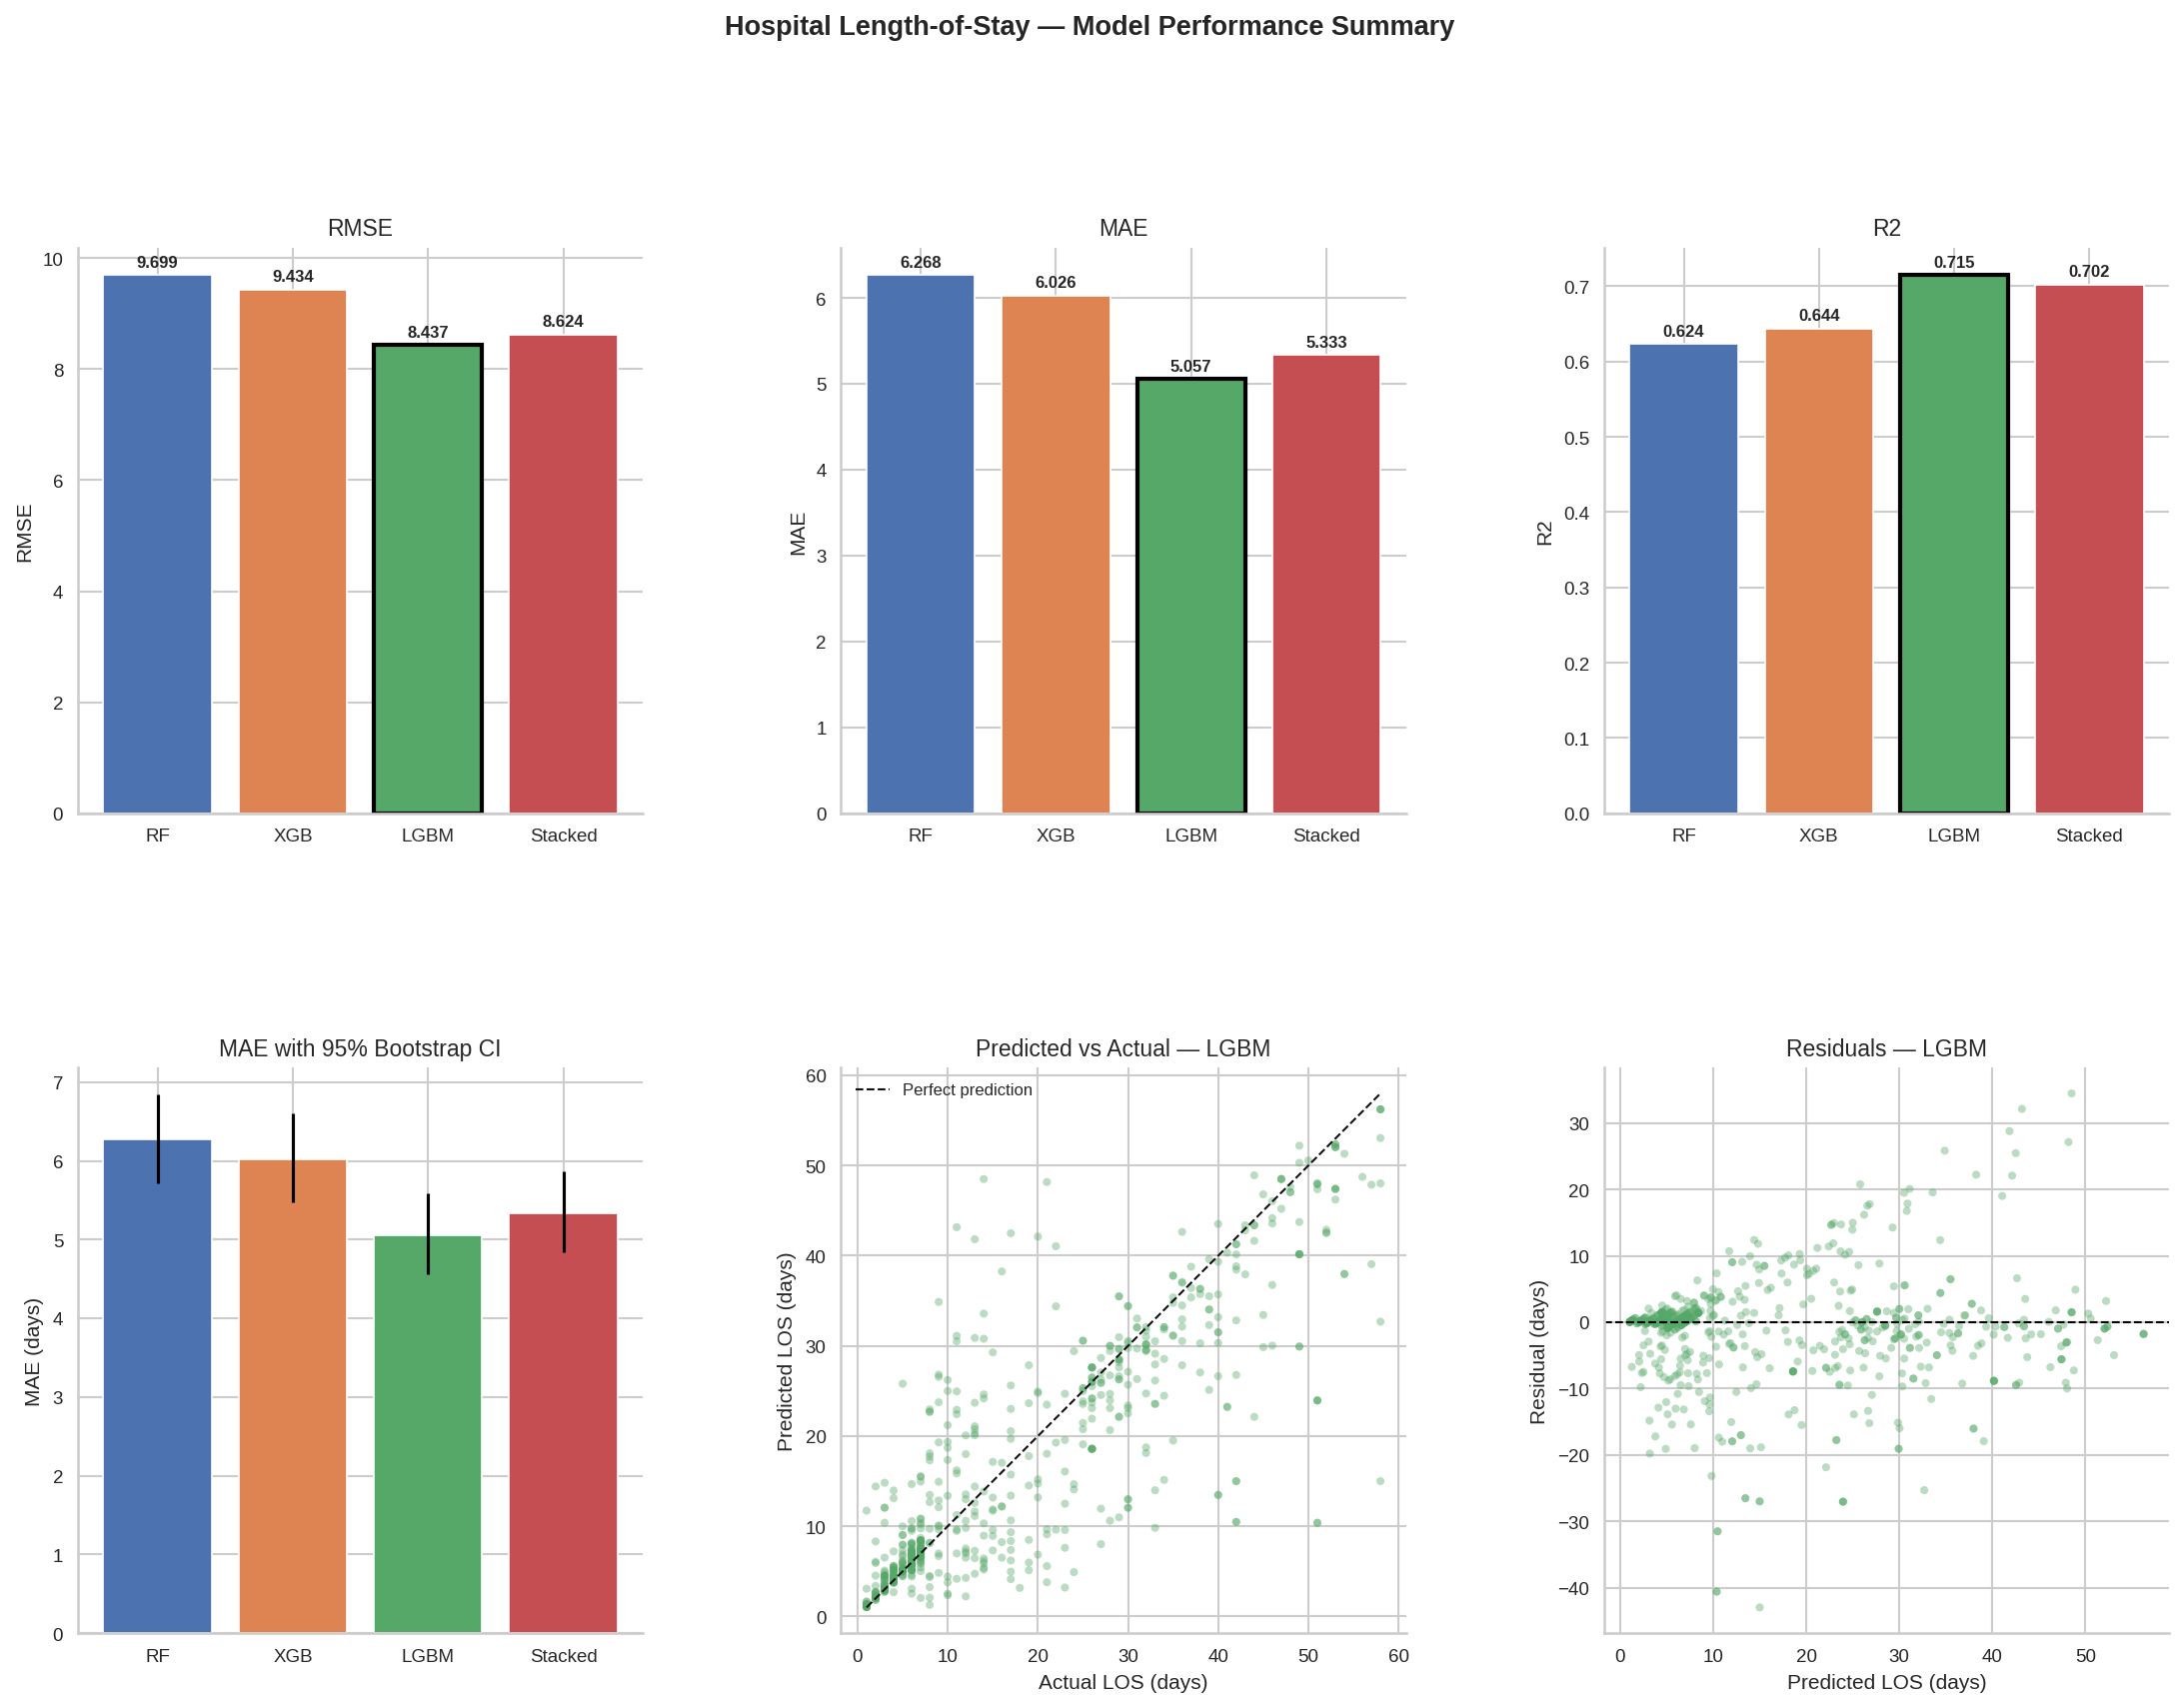

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/model_performance.png


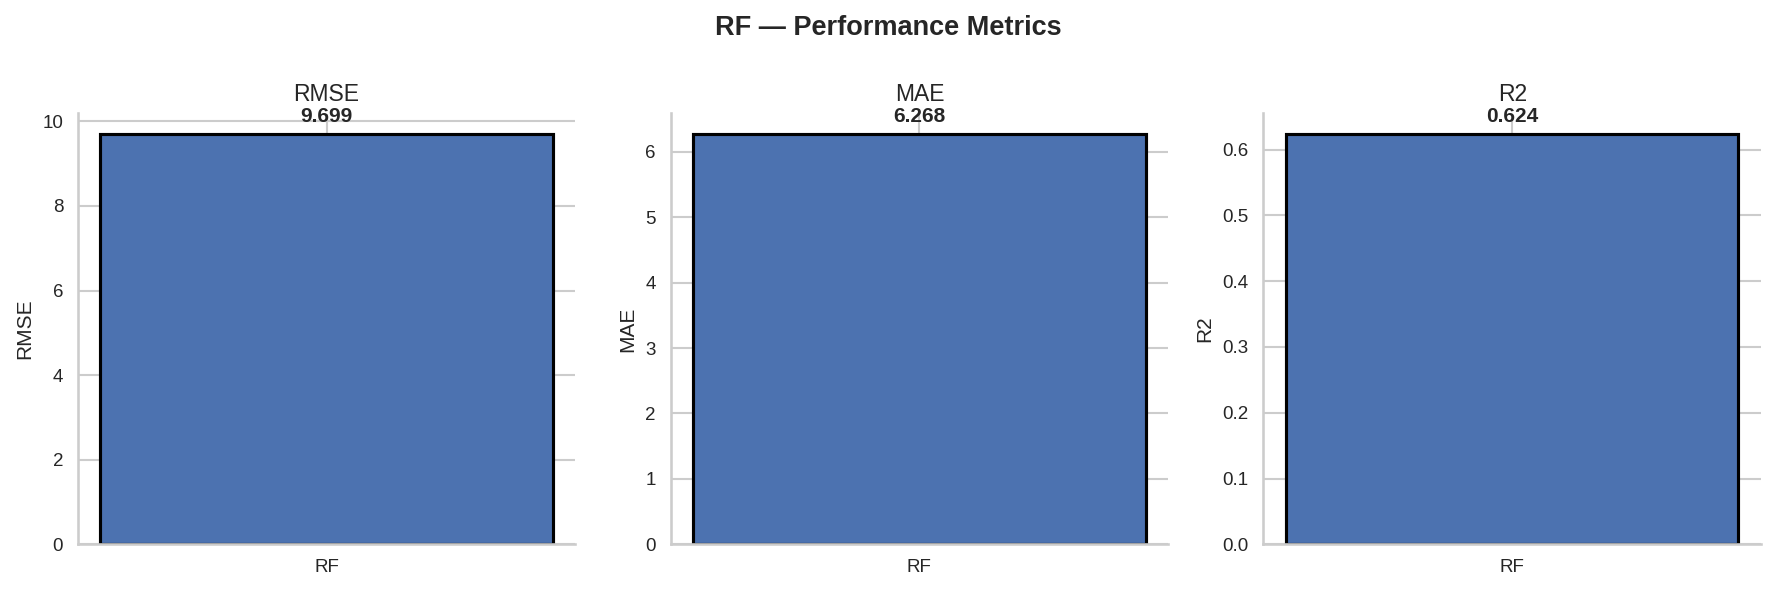

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/metrics_RF.png


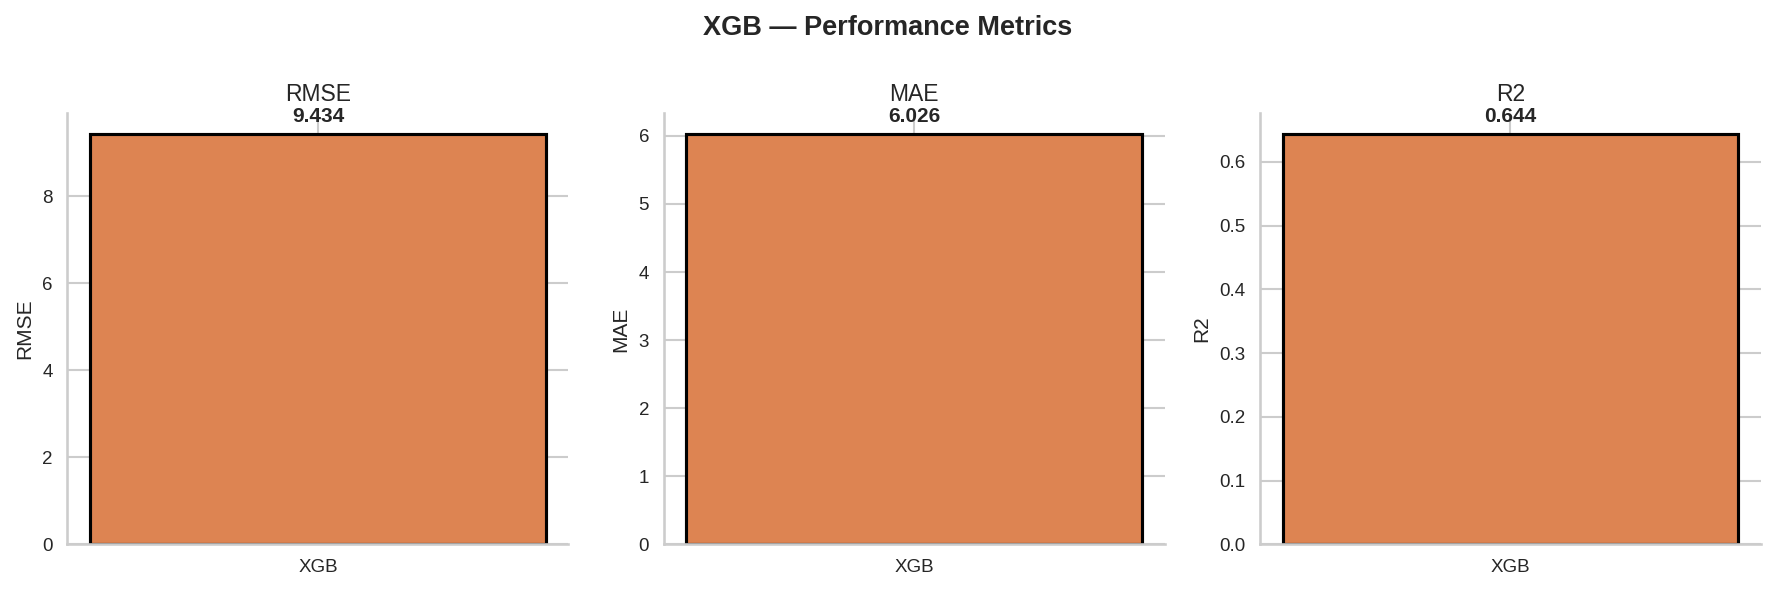

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/metrics_XGB.png


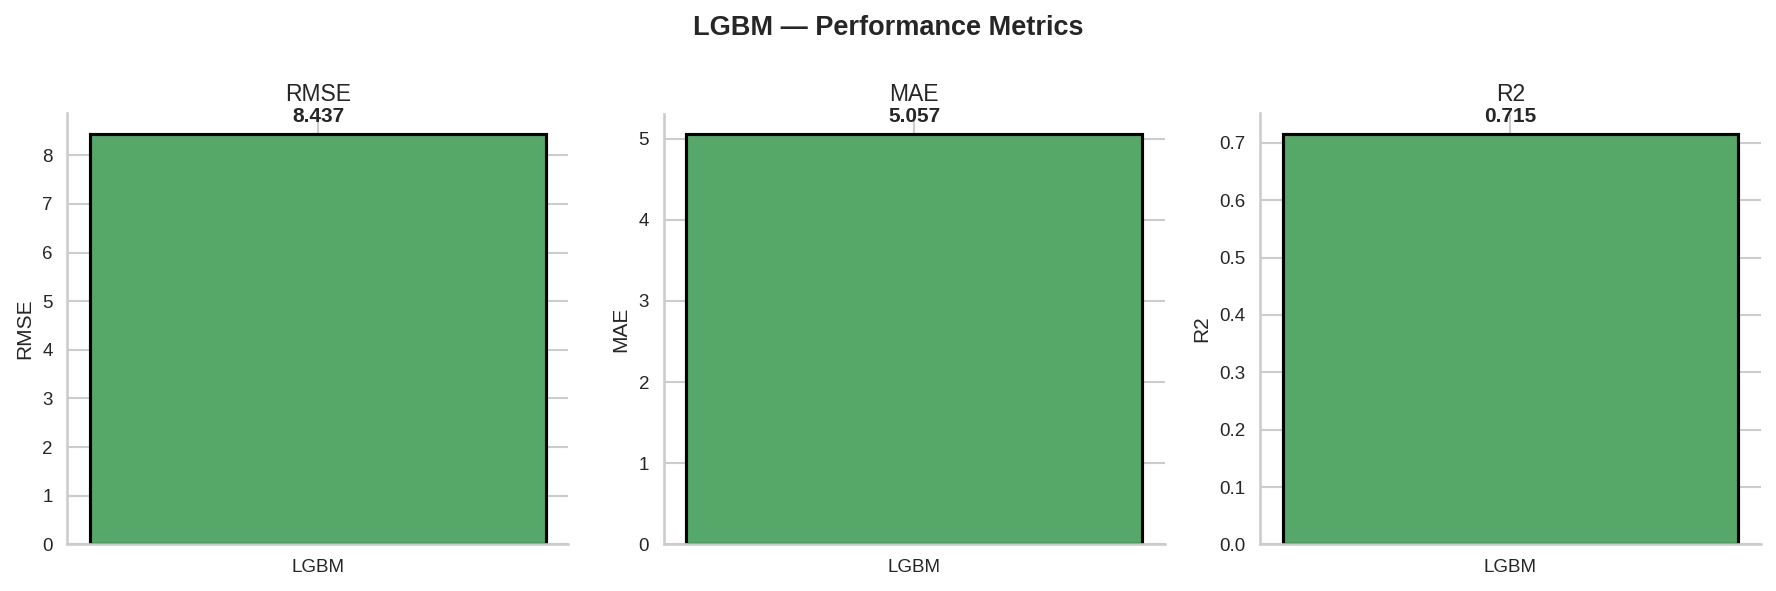

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/metrics_LGBM.png


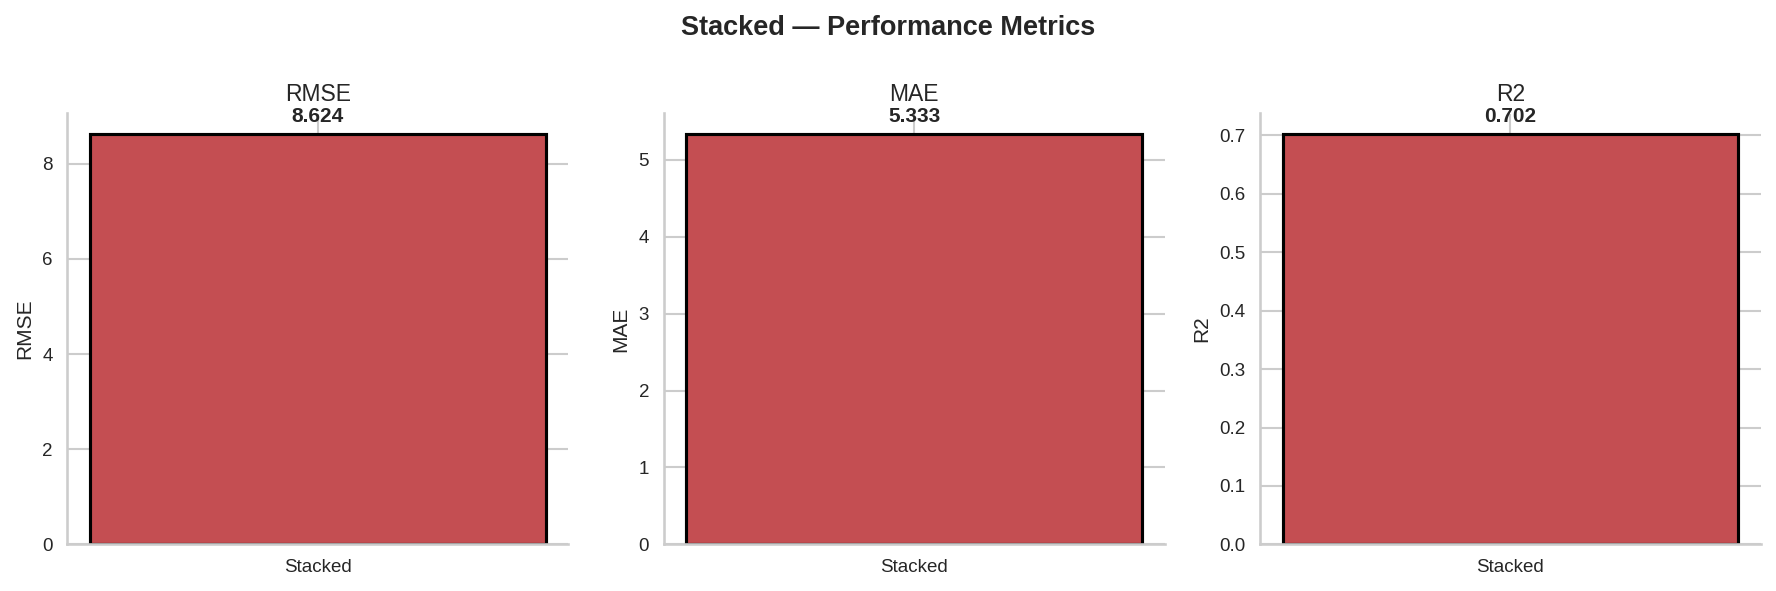

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/metrics_Stacked.png


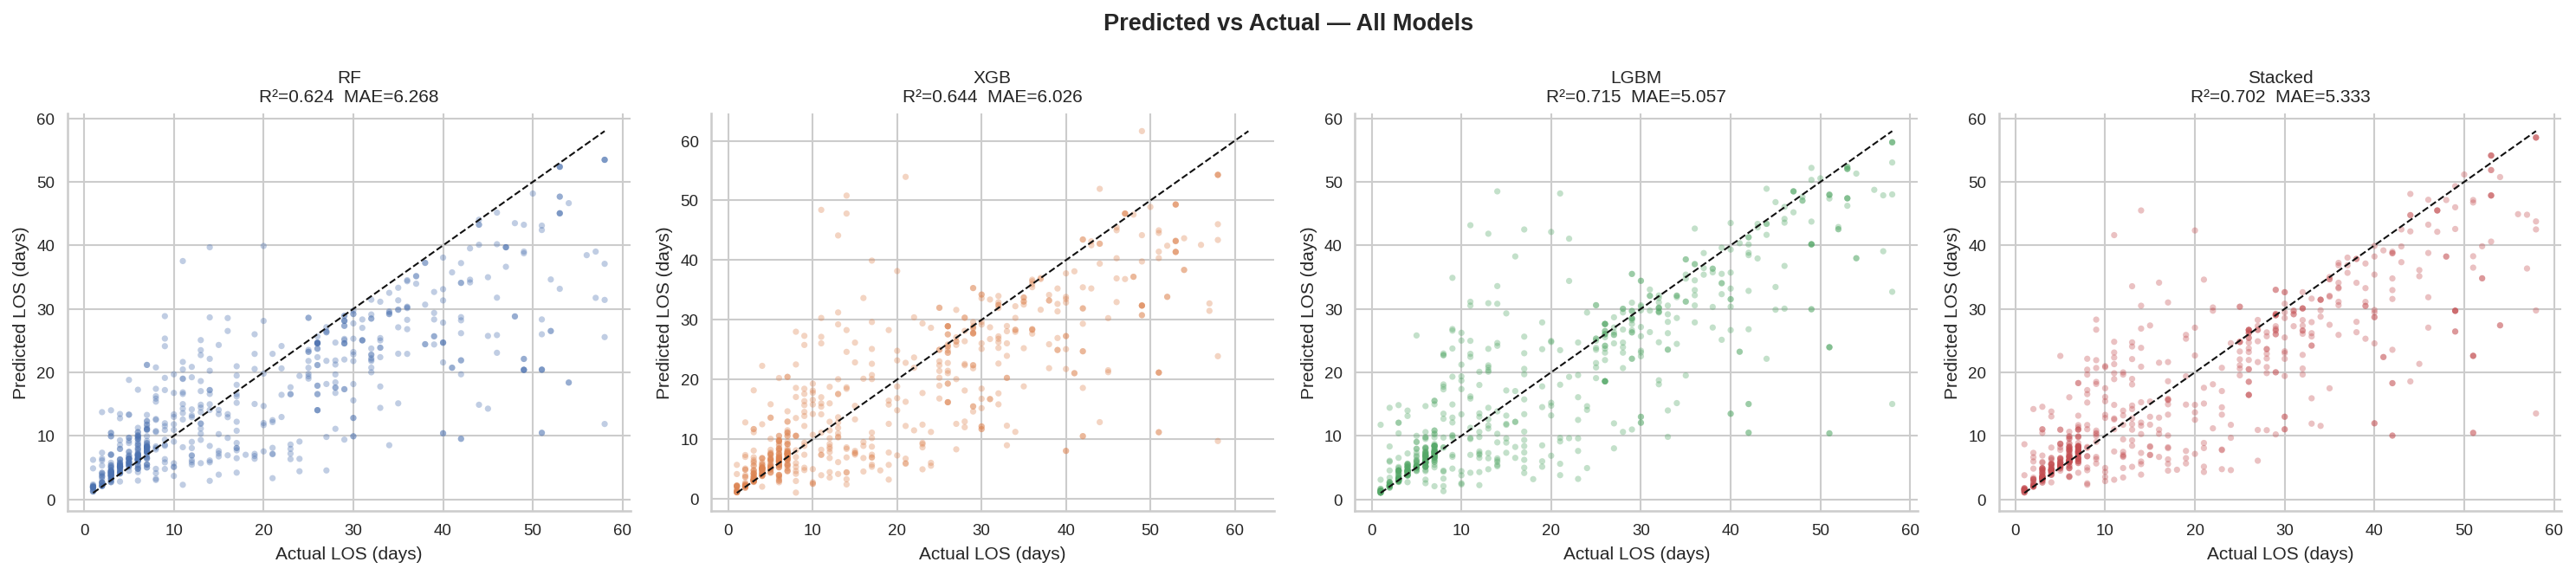

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/predicted_vs_actual_all.png


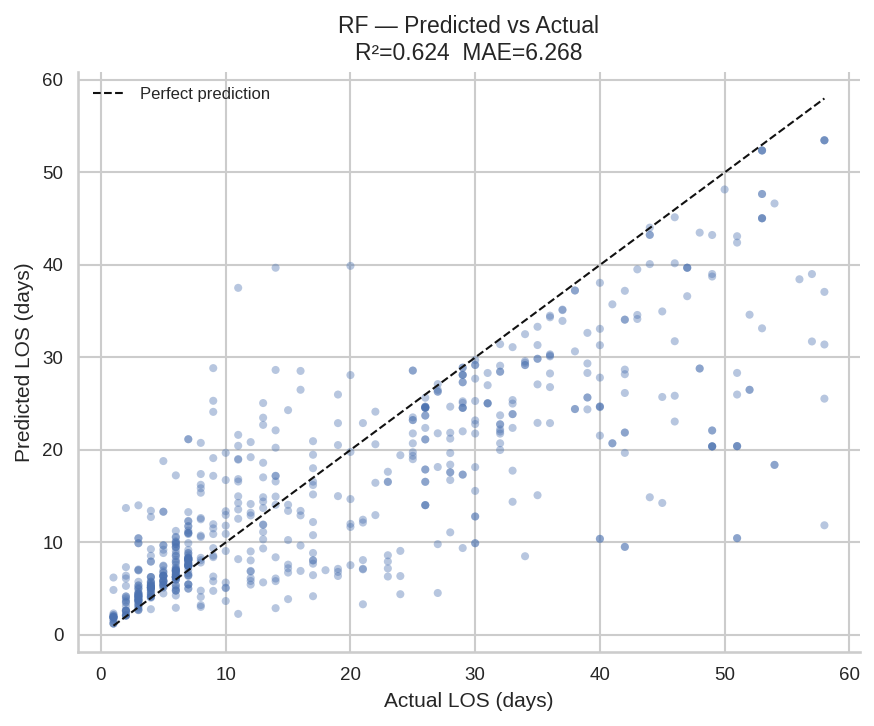

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/predicted_vs_actual_RF.png


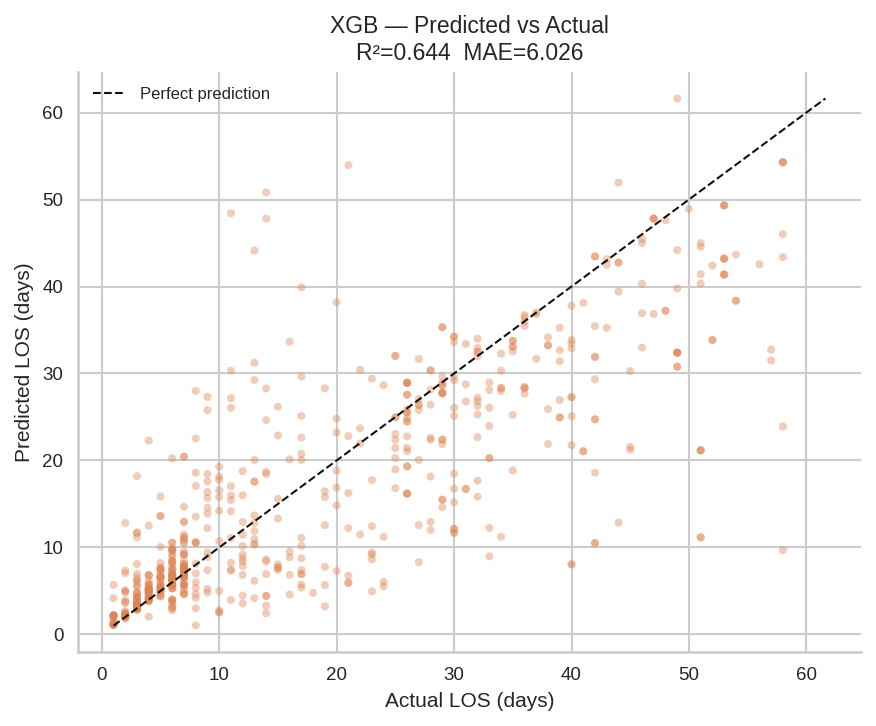

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/predicted_vs_actual_XGB.png


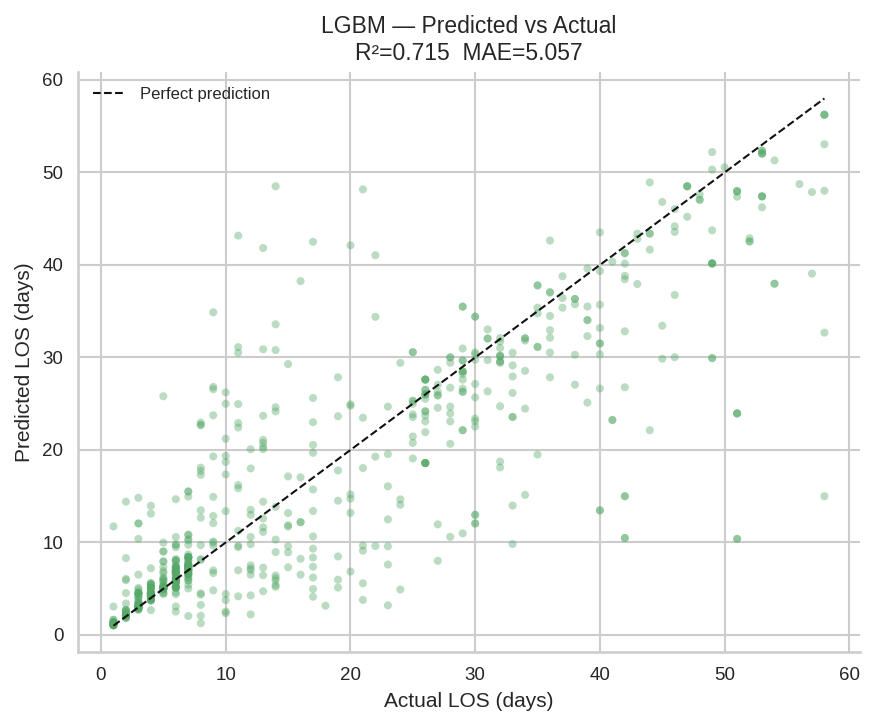

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/predicted_vs_actual_LGBM.png


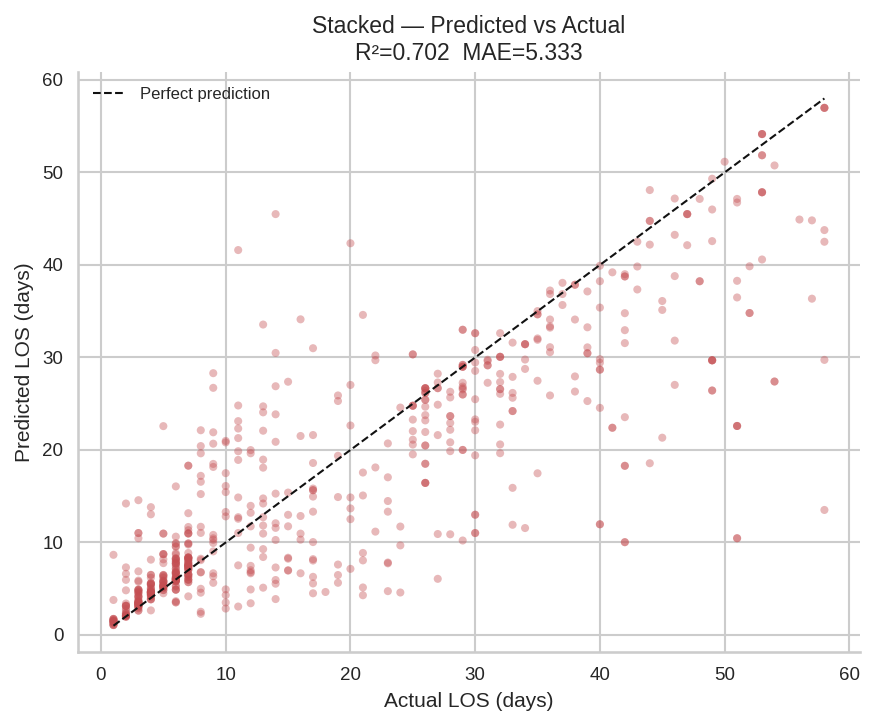

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/predicted_vs_actual_Stacked.png


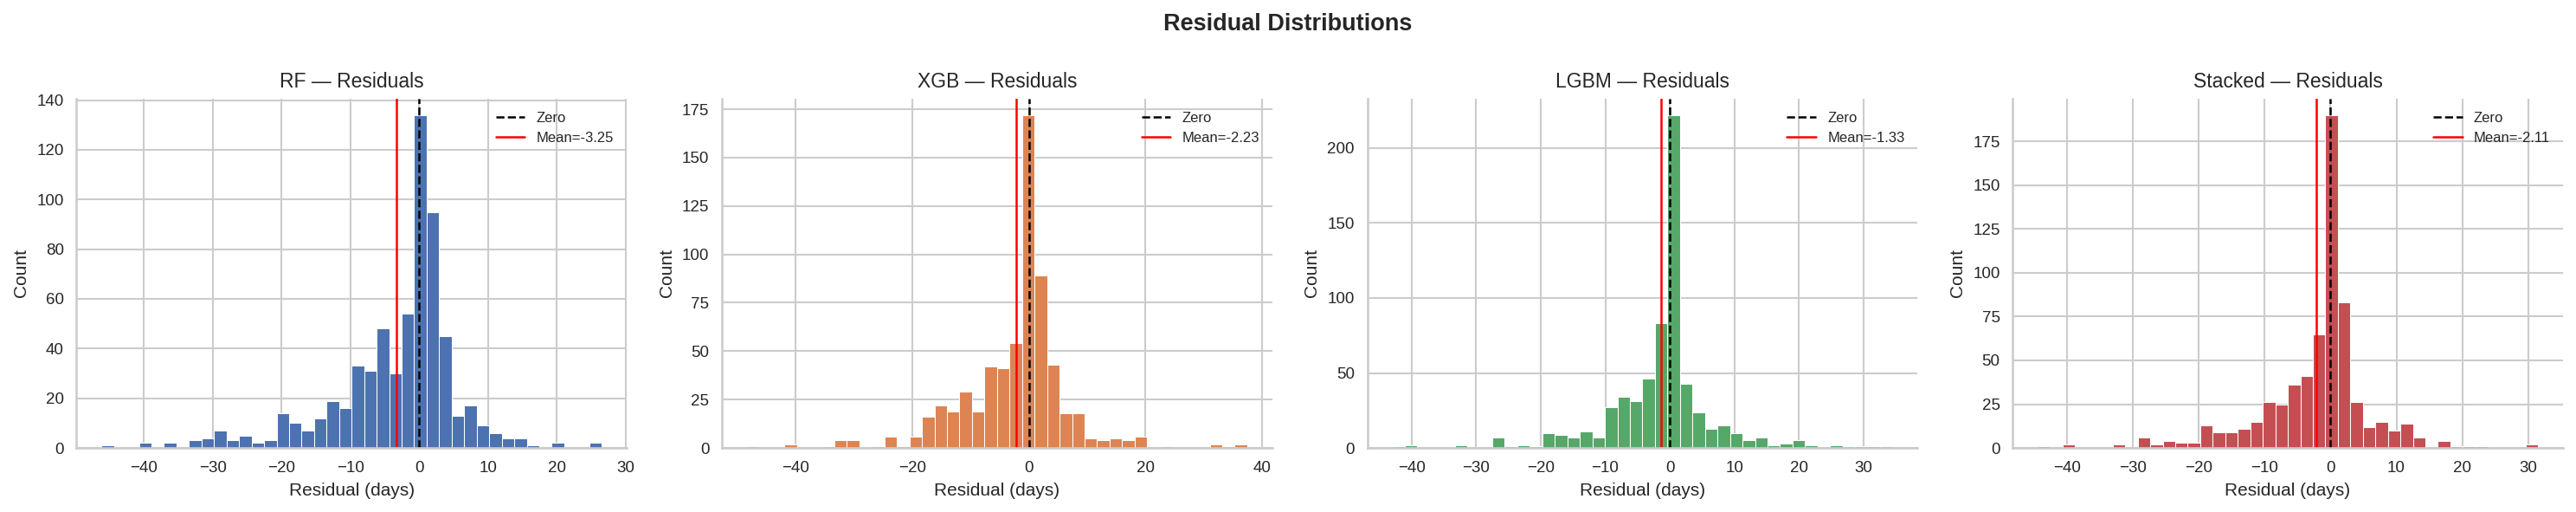

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/residual_distributions.png


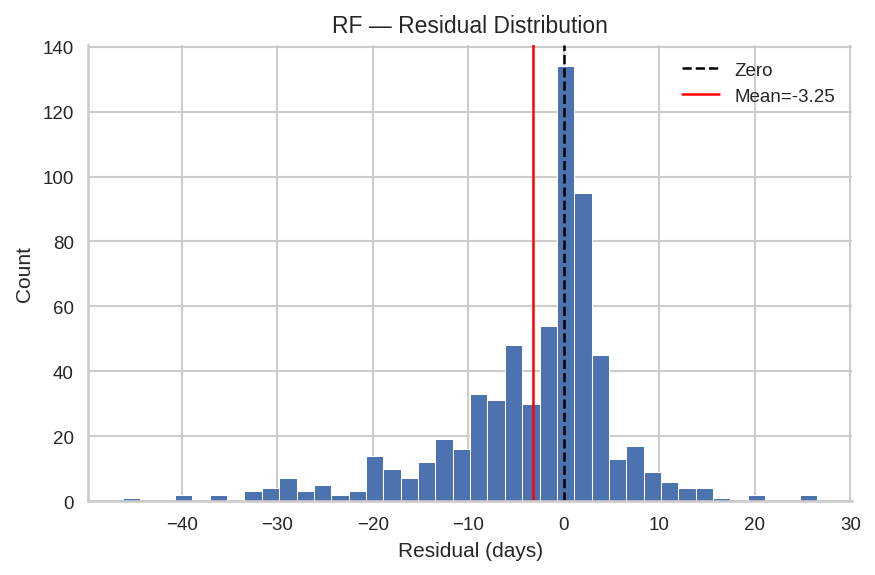

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/residuals_RF.png


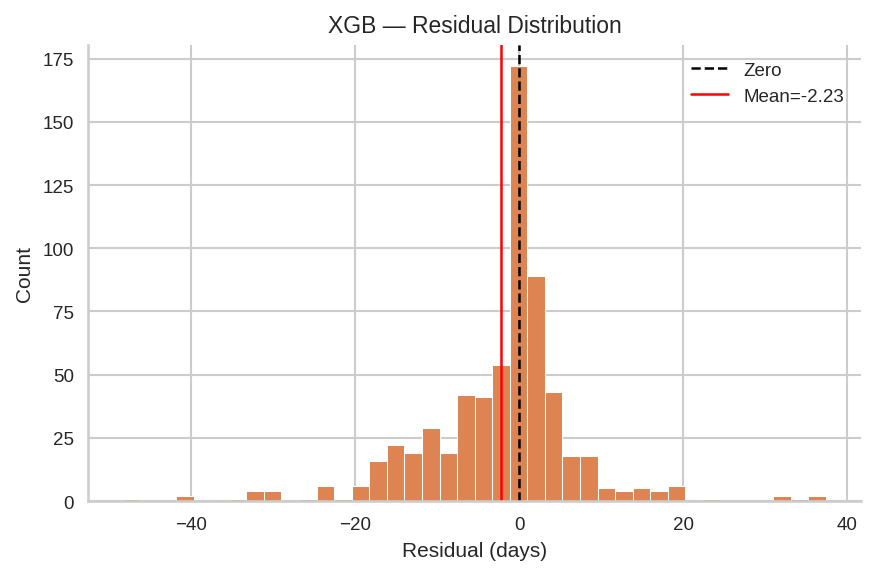

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/residuals_XGB.png


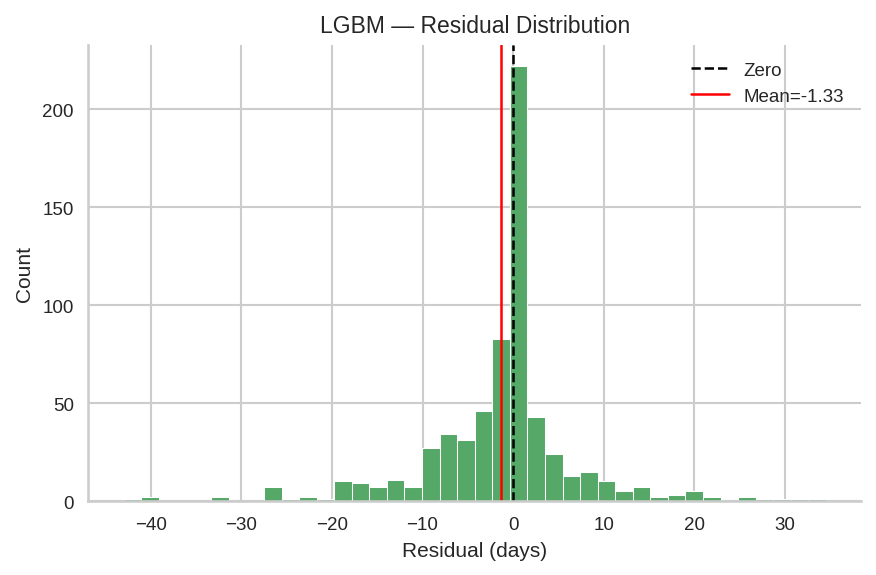

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/residuals_LGBM.png


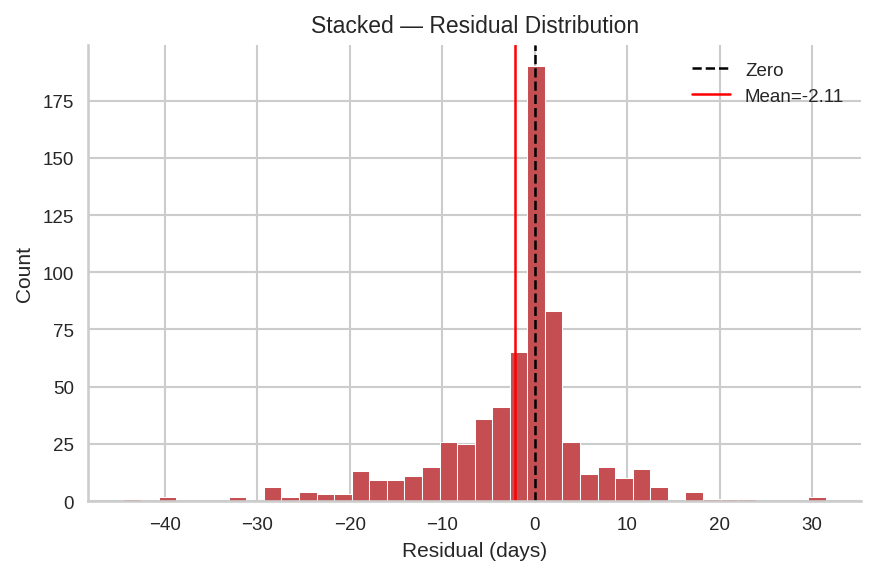

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/residuals_Stacked.png


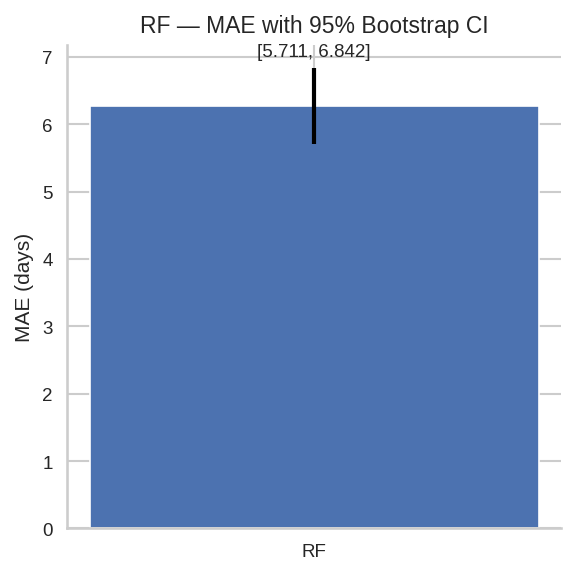

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/mae_ci_RF.png


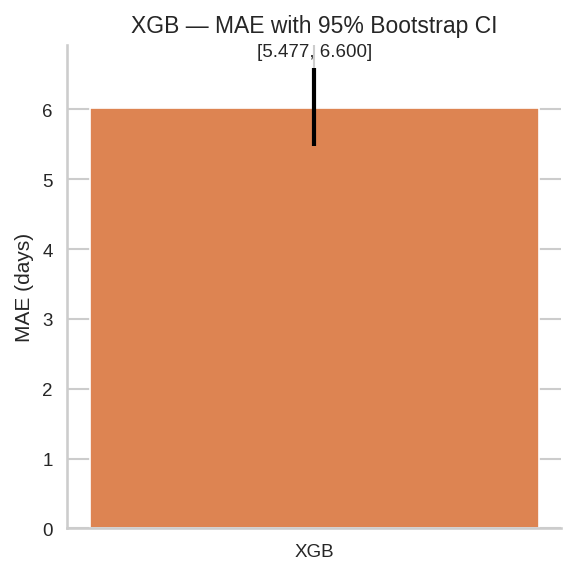

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/mae_ci_XGB.png


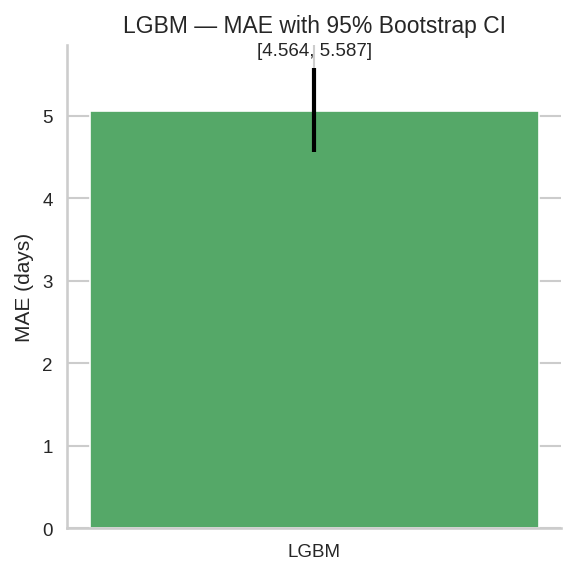

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/mae_ci_LGBM.png


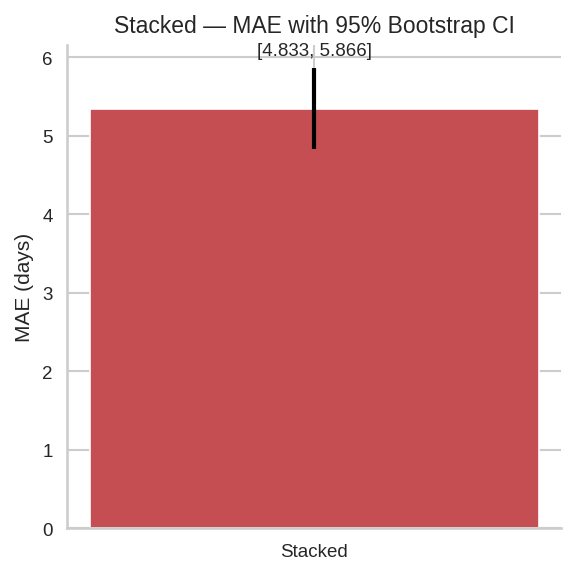

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/mae_ci_Stacked.png


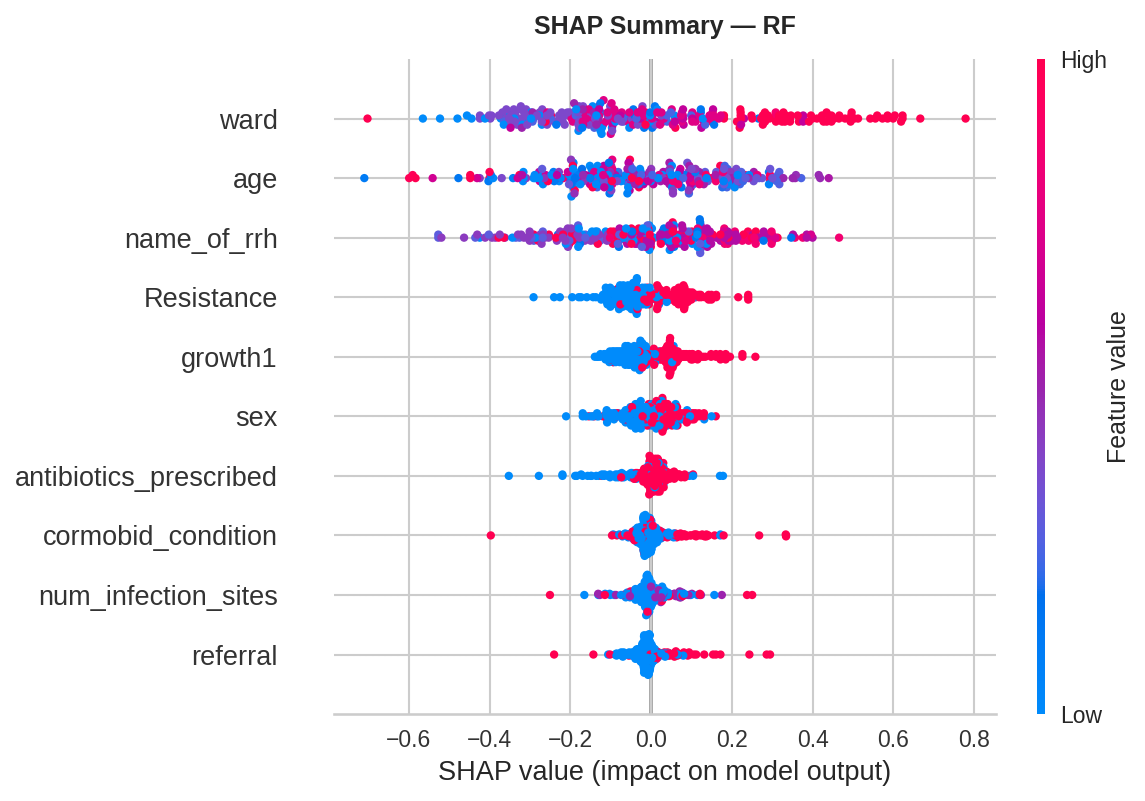

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/shap_summary_RF.png


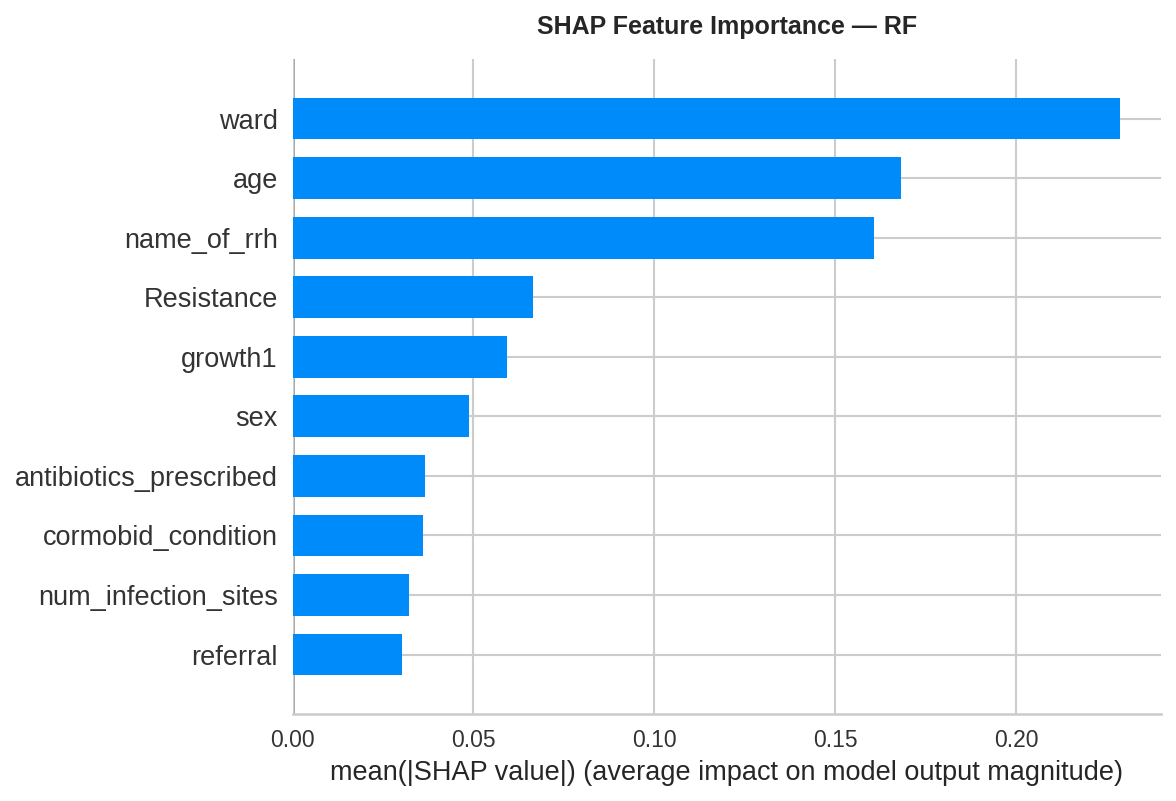

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/shap_importance_RF.png
SHAP failed for XGB: could not convert string to float: '[2.599275E0]'


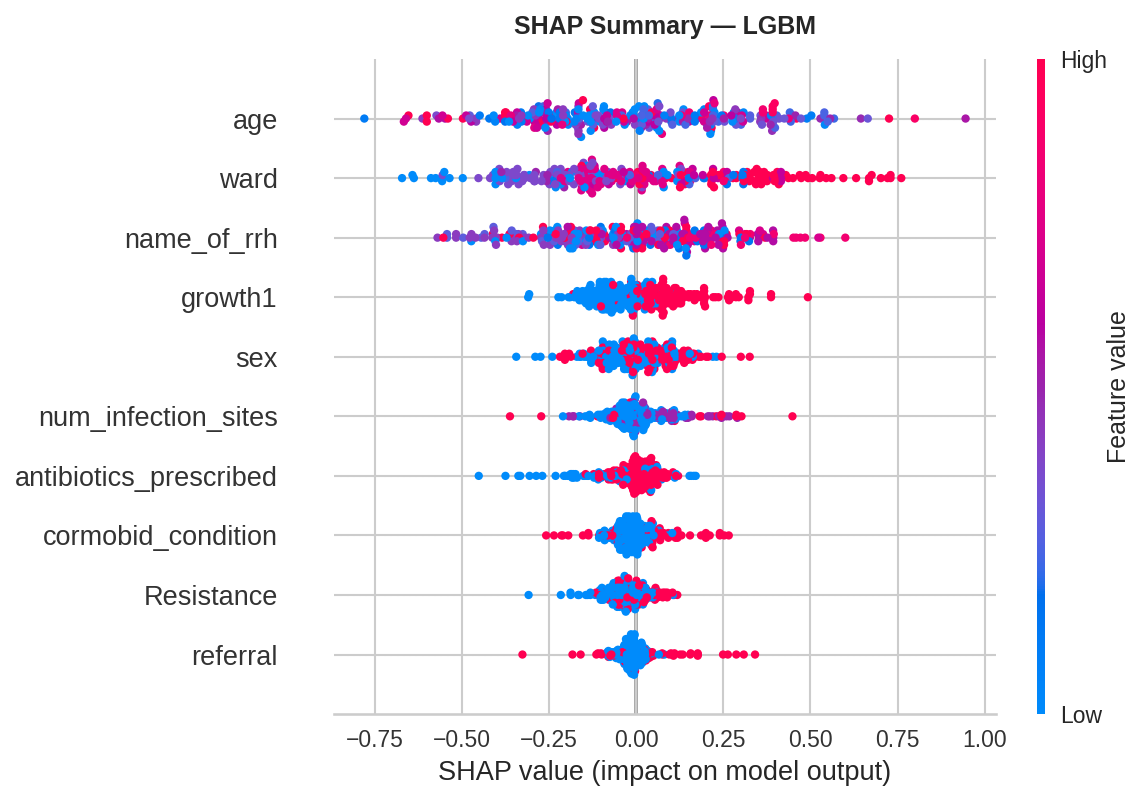

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/shap_summary_LGBM.png


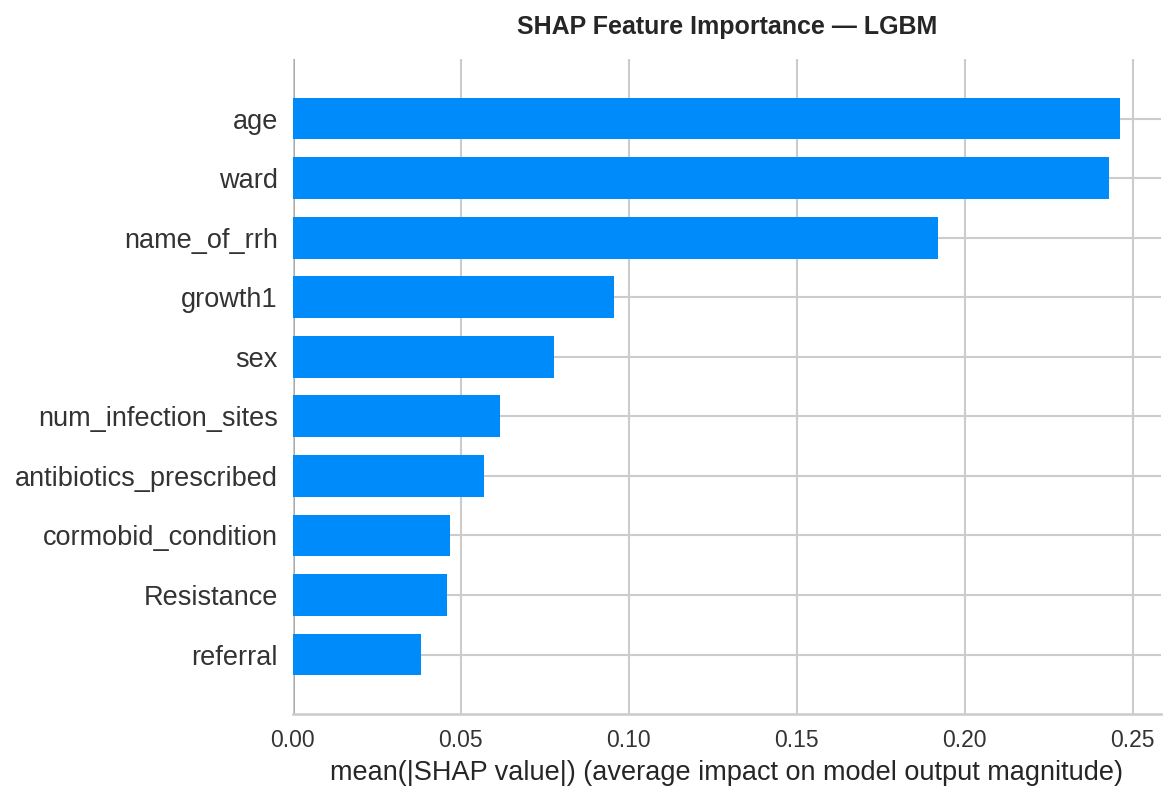

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/shap_importance_LGBM.png

ALL OUTPUTS SAVED TO: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/
  BEST_MODEL.joblib                                       1.1 KB
  BEST_MODEL_info.joblib                                  0.5 KB
  BEST_MODEL_summary.txt                                  0.7 KB
  best_model.joblib                                    4477.3 KB
  best_model_info.joblib                                  0.4 KB
  best_model_summary.txt                                  0.6 KB
  mae_ci_LGBM.png                                        19.9 KB
  mae_ci_RF.png                                          18.9 KB
  mae_ci_Stacked.png                                     22.6 KB
  mae_ci_XGB.png                                         20.7 KB
  metrics_LGBM.png                                       36.1 KB
  metrics_RF.png                                         33.7 KB
  metrics_Stacked.png                               

<Figure size 800x550 with 0 Axes>

In [55]:
# Run the ML pipeline
%run -i "Scripts/machine_learning_pipeline.py"

RF best params: {'model__max_depth': None, 'model__min_samples_leaf': 2, 'model__n_estimators': 600}
XGB best params: {'model__colsample_bytree': 1.0, 'model__learning_rate': 0.05, 'model__max_depth': 5, 'model__min_child_weight': 5, 'model__n_estimators': 1000, 'model__subsample': 0.8}
LGBM best params: {'model__learning_rate': 0.05, 'model__n_estimators': 800, 'model__num_leaves': 63}
GB best params: {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 500, 'model__subsample': 0.8}
ElasticNet best params: {'model__alpha': 0.001, 'model__l1_ratio': 0.2}
SVR best params: {'model__C': 5.0, 'model__epsilon': 0.05, 'model__kernel': 'rbf'}
CatBoost best params: {'model__depth': 6, 'model__iterations': 800, 'model__learning_rate': 0.05}
Saved base model: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/model_RF.joblib
Saved base model: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/model_XGB.joblib
Saved base model: /home/kyomukama/ACE/camonet/ML_Reru

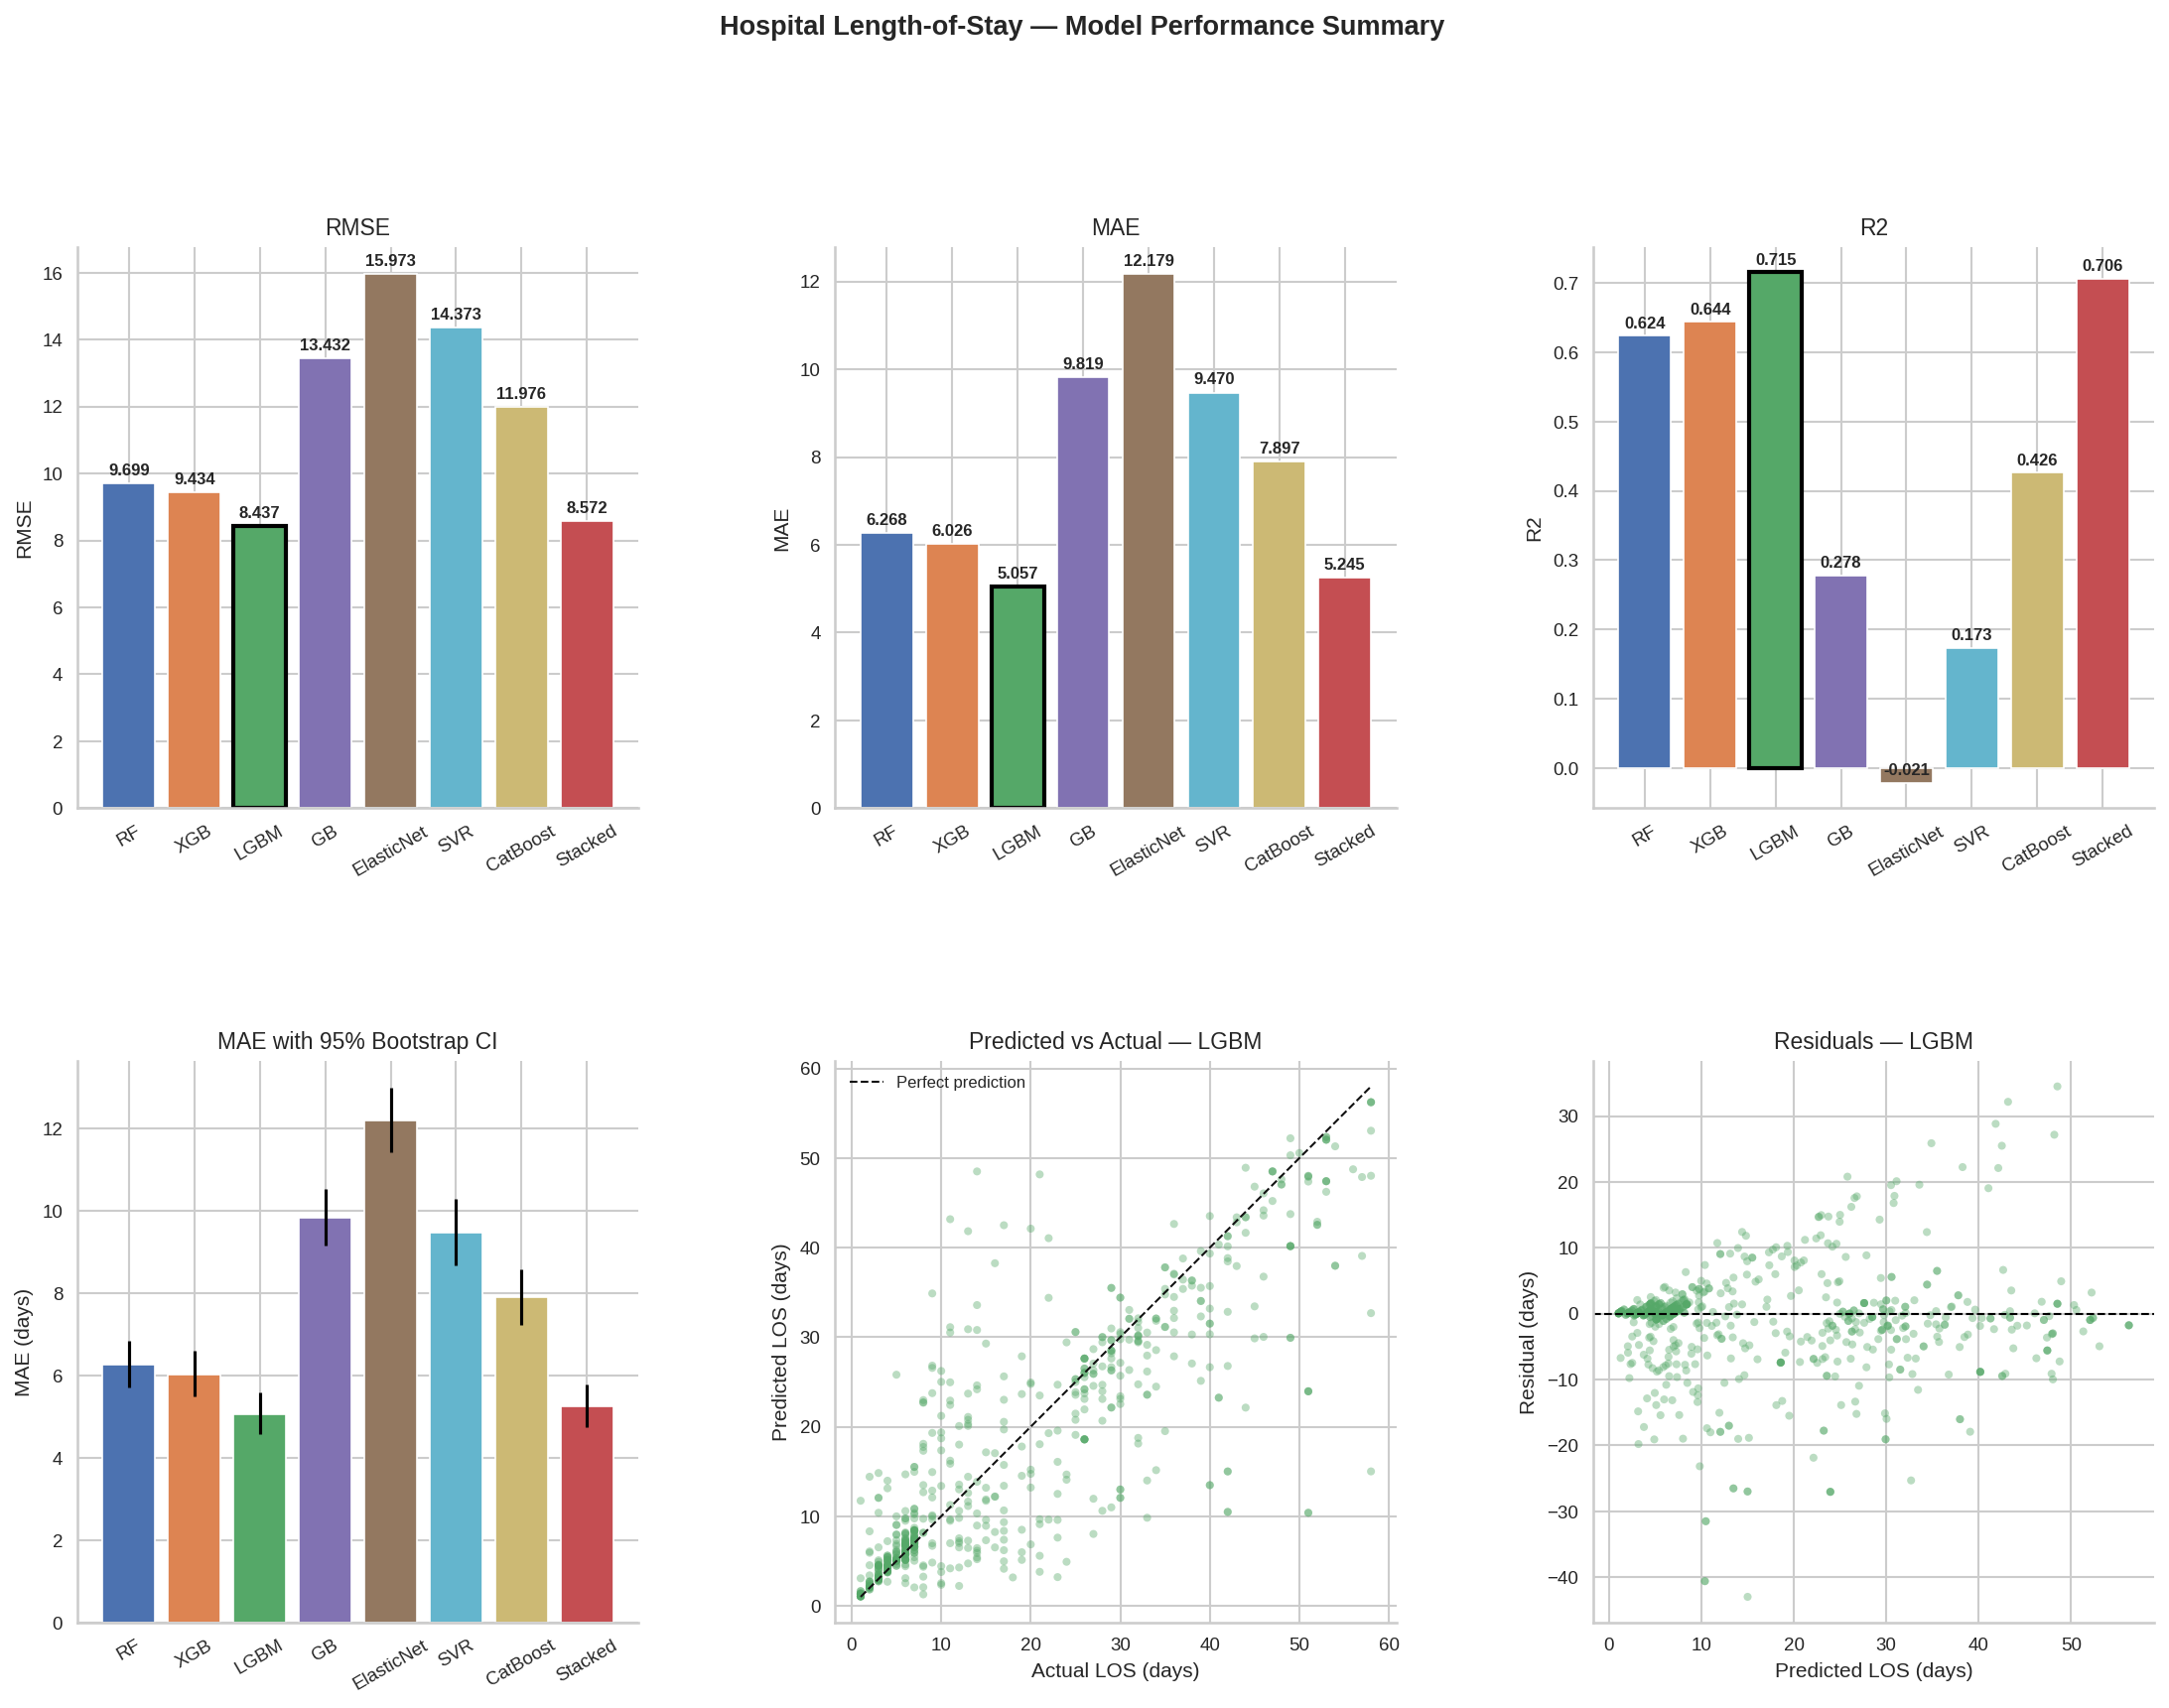

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/model_performance.png


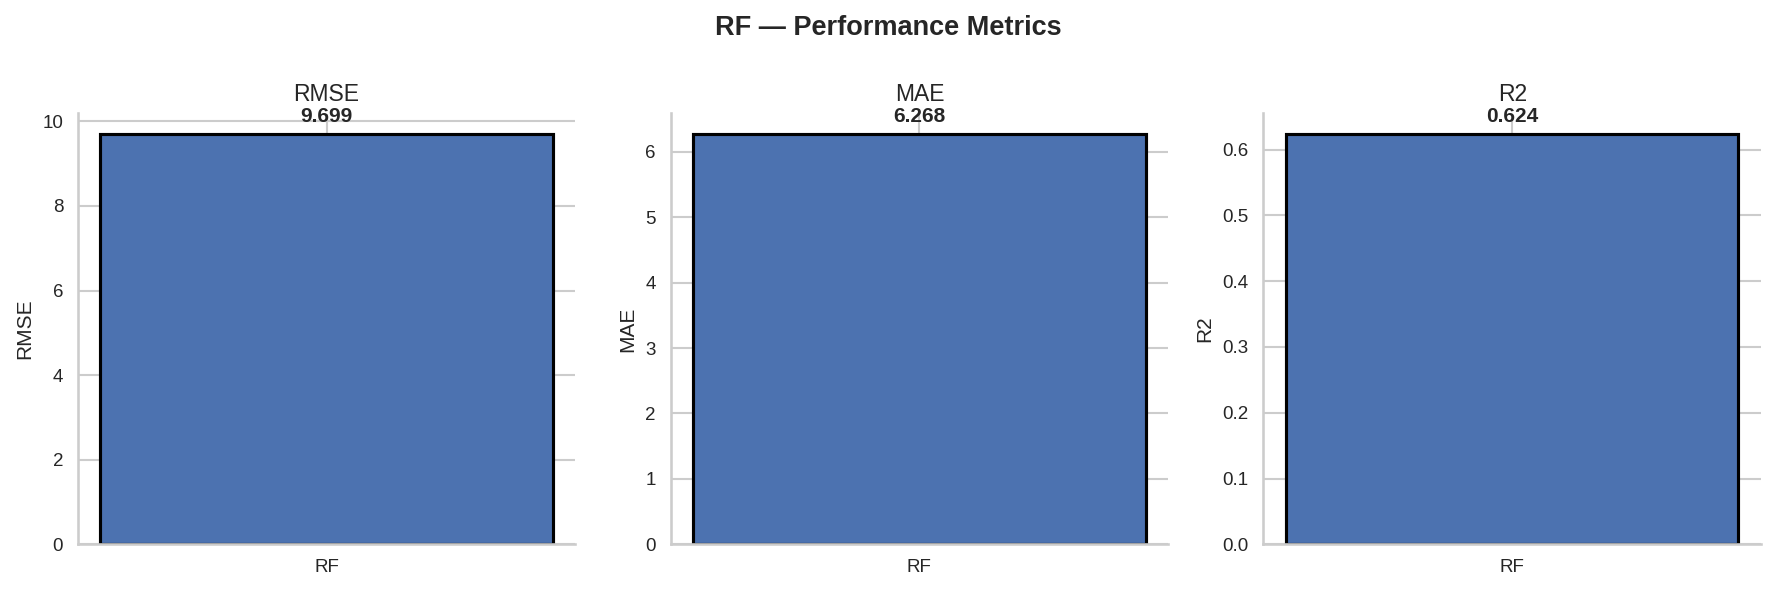

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/metrics_RF.png


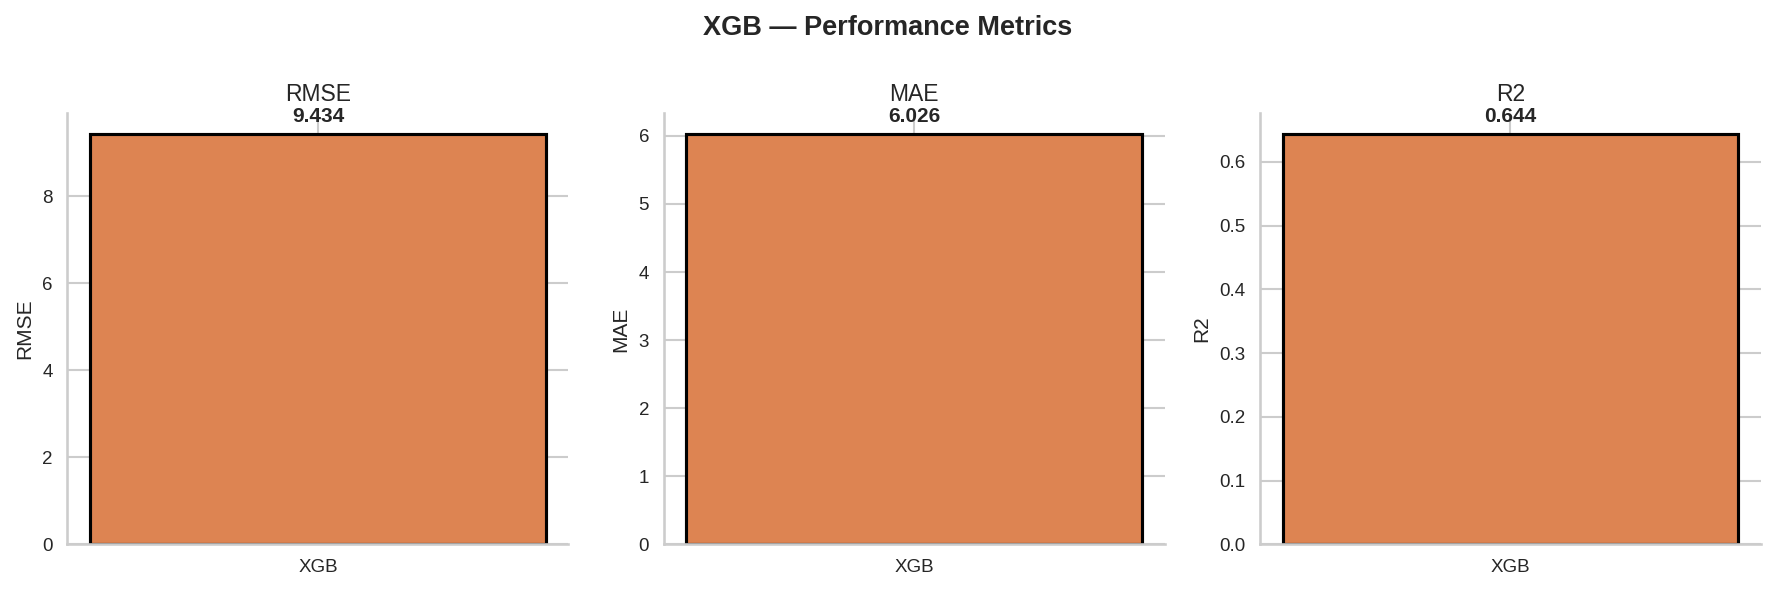

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/metrics_XGB.png


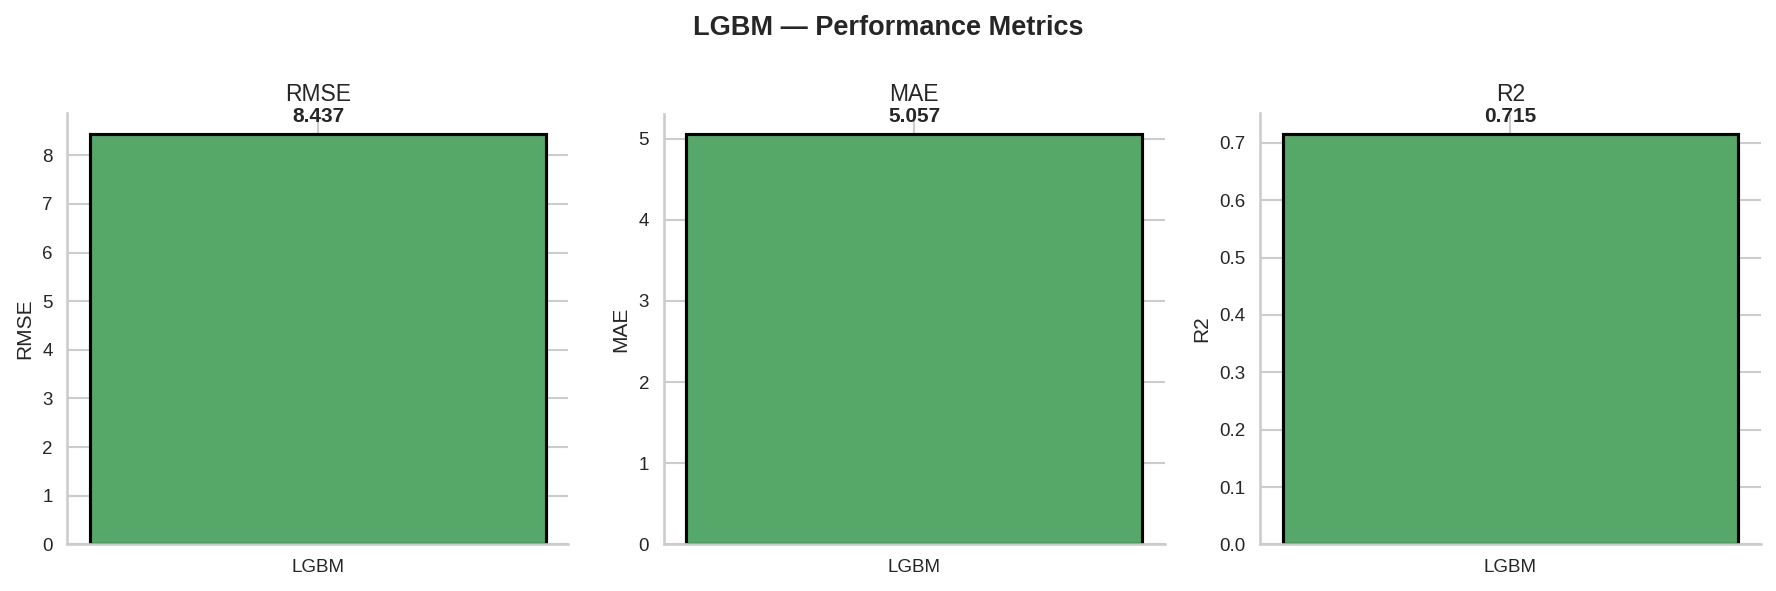

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/metrics_LGBM.png


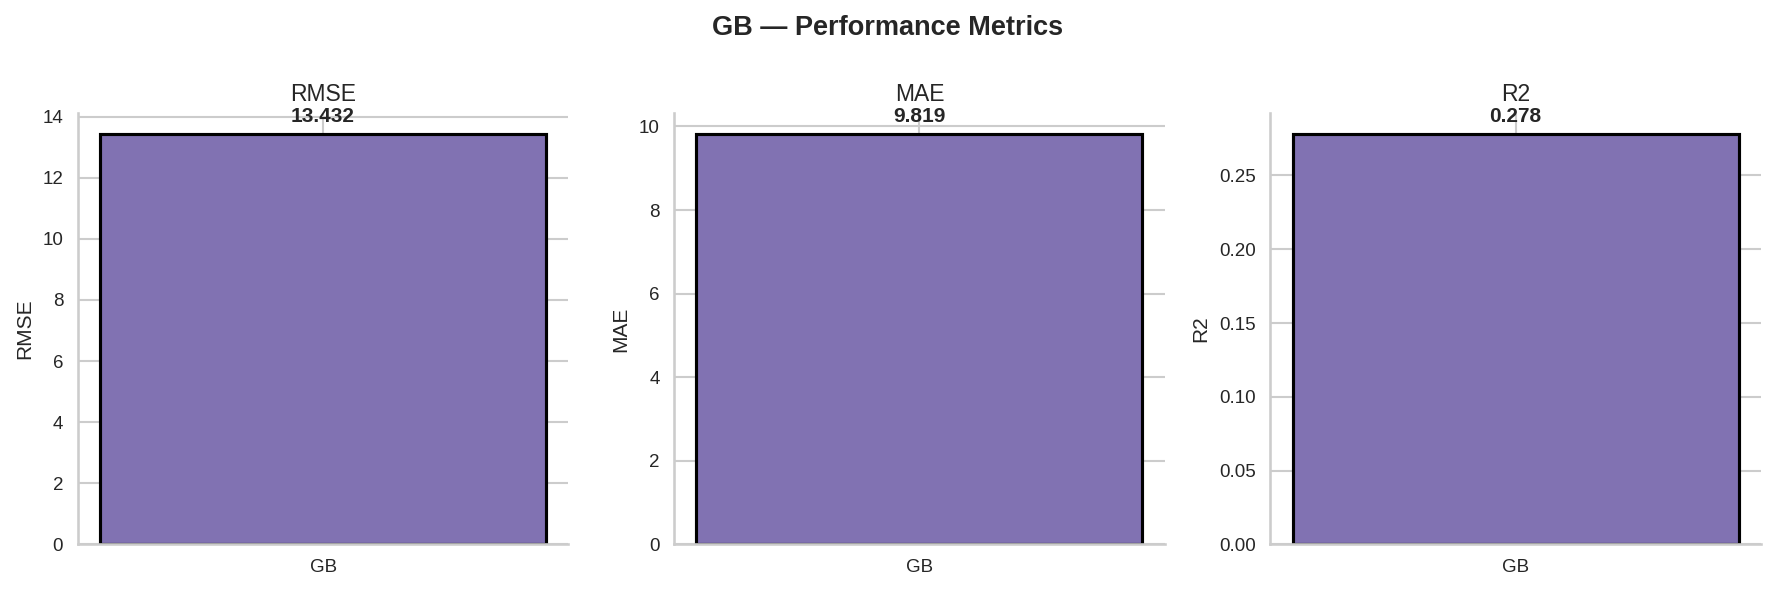

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/metrics_GB.png


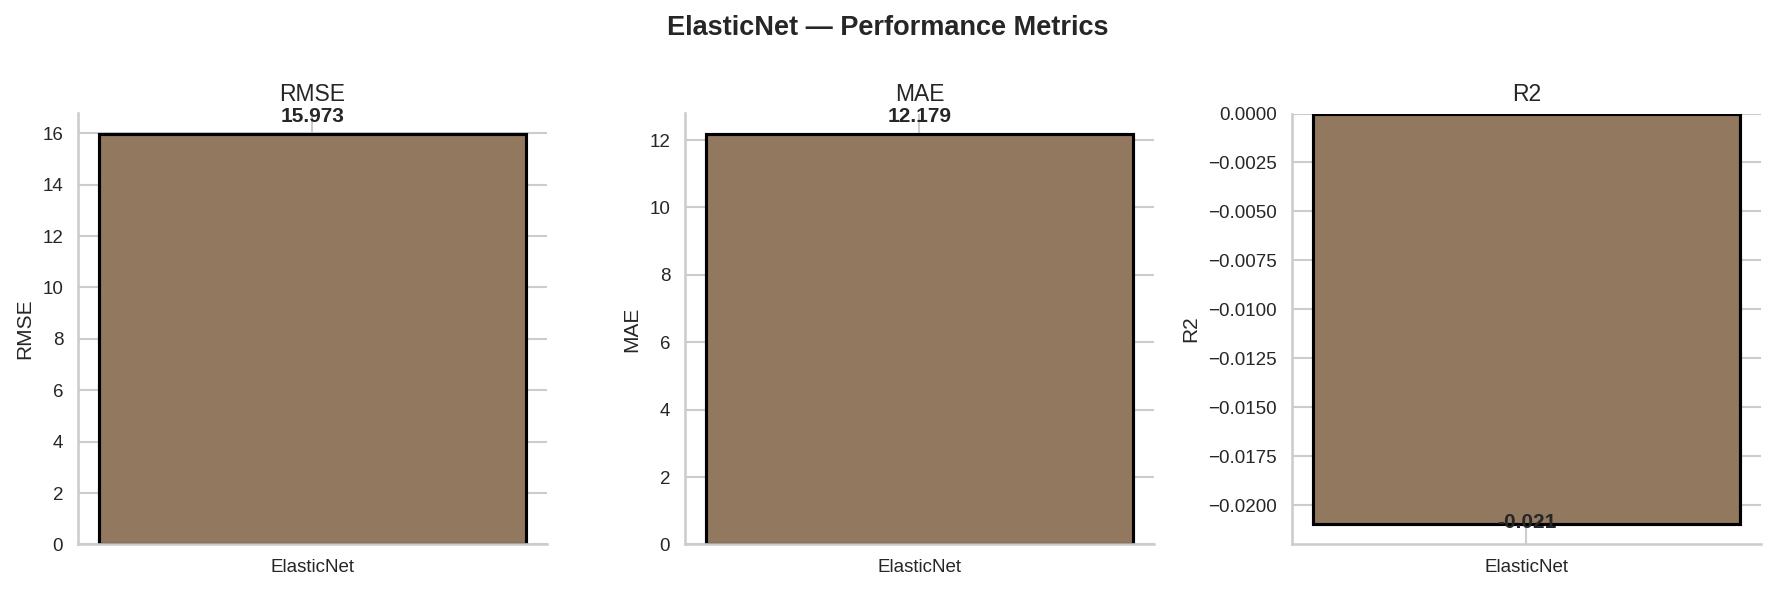

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/metrics_ElasticNet.png


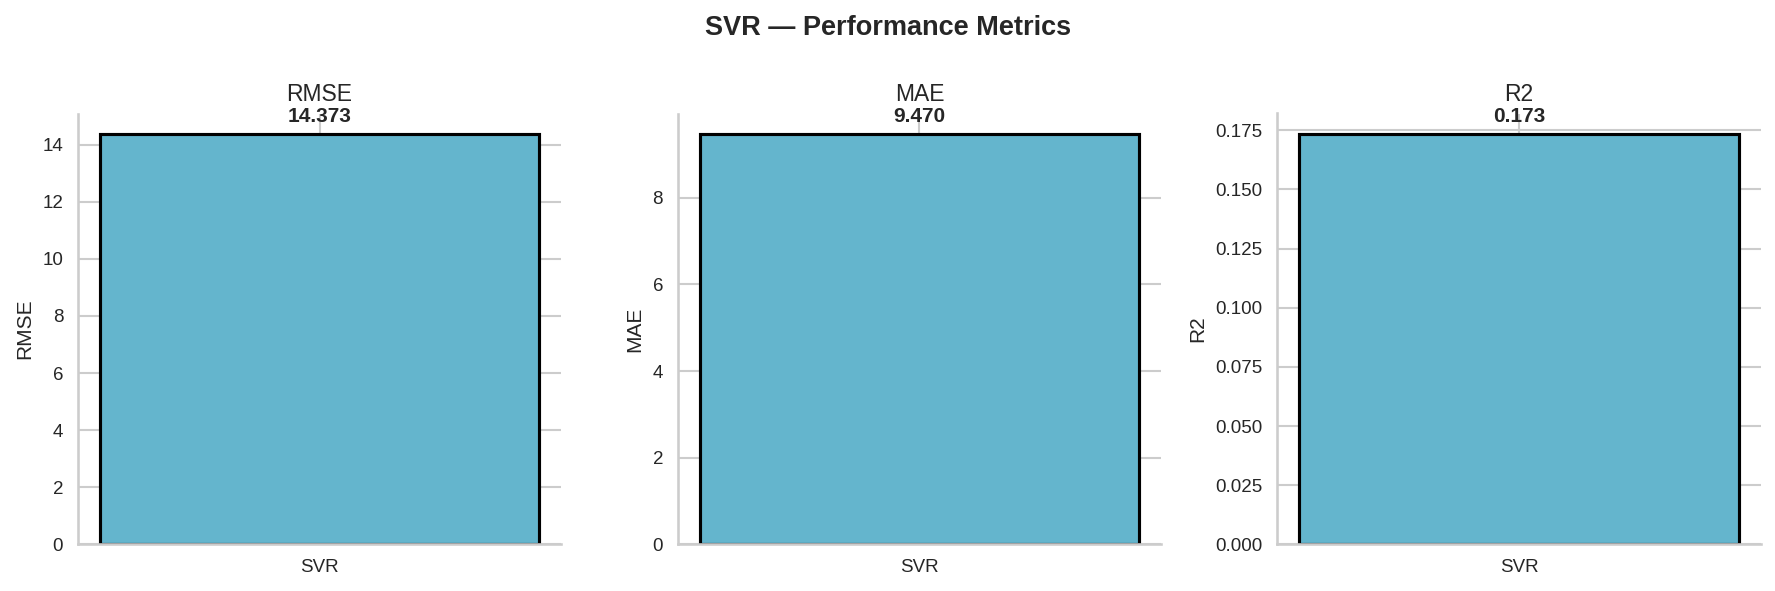

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/metrics_SVR.png


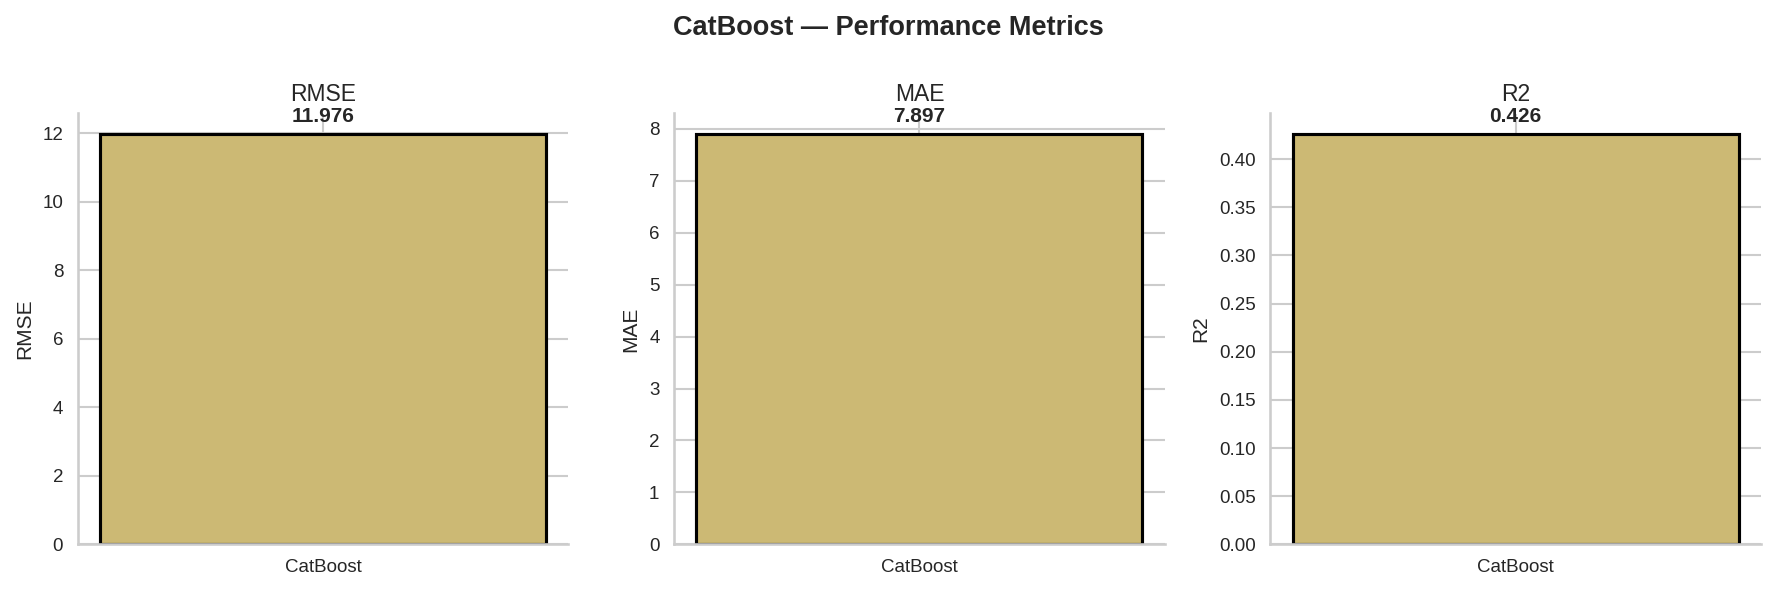

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/metrics_CatBoost.png


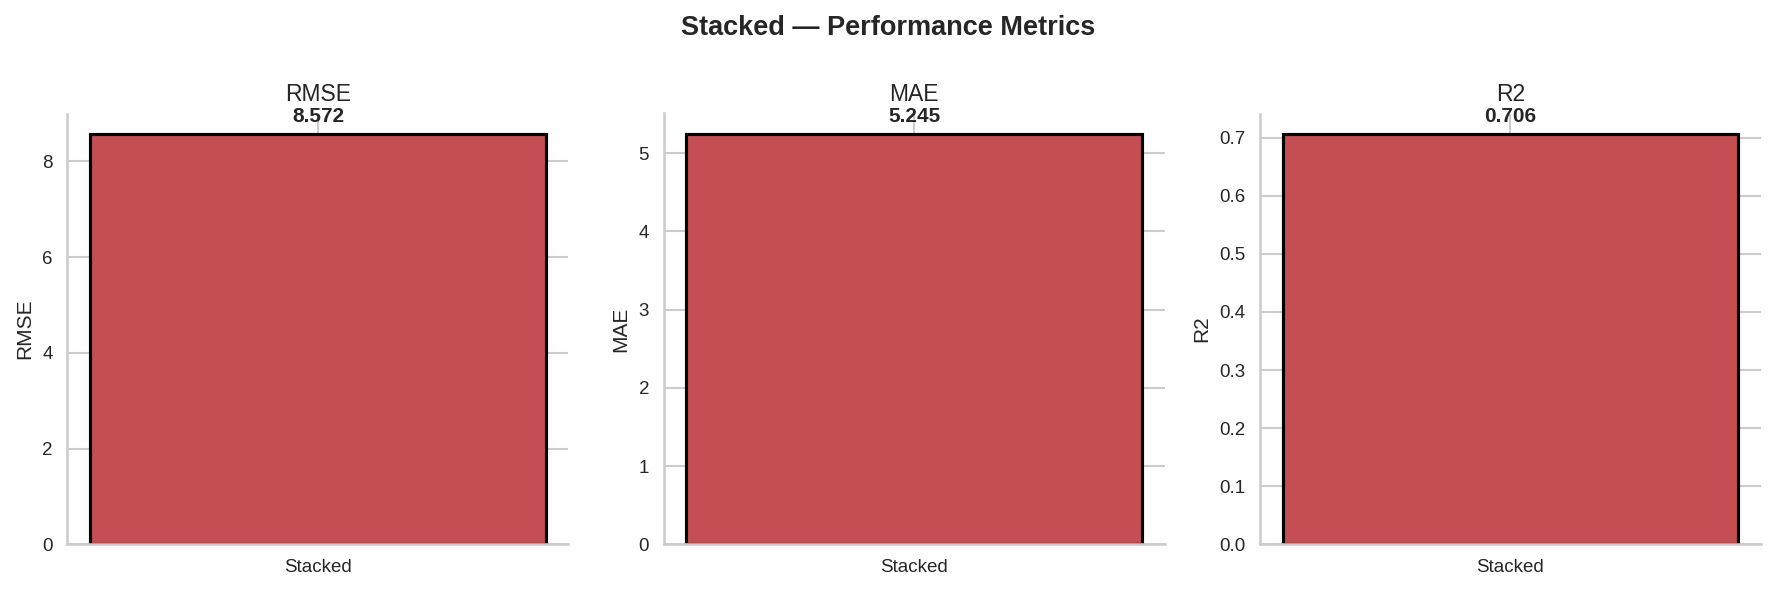

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/metrics_Stacked.png


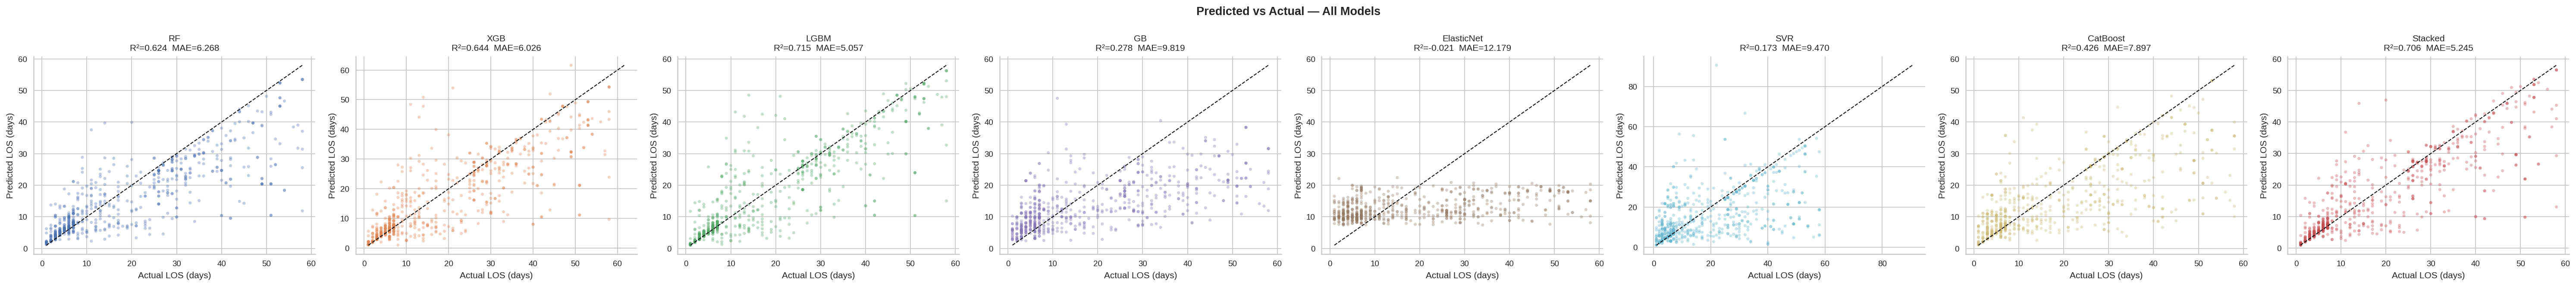

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/predicted_vs_actual_all.png


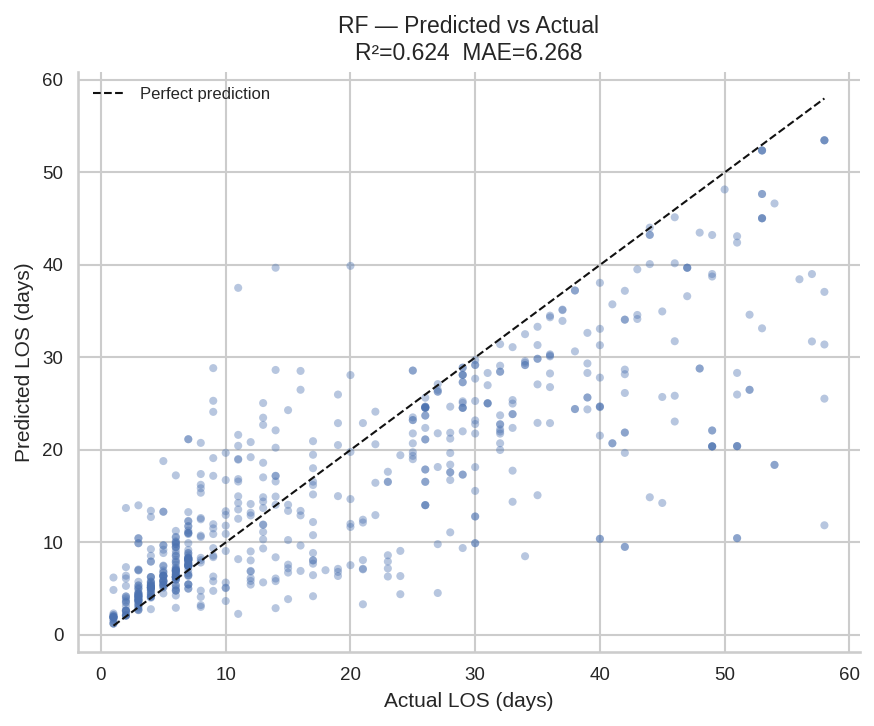

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/predicted_vs_actual_RF.png


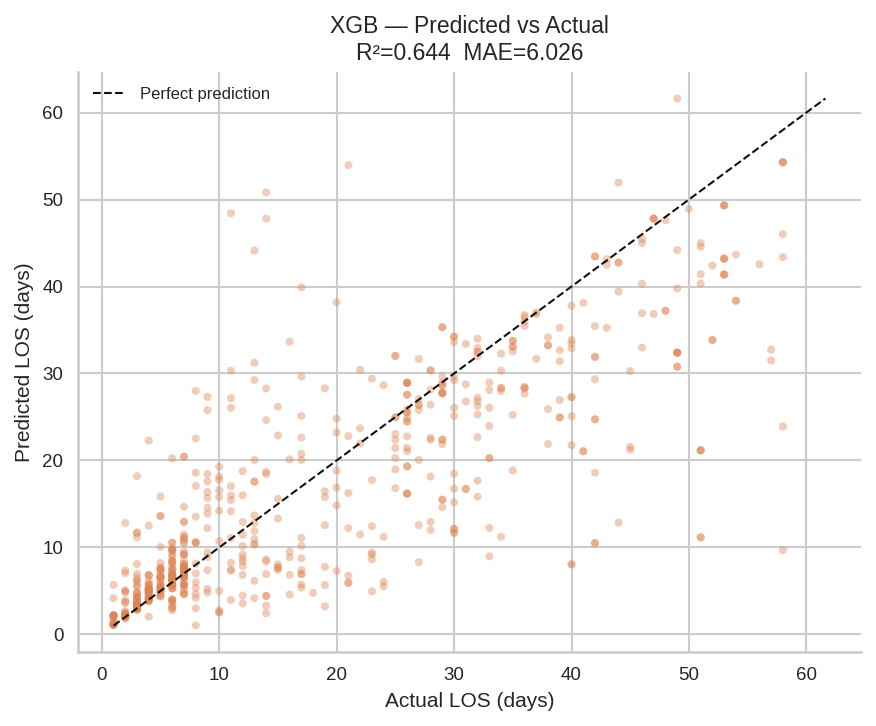

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/predicted_vs_actual_XGB.png


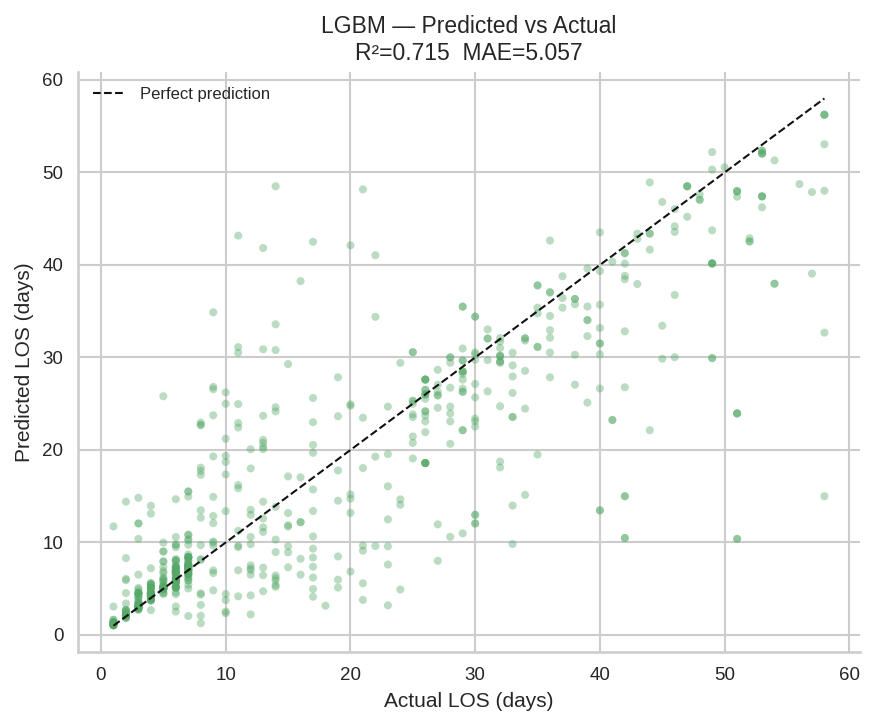

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/predicted_vs_actual_LGBM.png


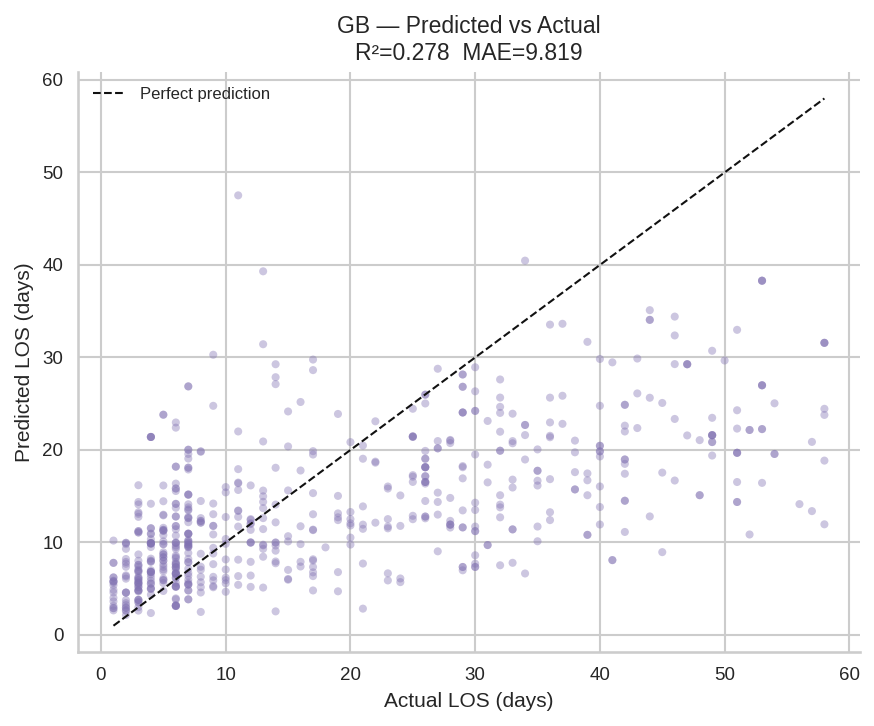

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/predicted_vs_actual_GB.png


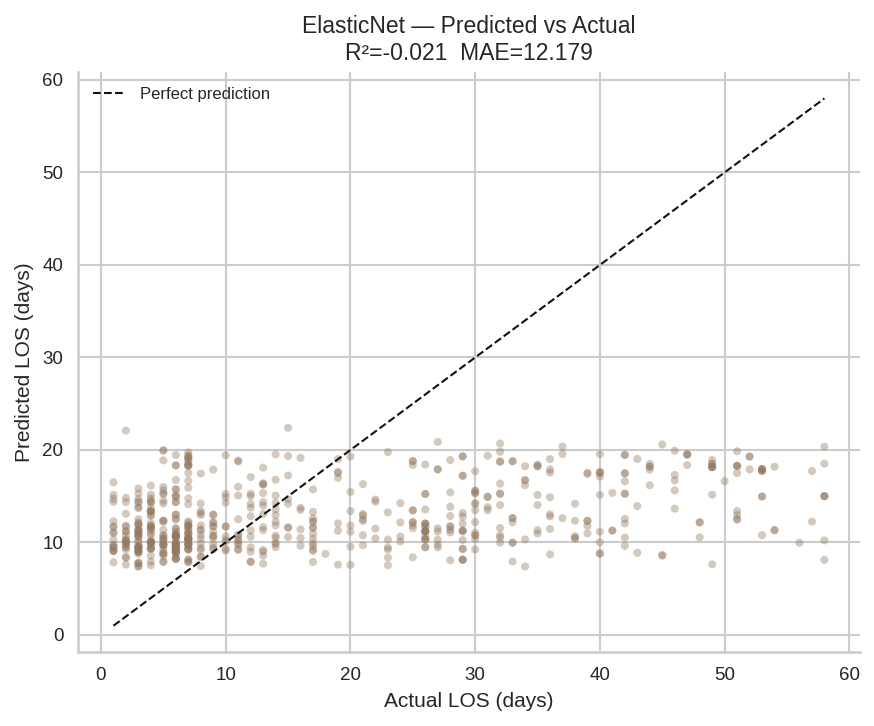

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/predicted_vs_actual_ElasticNet.png


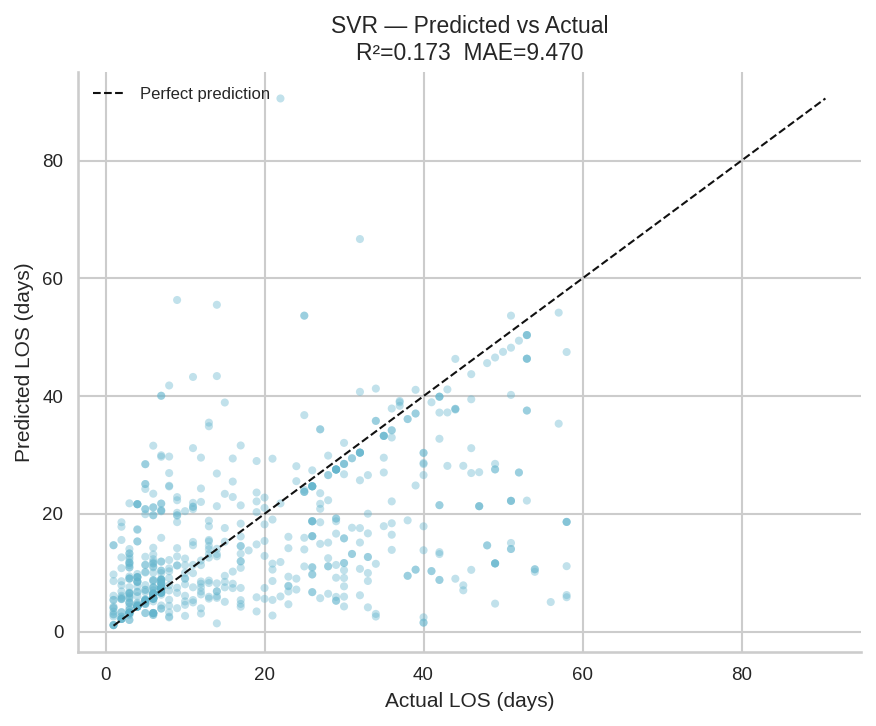

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/predicted_vs_actual_SVR.png


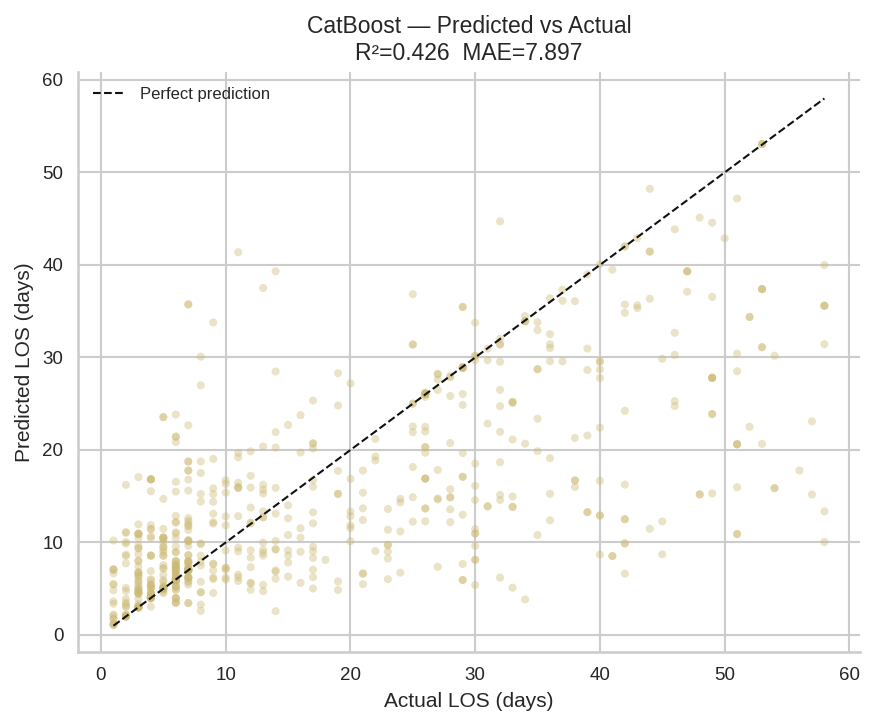

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/predicted_vs_actual_CatBoost.png


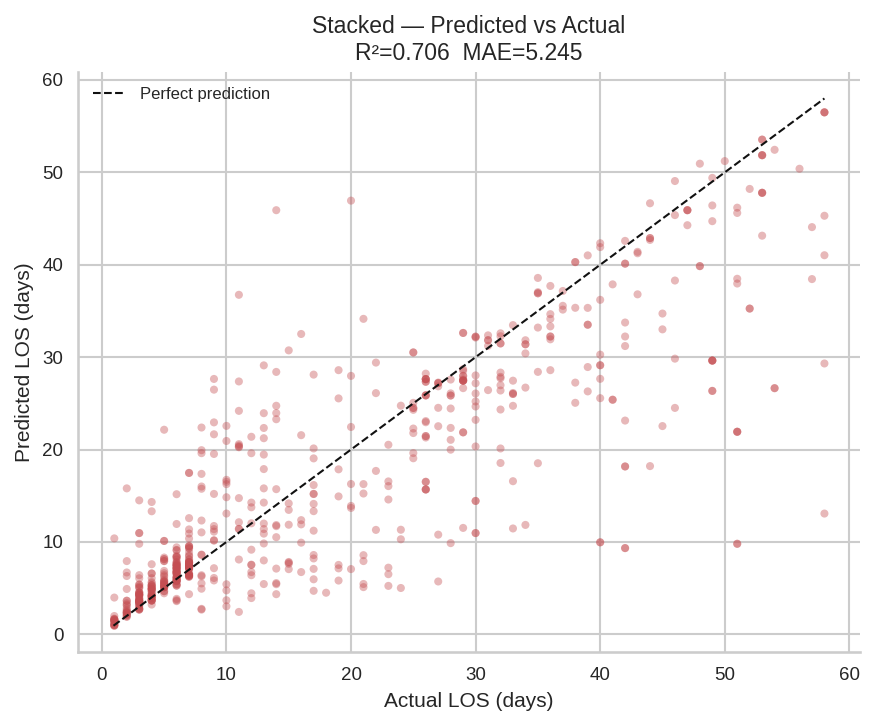

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/predicted_vs_actual_Stacked.png


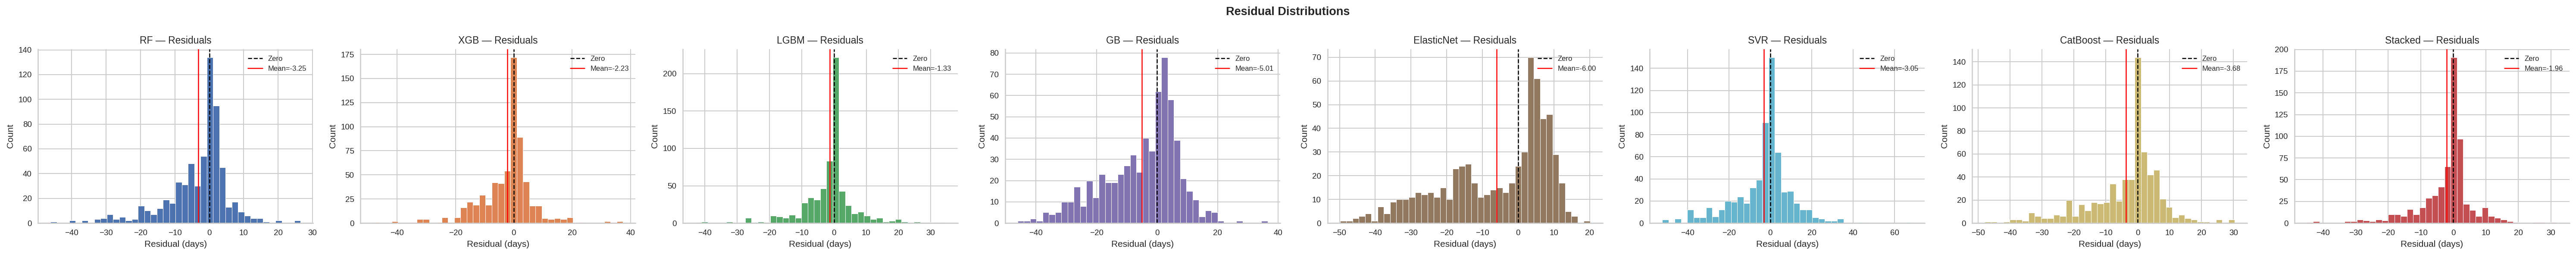

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/residual_distributions.png


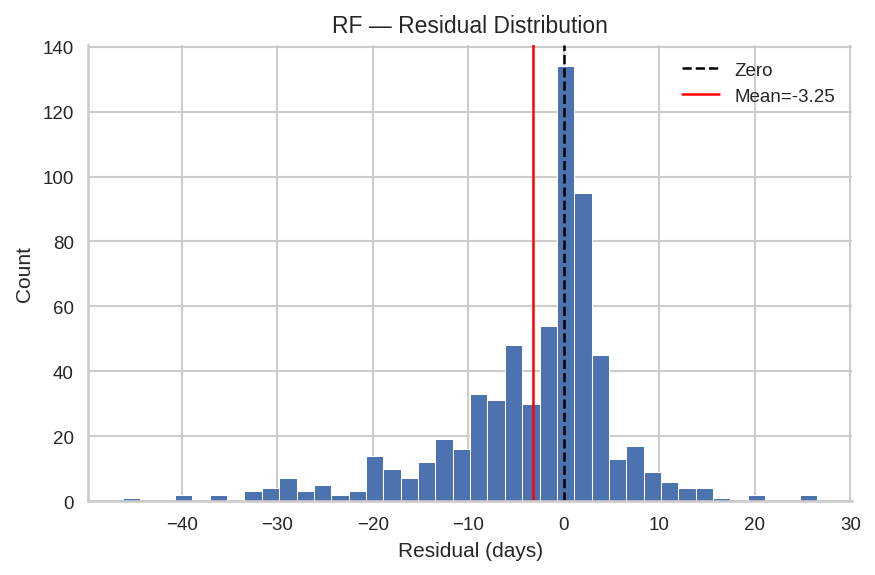

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/residuals_RF.png


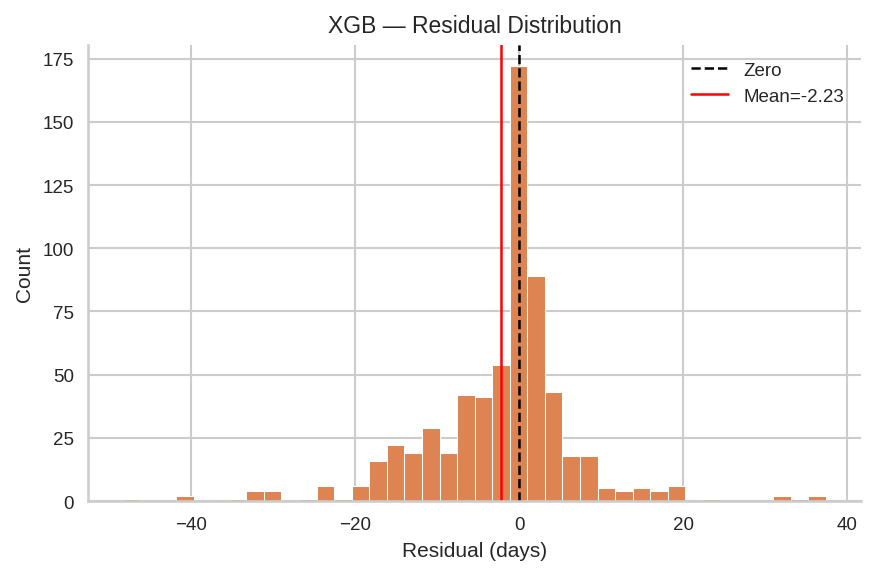

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/residuals_XGB.png


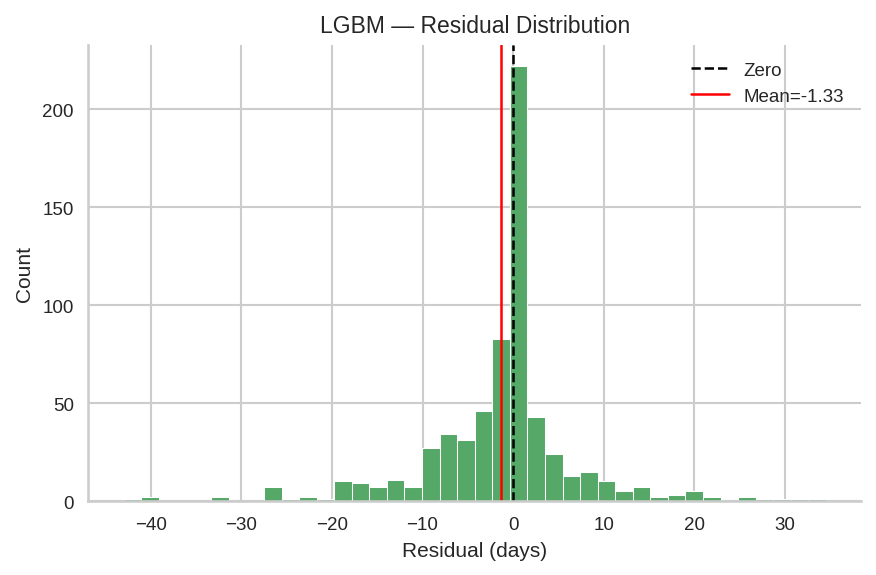

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/residuals_LGBM.png


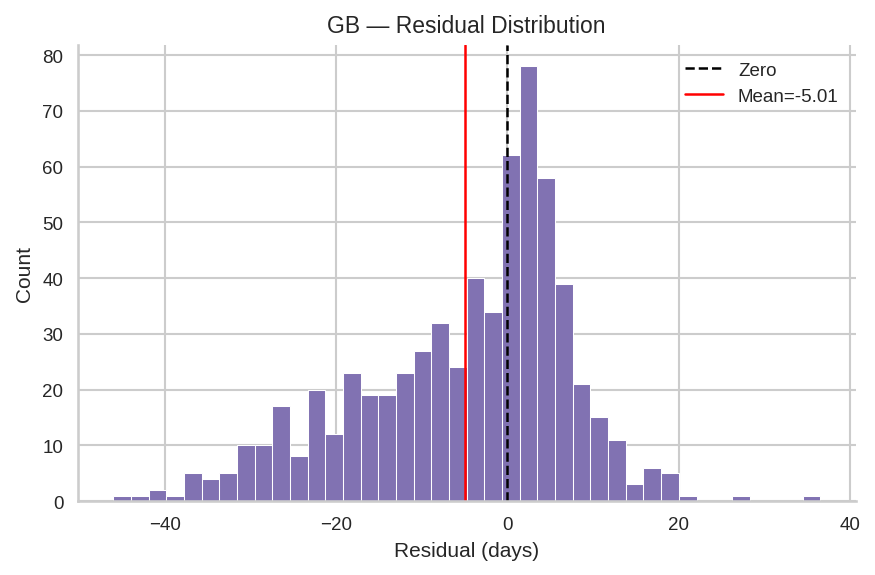

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/residuals_GB.png


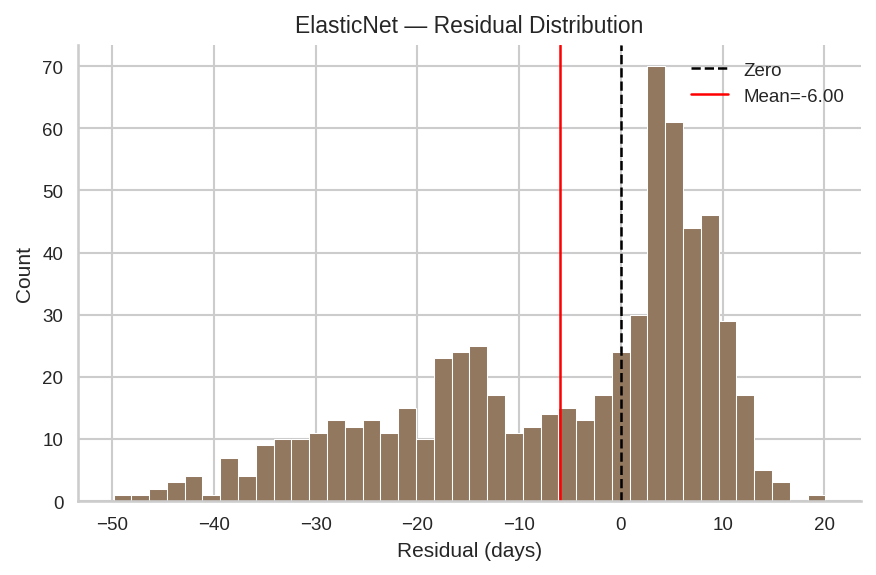

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/residuals_ElasticNet.png


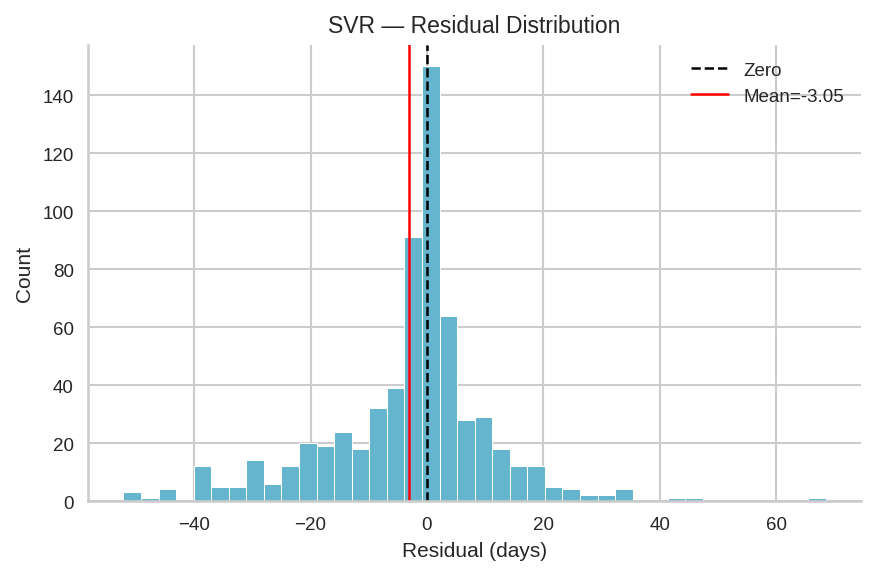

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/residuals_SVR.png


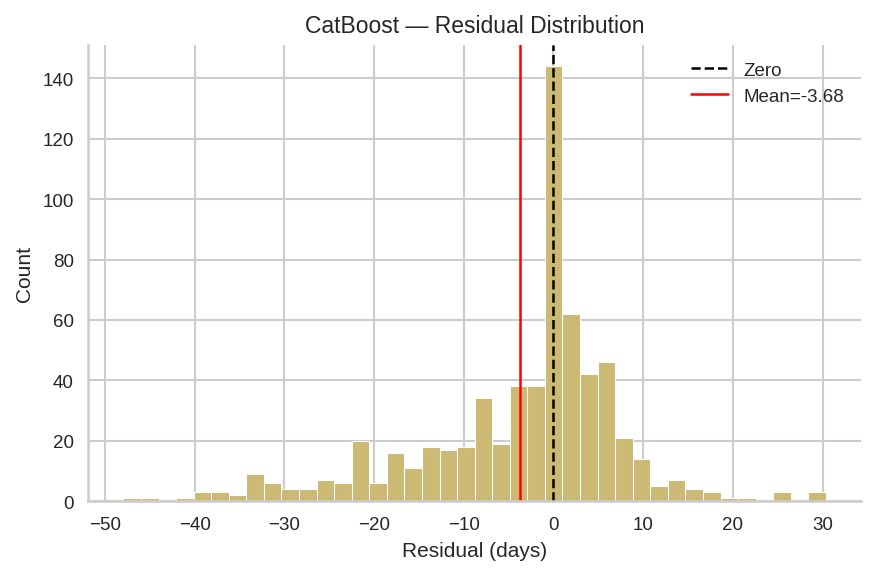

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/residuals_CatBoost.png


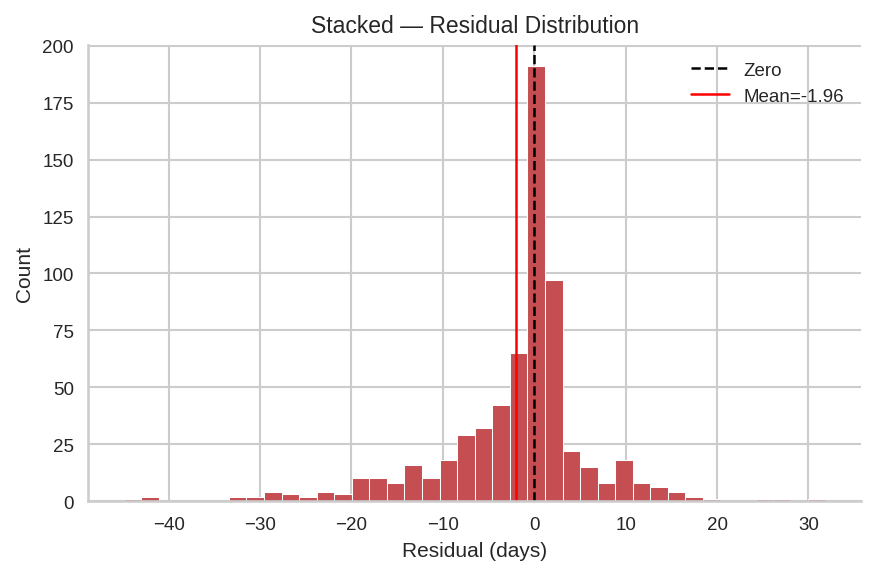

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/residuals_Stacked.png


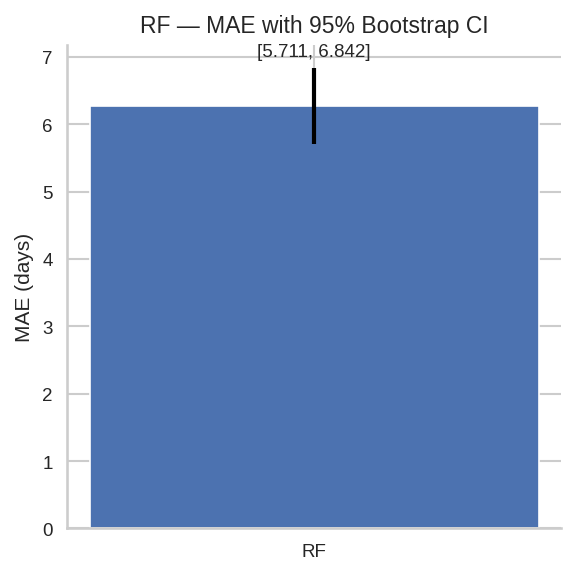

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/mae_ci_RF.png


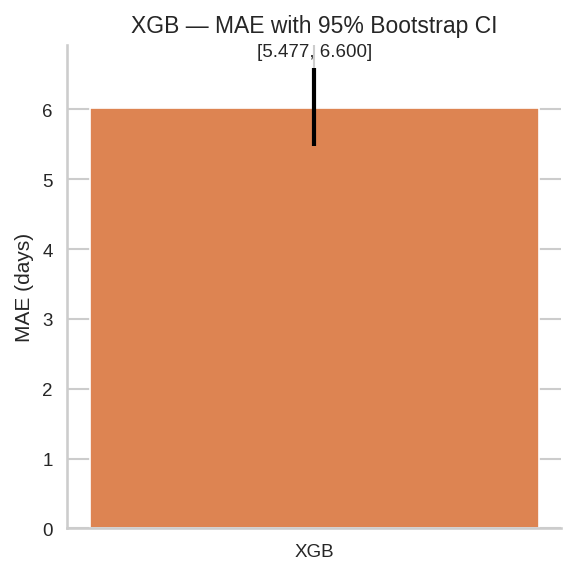

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/mae_ci_XGB.png


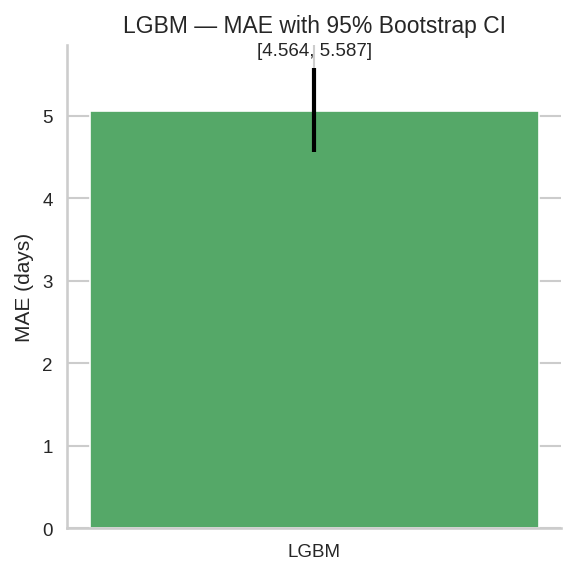

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/mae_ci_LGBM.png


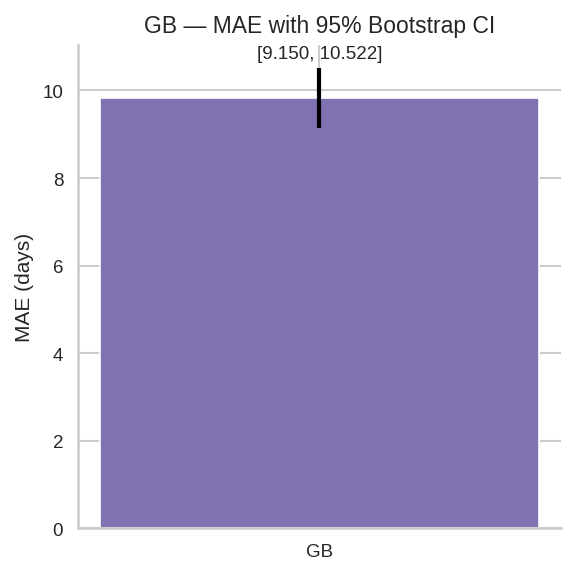

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/mae_ci_GB.png


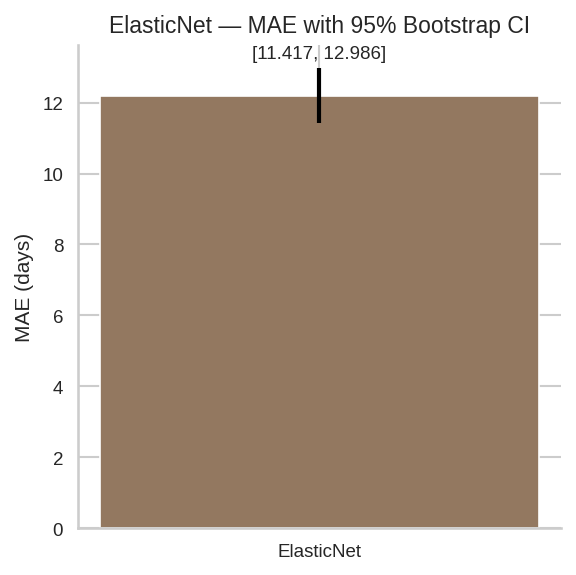

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/mae_ci_ElasticNet.png


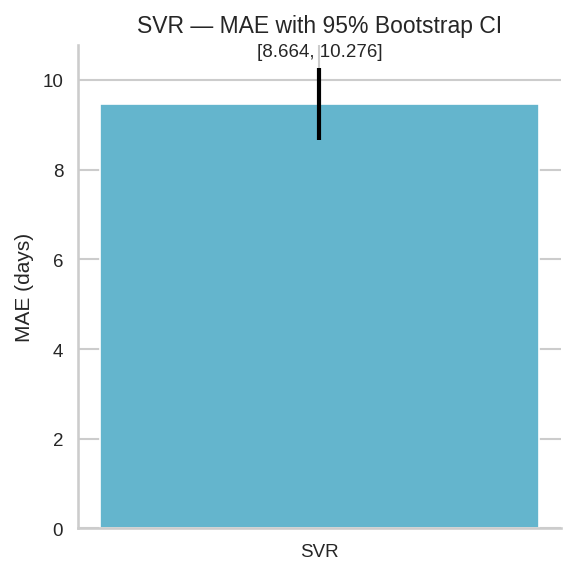

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/mae_ci_SVR.png


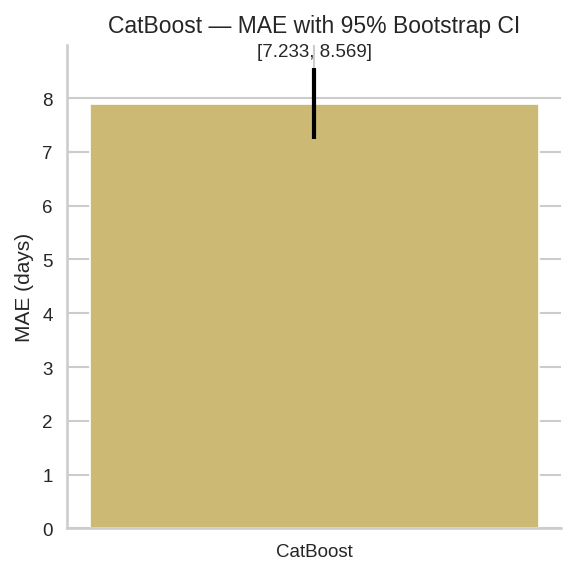

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/mae_ci_CatBoost.png


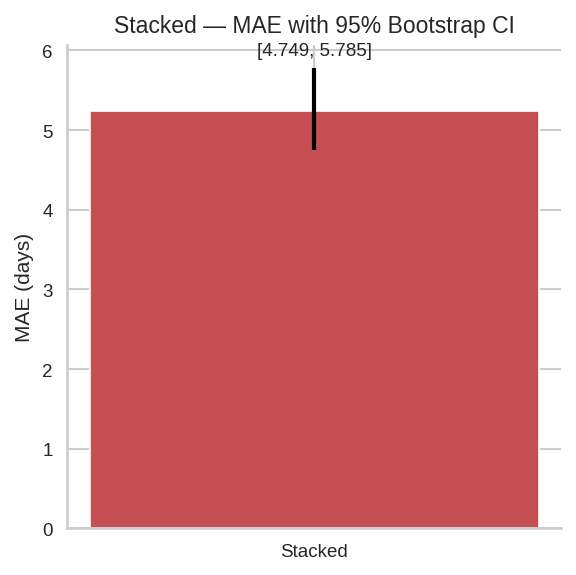

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/mae_ci_Stacked.png


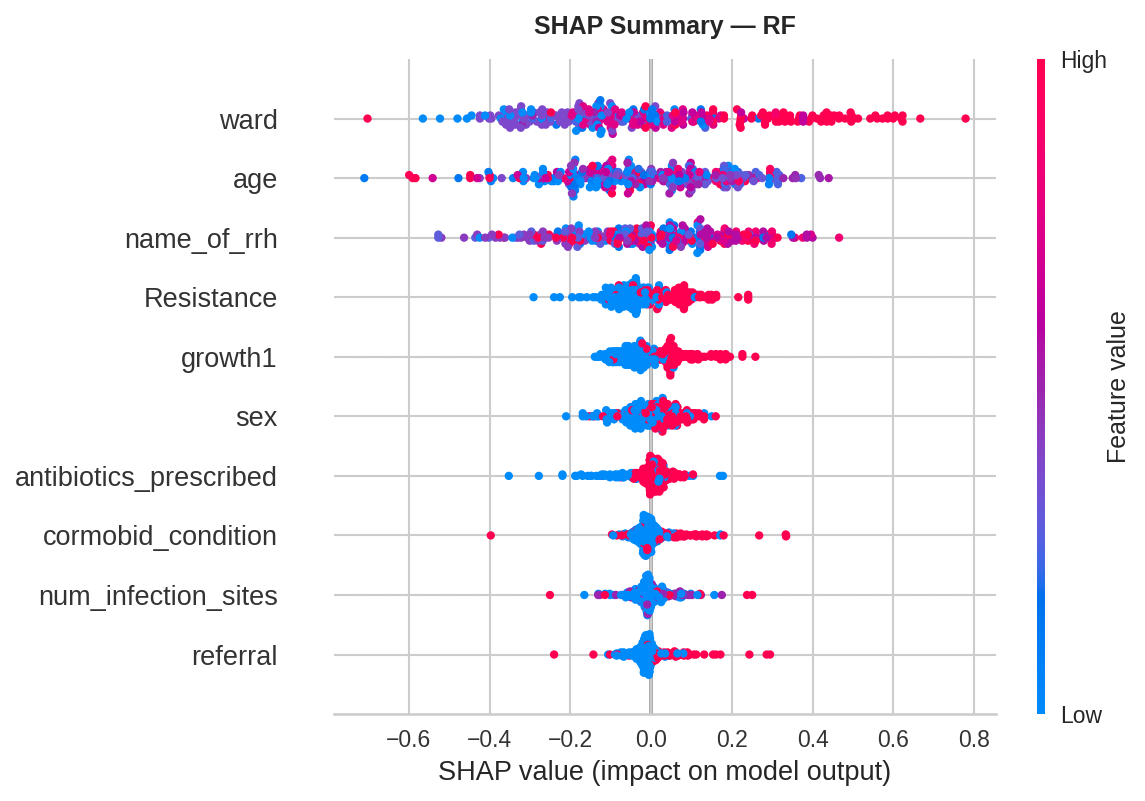

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/shap_summary_RF.png


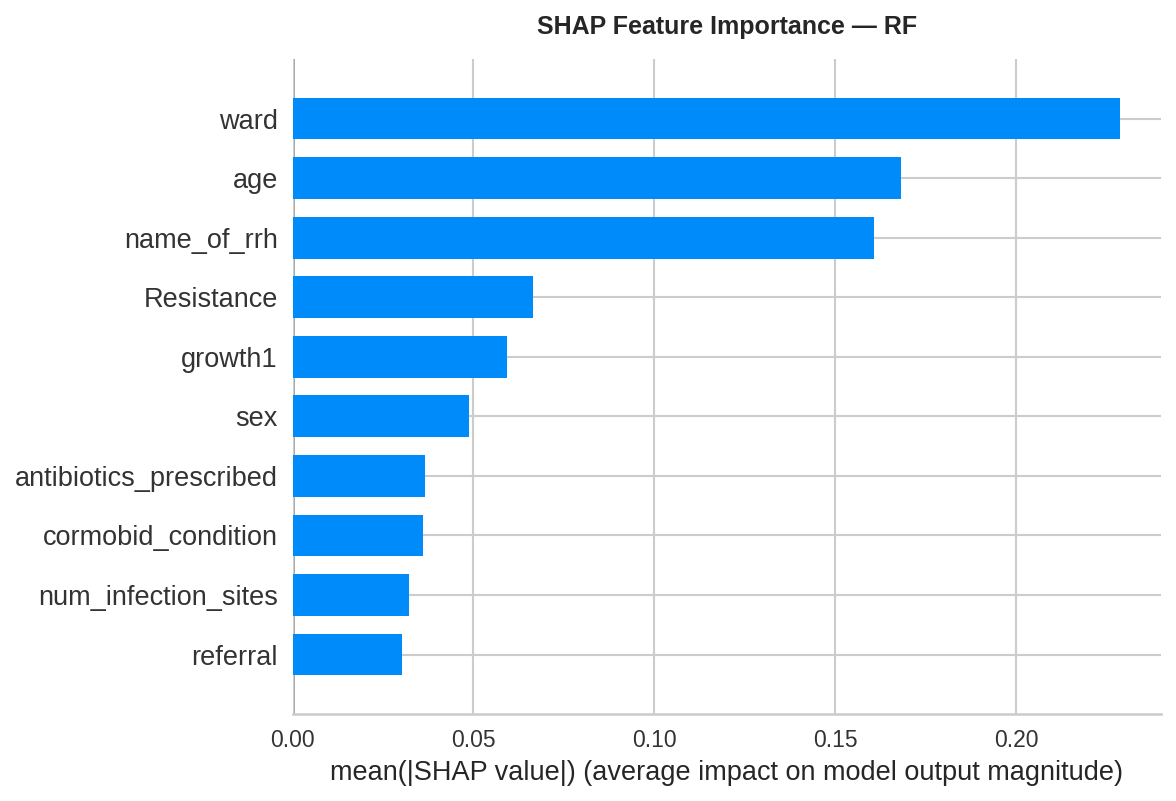

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/shap_importance_RF.png
SHAP failed for XGB: could not convert string to float: '[2.599275E0]'


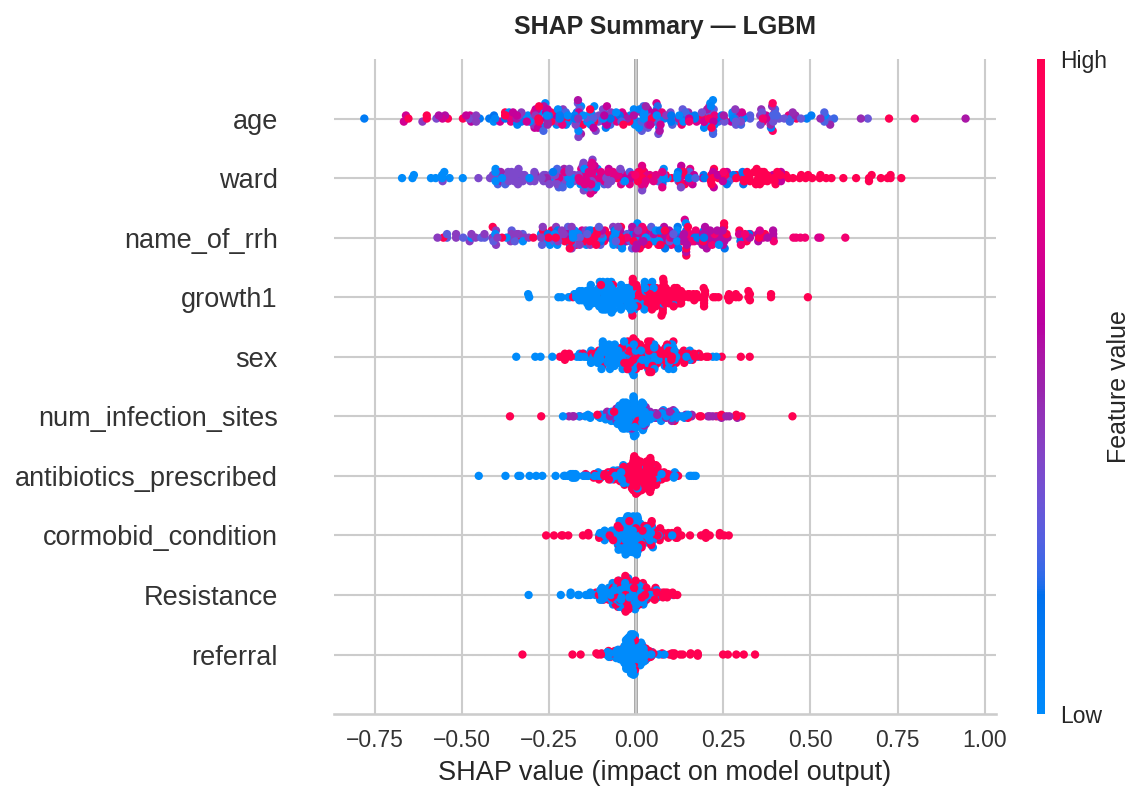

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/shap_summary_LGBM.png


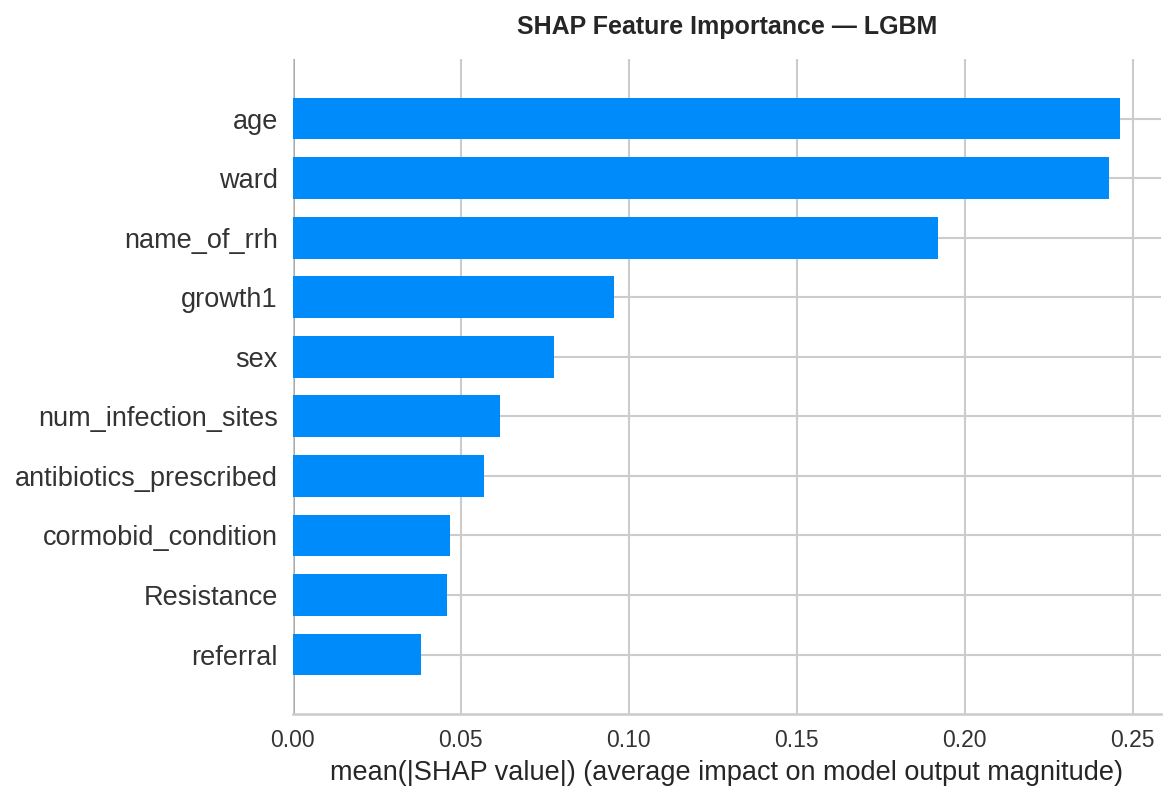

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/shap_importance_LGBM.png


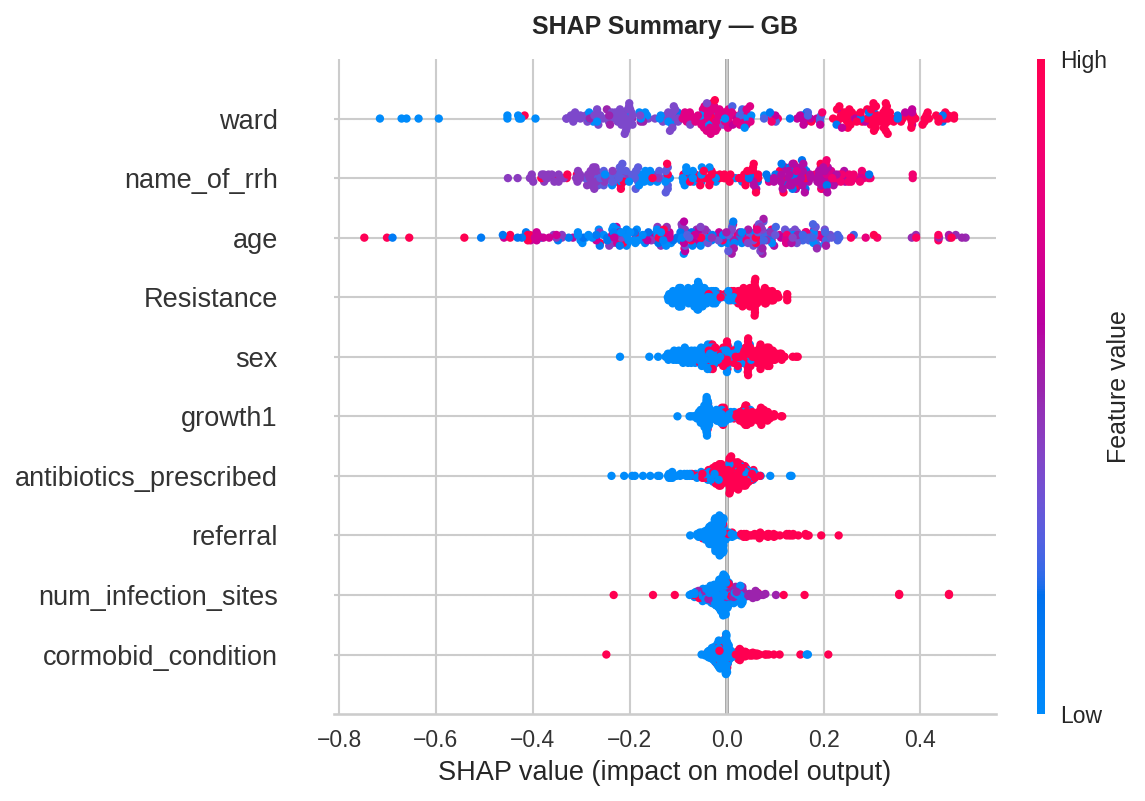

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/shap_summary_GB.png


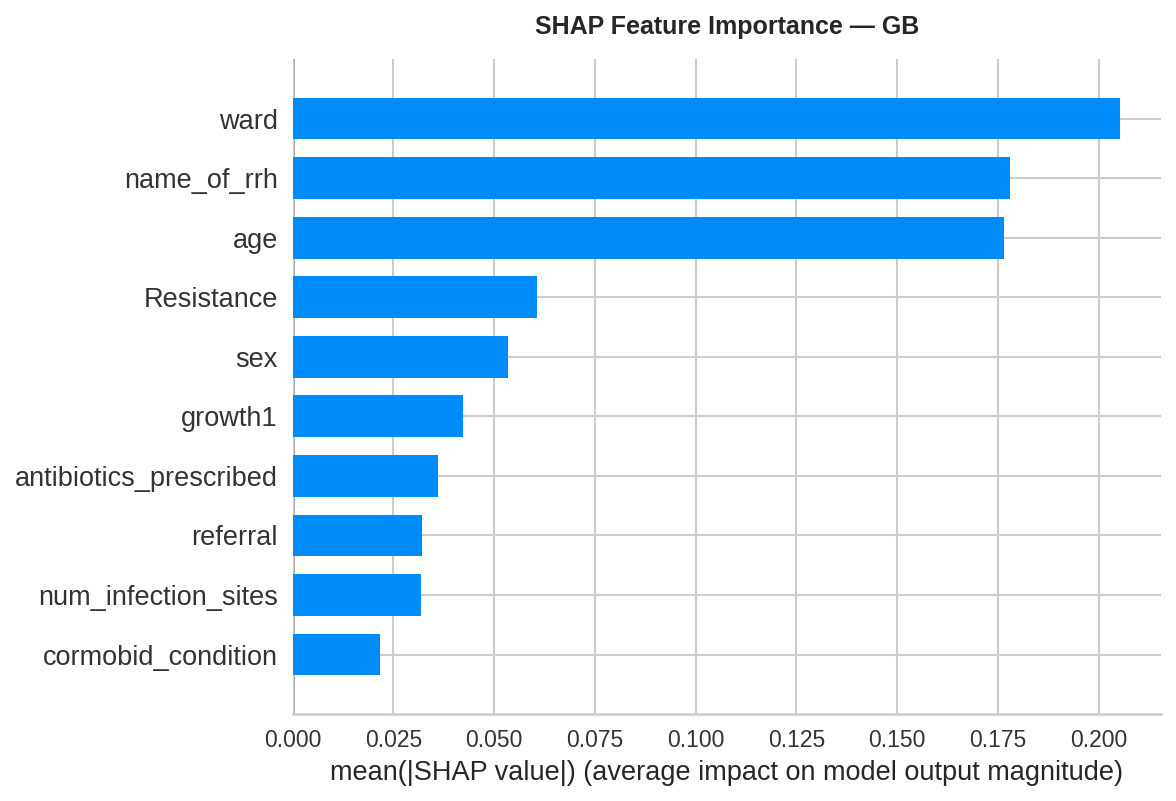

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/shap_importance_GB.png


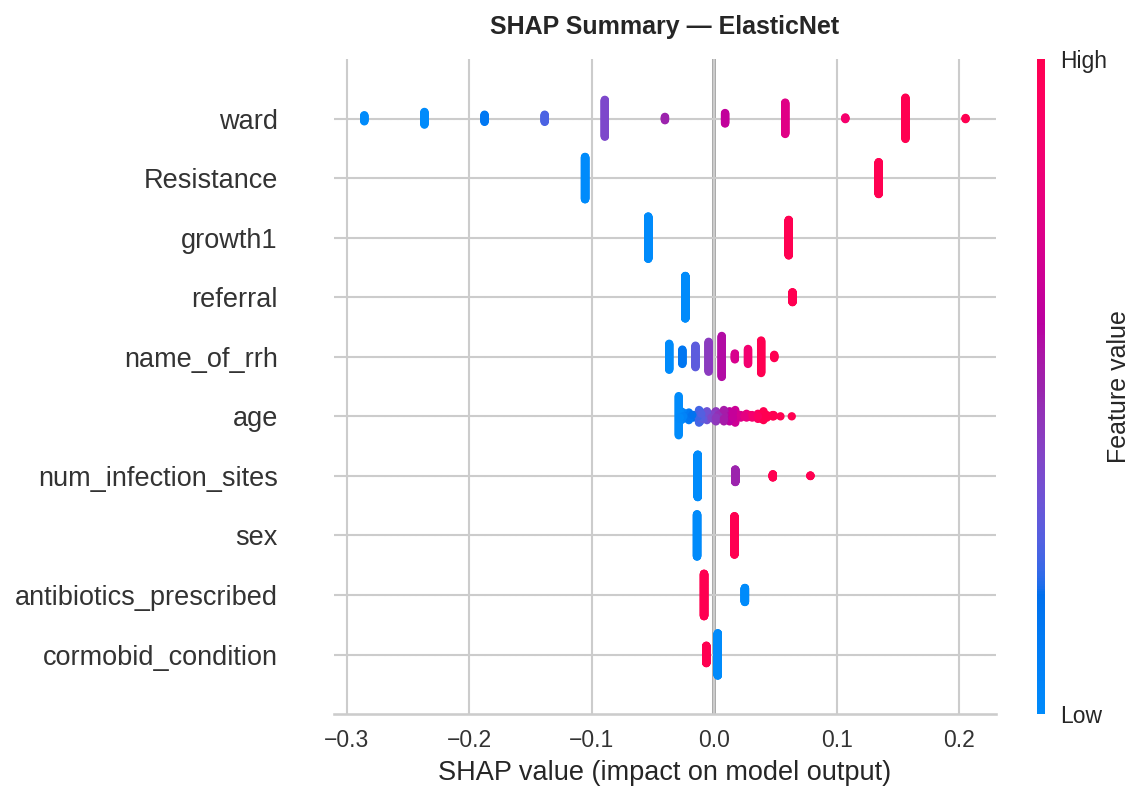

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/shap_summary_ElasticNet.png


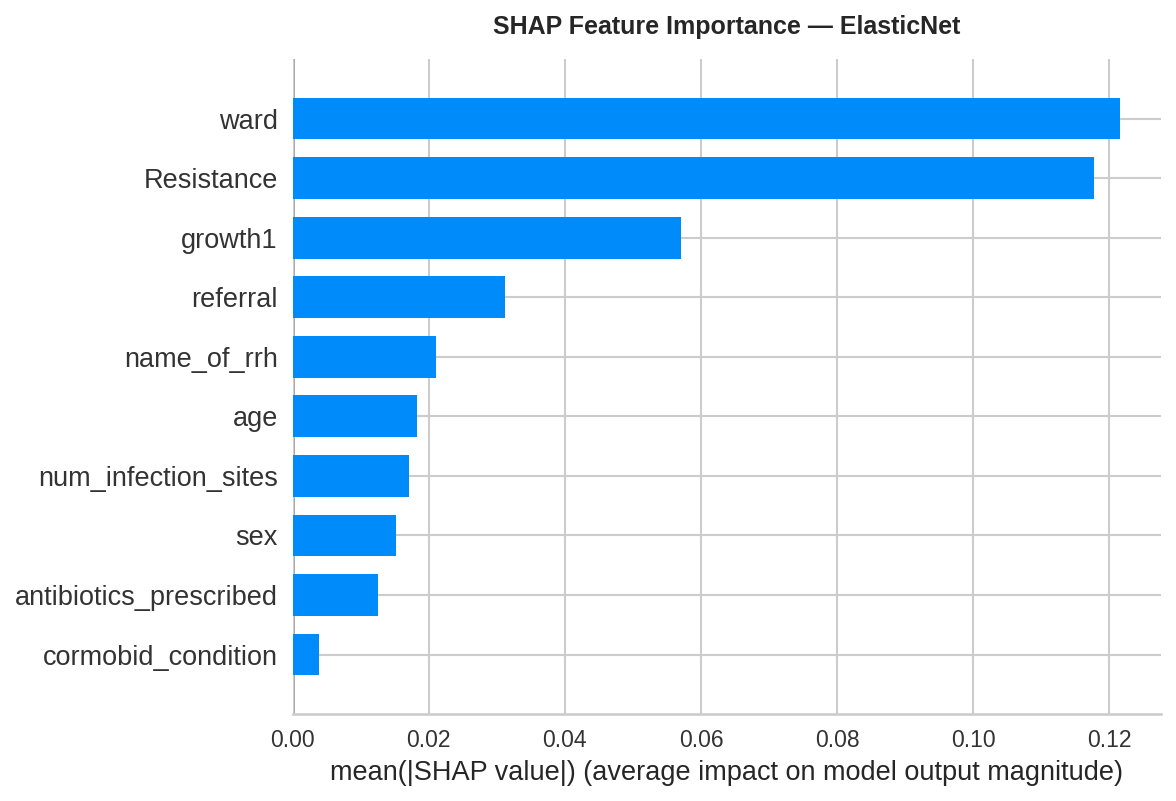

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/shap_importance_ElasticNet.png


  0%|          | 0/300 [00:00<?, ?it/s]

2026-06-24 18:31:01,243 - INFO - num_full_subsets = 1
2026-06-24 18:31:01,244 - INFO - remaining_weight_vector = array([0.32588454, 0.24829299, 0.21725636, 0.20856611])
2026-06-24 18:31:01,244 - INFO - num_paired_subset_sizes = 4
2026-06-24 18:31:01,245 - INFO - weight_left = 0.6072380418010941
2026-06-24 18:31:01,707 - INFO - np.sum(w_aug) = 9.999999999999998
2026-06-24 18:31:01,708 - INFO - np.sum(self.kernelWeights) = 1.0000000000000002
2026-06-24 18:31:01,715 - INFO - phi = array([-0.22363498, -0.08594977, -0.35372457, -0.09697433,  0.01422317,
       -0.05291964, -0.13894137, -0.12568101, -0.10556634, -0.02758704])
2026-06-24 18:31:01,717 - INFO - num_full_subsets = 1
2026-06-24 18:31:01,717 - INFO - remaining_weight_vector = array([0.32588454, 0.24829299, 0.21725636, 0.20856611])
2026-06-24 18:31:01,717 - INFO - num_paired_subset_sizes = 4
2026-06-24 18:31:01,719 - INFO - weight_left = 0.6072380418010941
2026-06-24 18:31:02,123 - INFO - np.sum(w_aug) = 9.999999999999998
2026-06-2

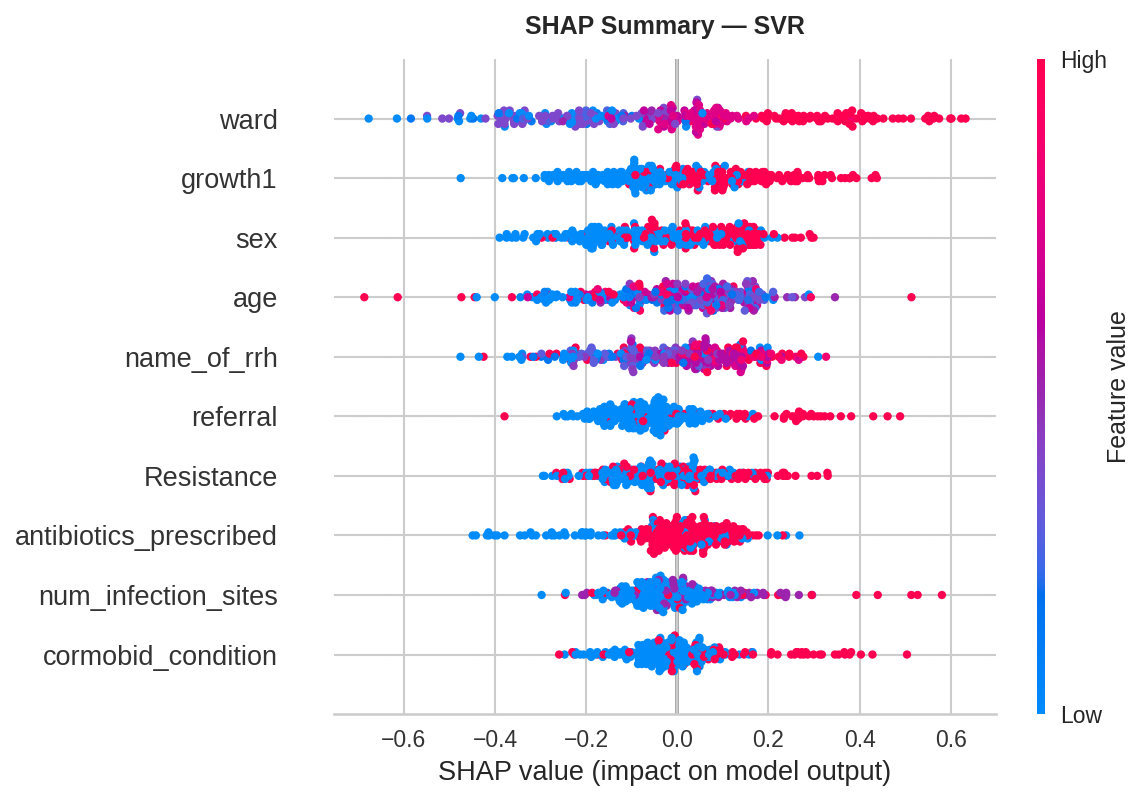

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/shap_summary_SVR.png


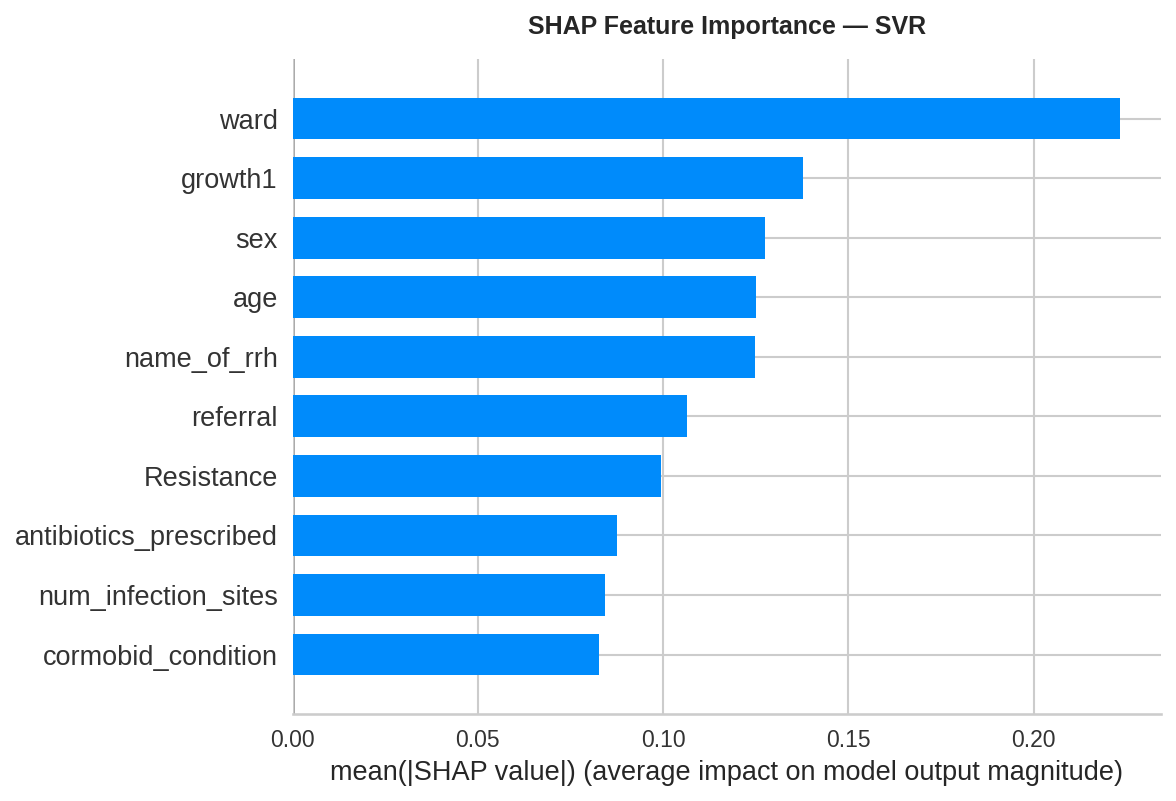

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/shap_importance_SVR.png


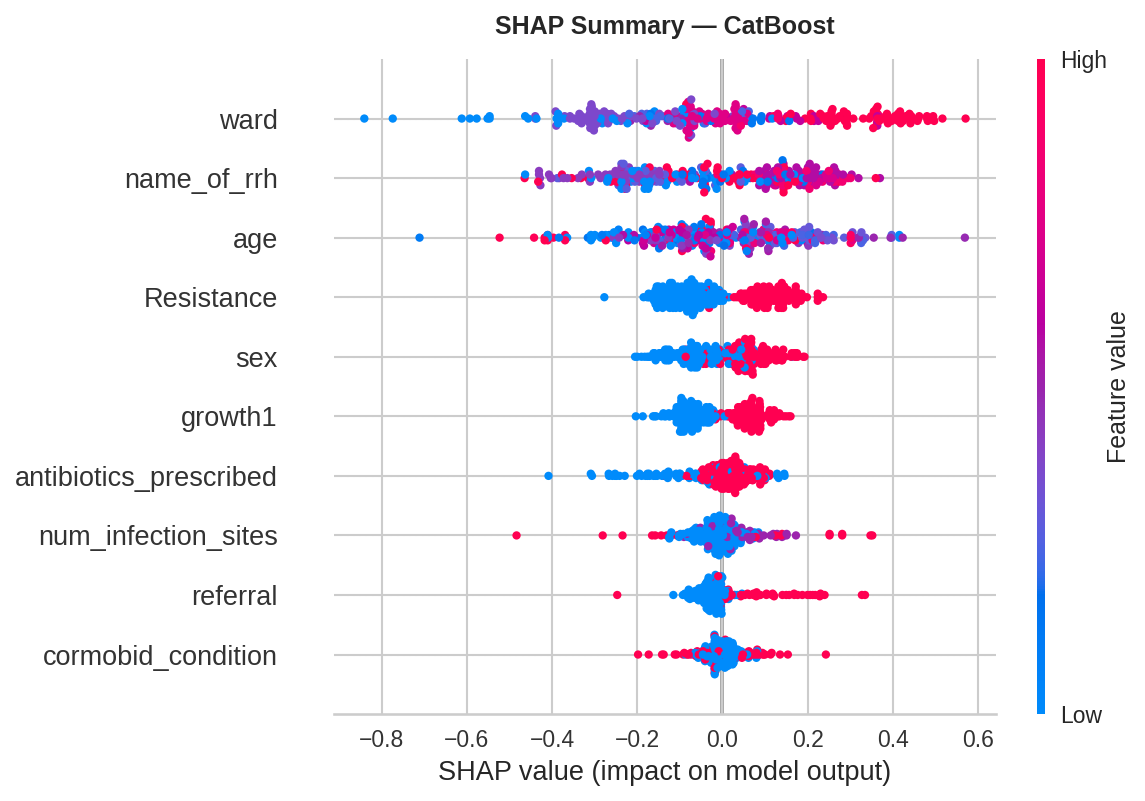

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/shap_summary_CatBoost.png


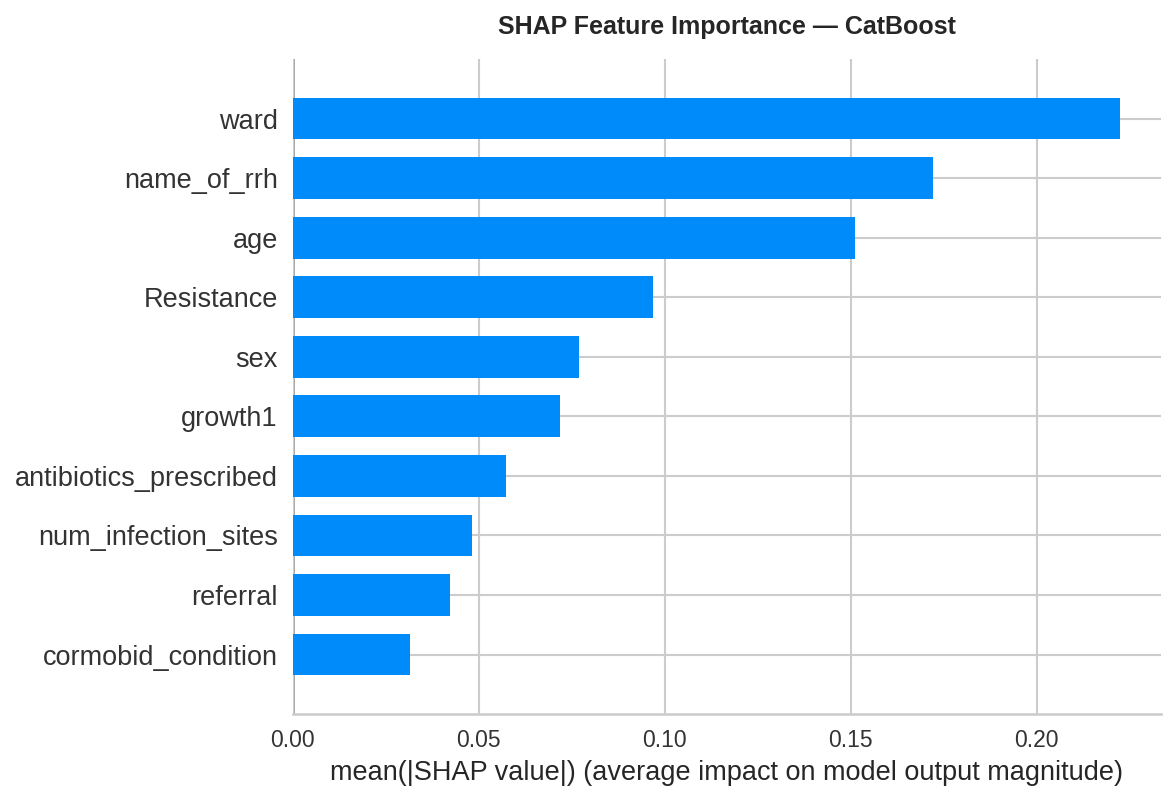

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/shap_importance_CatBoost.png

ALL OUTPUTS SAVED TO: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/
  BEST_MODEL.joblib                                       1.1 KB
  BEST_MODEL_info.joblib                                  0.5 KB
  BEST_MODEL_summary.txt                                  0.7 KB
  best_model.joblib                                    4477.3 KB
  best_model_info.joblib                                  0.4 KB
  best_model_summary.txt                                  0.8 KB
  mae_ci_CatBoost.png                                    23.7 KB
  mae_ci_ElasticNet.png                                  21.8 KB
  mae_ci_GB.png                                          19.9 KB
  mae_ci_LGBM.png                                        19.9 KB
  mae_ci_RF.png                                          18.9 KB
  mae_ci_SVR.png                                         21.0 KB
  mae_ci_Stacked.png                            

<Figure size 800x550 with 0 Axes>

In [93]:
%run -i "/home/kyomukama/ACE/Patient outcomes/HLOS/ML_developement/Scripts/ML_LOS_pipeline.py"

# Test set

In [56]:
# import the test set
test_set = pd.read_csv('/home/kyomukama/ACE/camonet/ml (NEW)/ML clinical outcomes data 14.02.25 version 2  - new.csv')
test_set.head()

,name_of_rrh,age,sex,Number of sites infected,referral,ward,antib_prior_admi,sympt_dura,hiv_status,intubated,cormobid_condition,antibiotics,Number of antibiotics prescribed,organism_isolated,growth1,Resistance,antib_aft_culture,length_hosp_stay
0,Arua,6.0,Male,1,Yes,Pediatric ward,Unknown,< 1 week,Unknown,Unknown,No,Yes,1,0,No,No,No,12
1,Arua,13.0,Male,2,Yes,Medical ward,Unknown,1- < 2 weeks,Negative,Unknown,No,No,0,0,No,No,No,8
2,Arua,11.0,Male,1,No,Pediatric ward,Unknown,< 1 week,Unknown,Unknown,Yes,Yes,2,0,No,No,No,14
3,Arua,18.0,Male,1,Yes,Surgical ward,Unknown,< 1 week,Unknown,Unknown,No,Yes,2,1,Yes,Yes,No,0
4,Arua,17.0,Female,1,Yes,Maternity ward,Unknown,< 1 week,Positive,Unknown,Yes,Yes,3,1,Yes,Yes,Yes,10


In [57]:
test_set['ward'].value_counts()

ward
Surgical ward      224
Medical ward       133
Pediatric ward      91
Maternity ward      55
Gyecology ward      34
ICU Unit            27
NICU                23
Orthopedic ward      3
HDU                  3
Private wing         2
Urology ward         1
Name: count, dtype: int64

In [58]:
test_set = test_set.drop(test_set[test_set['ward'] == 'Urology ward'].index)

In [59]:
# dict

ward_dict = {
    'Pediatric ward': 'Paediatric',
    "Surgical ward" : 'Surgical',
    "Medical ward" : 'Medical',
    "Maternity ward" : 'Maternity/Post-Natal ward',
    "Gyecology ward" : 'Gynaecology',
    "ICU Unit" : 'ICU/HDU',
    "NICU" : "NICU Unit"
}

test_set['ward'].replace(ward_dict, inplace = True)

In [60]:
test_set.isna().sum()

name_of_rrh                         0
age                                 1
sex                                 0
Number of sites infected            0
referral                            0
ward                                0
antib_prior_admi                    0
sympt_dura                          0
hiv_status                          0
intubated                           0
cormobid_condition                  0
antibiotics                         7
Number of antibiotics prescribed    0
organism_isolated                   0
growth1                             0
Resistance                          0
antib_aft_culture                   0
length_hosp_stay                    0
dtype: int64

In [61]:
test_set['age'] = test_set['age'].fillna(test_set['age'].mean())

In [62]:
def antibiotics_pres(row):

    if row['Number of sites infected'] > 0:
        return 'Yes'
    else:
        return 'No'

test_set['antibiotics_prescribed']  = test_set.apply(antibiotics_pres, axis = 1)

In [63]:
test_set.columns

Index(['name_of_rrh', 'age', 'sex', 'Number of sites infected', 'referral',
       'ward', 'antib_prior_admi', 'sympt_dura', 'hiv_status', 'intubated',
       'cormobid_condition', 'antibiotics', 'Number of antibiotics prescribed',
       'organism_isolated', 'growth1', 'Resistance', 'antib_aft_culture',
       'length_hosp_stay', 'antibiotics_prescribed'],
      dtype='object')

In [64]:
columns = [
    'name_of_rrh', 'age', 'sex', 
    'Number of sites infected', 
    'referral','ward', 'cormobid_condition',  
    'growth1', 'Resistance',
    'length_hosp_stay', 'antibiotics_prescribed']

test_set = test_set[columns]

In [65]:
test_set.rename(columns={'Number of sites infected': 'num_infection_sites'}, inplace = True)
test_set.head()

,name_of_rrh,age,sex,num_infection_sites,referral,ward,cormobid_condition,growth1,Resistance,length_hosp_stay,antibiotics_prescribed
0,Arua,6.0,Male,1,Yes,Paediatric,No,No,No,12,Yes
1,Arua,13.0,Male,2,Yes,Medical,No,No,No,8,Yes
2,Arua,11.0,Male,1,No,Paediatric,Yes,No,No,14,Yes
3,Arua,18.0,Male,1,Yes,Surgical,No,Yes,Yes,0,Yes
4,Arua,17.0,Female,1,Yes,Maternity/Post-Natal ward,Yes,Yes,Yes,10,Yes


In [66]:
test_set.isna().sum()

name_of_rrh               0
age                       0
sex                       0
num_infection_sites       0
referral                  0
ward                      0
cormobid_condition        0
growth1                   0
Resistance                0
length_hosp_stay          0
antibiotics_prescribed    0
dtype: int64

In [67]:
X_test = test_set.drop(columns = ['length_hosp_stay'])
y_test = test_set['length_hosp_stay']

In [68]:
X_test.columns

Index(['name_of_rrh', 'age', 'sex', 'num_infection_sites', 'referral', 'ward',
       'cormobid_condition', 'growth1', 'Resistance',
       'antibiotics_prescribed'],
      dtype='object')

In [69]:
# Transforming test data using the fitted pipeline
X_test_transformed = pd.DataFrame(
    pipeline.transform(X_test),
    columns=feature_names
)

X_test_transformed.head()

,age,num_infection_sites,sex,referral,cormobid_condition,antibiotics_prescribed,growth1,Resistance,name_of_rrh,ward
0,6.0,1.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,7.0
1,13.0,2.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,4.0
2,11.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,7.0
3,18.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0,0.0,9.0
4,17.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,0.0,3.0


In [70]:
test_wards  = set(X_test_transformed["ward"].unique())
test_wards

{-1.0, 1.0, 2.0, 3.0, 4.0, 5.0, 7.0, 8.0, 9.0}

In [71]:
# rename columns
columns = ['sex', 'referral', 'cormobid_condition', 'antibiotics_prescribed', 'growth1', 'Resistance']

old_cols = ['sex_Male', 'referral_Yes','cormobid_condition_Yes', 'antibiotics_prescribed_Yes', 'growth1_Yes', 'Resistance_Yes']

# Creating the mapping dictionary
rename_dict = dict(zip(old_cols, columns))

# Applying rename to the DataFrame
X_test_transformed.rename(columns=rename_dict, inplace=True)

X_test_transformed.head()

,age,num_infection_sites,sex,referral,cormobid_condition,antibiotics_prescribed,growth1,Resistance,name_of_rrh,ward
0,6.0,1.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,7.0
1,13.0,2.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,4.0
2,11.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,7.0
3,18.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0,0.0,9.0
4,17.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,0.0,3.0


In [72]:
# Converting object columns 'category'
cols = ['sex', 'referral', 'cormobid_condition', 'antibiotics_prescribed', 'growth1', 'Resistance']
X_test_transformed[cols] = X_test_transformed[cols].astype('category')

In [73]:
X_test_transformed.dtypes

age                        float64
num_infection_sites        float64
sex                       category
referral                  category
cormobid_condition        category
antibiotics_prescribed    category
growth1                   category
Resistance                category
name_of_rrh                float64
ward                       float64
dtype: object

In [74]:
# Define your target column order
ordered_cols = [
    'age', 'num_infection_sites', 'sex', 'referral', 'cormobid_condition',
    'antibiotics_prescribed', 'growth1', 'Resistance', 'name_of_rrh', 'ward'
]

# Apply the order to your test_set
X_test_transformed = X_test_transformed[ordered_cols]

In [75]:
X_test_transformed.columns

Index(['age', 'num_infection_sites', 'sex', 'referral', 'cormobid_condition',
       'antibiotics_prescribed', 'growth1', 'Resistance', 'name_of_rrh',
       'ward'],
      dtype='object')

In [76]:
test_data = pd.concat([X_test_transformed, y_test], axis=1)
test_data.to_csv("/home/kyomukama/ACE/Patient outcomes/HLOS/ML_developement/Data/test_data.csv", index=False)

In [77]:
# 1. Compare target distributions
print("=== TARGET VARIABLE ===")
print("Train:", y.describe())
print("Test: ", y_test.describe())

# 2. Check for nulls / new categories in test
print("\n=== NULLS ===")
print("Train nulls:", X_transformed.isnull().sum().sum())
print("Test nulls: ", X_test_transformed.isnull().sum().sum())

=== TARGET VARIABLE ===
Train: count    3189.000000
mean       18.715898
std        15.883028
min         1.000000
25%         5.000000
50%        13.000000
75%        30.000000
max        58.000000
Name: length_hosp_stay, dtype: float64
Test:  count    595.000000
mean      22.531092
std       39.697301
min        0.000000
25%        6.000000
50%       14.000000
75%       27.000000
max      744.000000
Name: length_hosp_stay, dtype: float64

=== NULLS ===
Train nulls: 0
Test nulls:  0


In [78]:
# 1. Target comparison (corrected)
print("=== TARGET VARIABLE ===")
print("Train:\n", y.describe())
print("\nTest:\n", y_test.describe())

# 2. Cardinality check
print("\n=== CARDINALITY ===")
for col in X_transformed.select_dtypes('object').columns:
    print(f"{col}: train={X_transformed[col].nunique()} | test={X_test_transformed[col].nunique()}")

# 3. Unseen categories in test
print("\n=== UNSEEN CATEGORIES IN TEST ===")
for col in X_transformed.select_dtypes('object').columns:
    unseen = set(X_test_transformed[col].unique()) - set(X_transformed[col].unique())
    if unseen:
        print(f"⚠️  '{col}': {unseen}")
    else:
        print(f"✅  '{col}': no unseen categories")

# 4. How are you encoding? Check what X_transformed looks like
print("\n=== ENCODED FEATURE SAMPLE ===")
print(X_transformed.head(3))
print("\nDtypes:\n", X_transformed.dtypes.value_counts())
print("\nShape:", X_transformed.shape, "→ Test:", X_test_transformed.shape)


=== TARGET VARIABLE ===
Train:
 count    3189.000000
mean       18.715898
std        15.883028
min         1.000000
25%         5.000000
50%        13.000000
75%        30.000000
max        58.000000
Name: length_hosp_stay, dtype: float64

Test:
 count    595.000000
mean      22.531092
std       39.697301
min        0.000000
25%        6.000000
50%       14.000000
75%       27.000000
max      744.000000
Name: length_hosp_stay, dtype: float64

=== CARDINALITY ===

=== UNSEEN CATEGORIES IN TEST ===

=== ENCODED FEATURE SAMPLE ===
    age  num_infection_sites  sex referral cormobid_condition  \
0  36.0                  2.0  0.0      0.0                0.0   
1  57.0                  3.0  0.0      0.0                0.0   
2   8.0                  2.0  0.0      0.0                0.0   

  antibiotics_prescribed growth1 Resistance name_of_rrh ward  
0                    1.0     0.0        0.0         0.0  1.0  
1                    1.0     1.0        1.0         0.0  6.0  
2               

In [79]:
X_test_transformed.columns

Index(['age', 'num_infection_sites', 'sex', 'referral', 'cormobid_condition',
       'antibiotics_prescribed', 'growth1', 'Resistance', 'name_of_rrh',
       'ward'],
      dtype='object')

In [80]:
ml_data.columns

Index(['age', 'num_infection_sites', 'sex', 'referral', 'cormobid_condition',
       'antibiotics_prescribed', 'growth1', 'Resistance', 'name_of_rrh',
       'ward', 'length_hosp_stay'],
      dtype='object')

### load best mdoel

In [81]:
import joblib

In [82]:
model_path = "/home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/model_RF.joblib"

model = joblib.load(model_path)

In [83]:
data_clean = pd.concat([X_test_transformed, y_test], axis=1)
data_clean.head()

,age,num_infection_sites,sex,referral,cormobid_condition,antibiotics_prescribed,growth1,Resistance,name_of_rrh,ward,length_hosp_stay
0,6.0,1.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,7.0,12.0
1,13.0,2.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,4.0,8.0
2,11.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,7.0,14.0
3,18.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0,0.0,9.0,0.0
4,17.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,0.0,3.0,10.0


In [84]:
data_clean.drop(data_clean[data_clean['length_hosp_stay'] > 60].index, inplace=True)
data_clean.reset_index(drop=True, inplace=True)

In [85]:
ml_data.columns

Index(['age', 'num_infection_sites', 'sex', 'referral', 'cormobid_condition',
       'antibiotics_prescribed', 'growth1', 'Resistance', 'name_of_rrh',
       'ward', 'length_hosp_stay'],
      dtype='object')

In [86]:
data_clean.isna().sum() 

age                       1
num_infection_sites       1
sex                       1
referral                  1
cormobid_condition        1
antibiotics_prescribed    1
growth1                   1
Resistance                1
name_of_rrh               1
ward                      1
length_hosp_stay          1
dtype: int64

In [87]:
data_clean.dropna(inplace=True)

Results will be saved to: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ml_test_results

Loading model …
  Model type : Pipeline
Features scaler was trained on: 10

Loading test data from '      age  num_infection_sites  sex referral cormobid_condition  \
0     6.0                  1.0  1.0      1.0                0.0   
1    13.0                  2.0  1.0      1.0                0.0   
2    11.0                  1.0  1.0      0.0                1.0   
3    18.0                  1.0  1.0      1.0                0.0   
4    17.0                  1.0  0.0      1.0                1.0   
..    ...                  ...  ...      ...                ...   
554   2.0                  1.0  0.0      0.0                0.0   
555  27.0                  1.0  0.0      0.0                0.0   
556  20.0                  1.0  0.0      0.0                0.0   
557  24.0                  1.0  0.0      1.0                0.0   
558   2.0                  1.0  0.0      0.0                0.0   

    ant

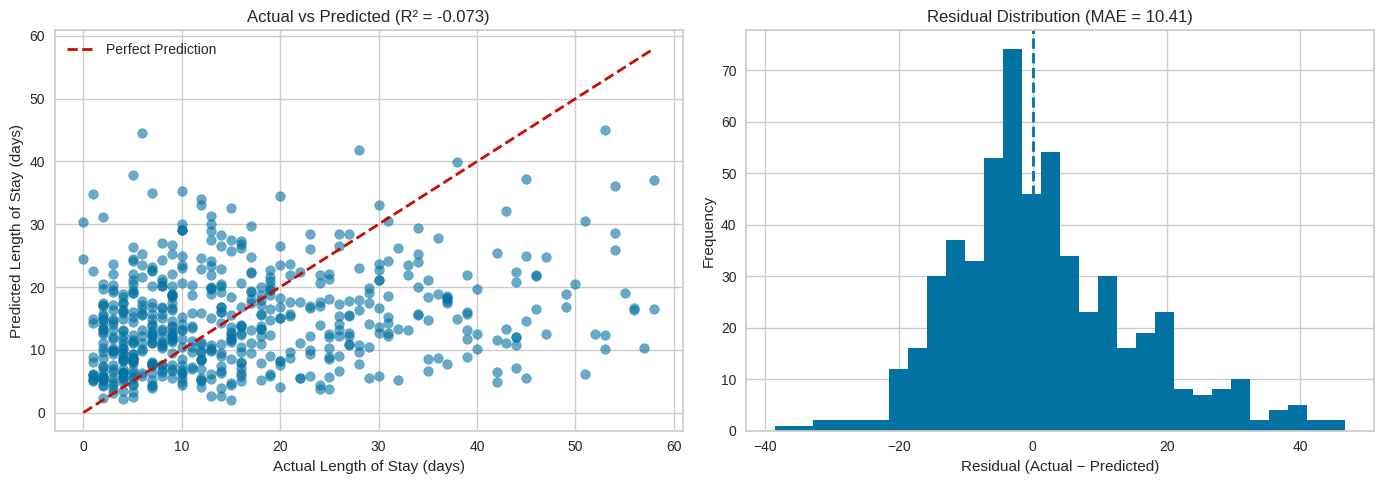


Plots saved → /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ml_test_results/model_evaluation_plots.png


<Figure size 800x550 with 0 Axes>


  Plots saved → /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ml_test_results/model_evaluation_plots.png
Predictions saved → /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ml_test_results/predictions.csv

Sample predictions:
 Actual  Predicted  Residual
   12.0       8.37      3.63
    8.0       6.52      1.48
   14.0       9.07      4.93
    0.0      30.31    -30.31
   10.0      11.67     -1.67
    6.0      16.52    -10.52
   11.0      11.36     -0.36
    5.0      15.20    -10.20
    5.0      19.03    -14.03
    4.0       2.22      1.78

✓ All results saved to: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ml_test_results


<Figure size 800x550 with 0 Axes>

In [88]:
%run -i /home/kyomukama/ACE/camonet/ML_Rerun/Scripts/test_model.py

Results will be saved to: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ml_test_results

Loading model …
  Model type : Pipeline
Features scaler was trained on: 10

Loading test data from '      age  num_infection_sites  sex referral cormobid_condition  \
0     6.0                  1.0  1.0      1.0                0.0   
1    13.0                  2.0  1.0      1.0                0.0   
2    11.0                  1.0  1.0      0.0                1.0   
3    18.0                  1.0  1.0      1.0                0.0   
4    17.0                  1.0  0.0      1.0                1.0   
..    ...                  ...  ...      ...                ...   
554   2.0                  1.0  0.0      0.0                0.0   
555  27.0                  1.0  0.0      0.0                0.0   
556  20.0                  1.0  0.0      0.0                0.0   
557  24.0                  1.0  0.0      1.0                0.0   
558   2.0                  1.0  0.0      0.0                0.0   

    ant

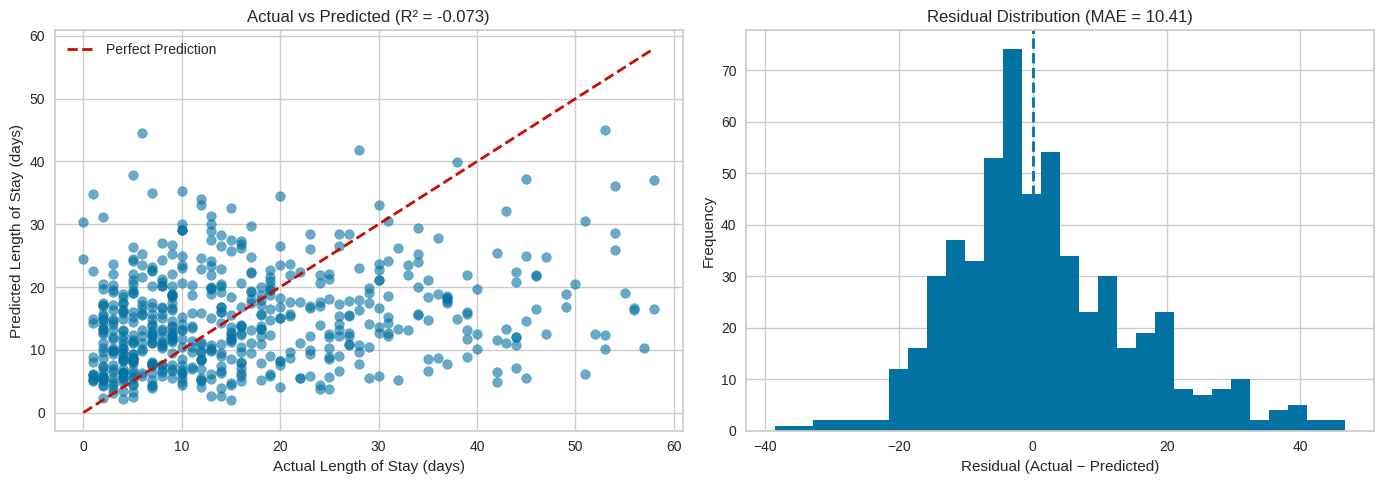


Plots saved → /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ml_test_results/model_evaluation_plots.png


<Figure size 800x550 with 0 Axes>


  Plots saved → /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ml_test_results/model_evaluation_plots.png
Predictions saved → /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ml_test_results/predictions.csv

Sample predictions:
 Actual  Predicted  Residual
   12.0       8.37      3.63
    8.0       6.52      1.48
   14.0       9.07      4.93
    0.0      30.31    -30.31
   10.0      11.67     -1.67
    6.0      16.52    -10.52
   11.0      11.36     -0.36
    5.0      15.20    -10.20
    5.0      19.03    -14.03
    4.0       2.22      1.78

✓ All results saved to: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ml_test_results


<Figure size 800x550 with 0 Axes>

In [89]:
model_path = "/home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/model_LGBM.joblib"

model = joblib.load(model_path)

%run -i /home/kyomukama/ACE/camonet/ML_Rerun/Scripts/test_model.py